# Evaluación y Análisis SHAP — IFN2+3

Nótebook unificado para los modelos entrenados con datos IFN2 y IFN3 combinados.
Análisis SHAP: beeswarm agrupado, dependencia, estructura diamétrica y stacking.

In [1]:
import os
import re
import gc
import sys
import warnings
from pathlib import Path

import joblib
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import ListedColormap
from matplotlib.ticker import MaxNLocator
from IPython.display import Image as IPImage, display as ipy_display

import shap
import torch
import torch.nn as nn
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from scipy.stats import gaussian_kde
from matplotlib.colors import Normalize
import time

warnings.filterwarnings('ignore')
%matplotlib inline

print('Imports OK')

<conda_env>/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Imports OK


In [2]:
# =============================================================================
# Clases PyTorch — necesarias para deserializar modelos .joblib
# =============================================================================

def cast_to_str(X):
    return pd.DataFrame(X).astype(str).values


class PyTorchMLPDropout(nn.Module):
    def __init__(self, input_dim, hidden_layer_sizes=(100,), activation='relu',
                 dropout_rate=0.2, use_batchnorm=True):
        super().__init__()
        layers = []
        in_dim = input_dim
        if activation == 'relu':         act_fn = nn.ReLU
        elif activation == 'tanh':       act_fn = nn.Tanh
        elif activation == 'leaky_relu': act_fn = lambda: nn.LeakyReLU(0.1)
        else:                            act_fn = nn.ReLU
        for h in hidden_layer_sizes:
            layers.append(nn.Linear(in_dim, h))
            if use_batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(act_fn())
            if dropout_rate > 0: layers.append(nn.Dropout(dropout_rate))
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)


class MLPRegressorTorch(BaseEstimator, RegressorMixin):
    def __init__(self, hidden_layer_sizes=(100,), activation='relu', solver='adam',
                 alpha=1e-4, learning_rate_init=1e-3, max_iter=200, batch_size=256,
                 dropout_rate=0.2, use_batchnorm=True, device='cpu', verbose=False):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.activation = activation
        self.solver = solver
        self.alpha = alpha
        self.learning_rate_init = learning_rate_init
        self.max_iter = max_iter
        self.batch_size = batch_size
        self.dropout_rate = dropout_rate
        self.use_batchnorm = use_batchnorm
        self.device = device
        self.verbose = verbose
        self.model_ = None

    def predict(self, X):
        if self.model_ is None:
            raise RuntimeError('Model not fitted')
        self.model_.eval()
        self.model_.to(self.device)
        X_t = torch.tensor(pd.DataFrame(X).values, dtype=torch.float32).to(self.device)
        with torch.no_grad():
            return self.model_(X_t).cpu().numpy().flatten()


import __main__
__main__.cast_to_str = cast_to_str
__main__.PyTorchMLPDropout = PyTorchMLPDropout
__main__.MLPRegressorTorch = MLPRegressorTorch

print('Clases PyTorch OK — spoofing listo')

Clases PyTorch OK — spoofing listo


In [3]:
# =============================================================================
# Rutas y configuración
# =============================================================================

BASE = Path('../../../')

DATA_PATH              = BASE / 'data/processed/ifn_entrenamiento_year_agrupado_periodo_completado_2.csv'
MODELS_IFN23_C4        = BASE / 'models/artifacts/IFN2-3/c4/base'
MODELS_IFN23_CB4       = BASE / 'models/artifacts/IFN2-3/carbono_bruto4/base'
MODELS_IFN23_C4_STACK  = BASE / 'models/artifacts/IFN2-3/c4/stackings'
MODELS_IFN23_CB4_STACK = BASE / 'models/artifacts/IFN2-3/carbono_bruto4/stackings'
OUTPUT_SHAP            = BASE / 'figures/shap_ifn2_3'
CACHE_SHAP             = OUTPUT_SHAP / 'cache'
OUTPUT_SHAP.mkdir(parents=True, exist_ok=True)
CACHE_SHAP.mkdir(parents=True, exist_ok=True)

MAPA_PENDIENTE = {
    'muy suave (<5°)': 0, 'suave (5-10°)': 1, 'moderada (10-15°)': 2,
    'fuerte (15-20°)': 3, 'muy fuerte (20-30°)': 4,
    'escarpada (30-50°)': 5, 'extrema (>50°)': 6
}
MAPA_ORIENTACION = {'N': 0, 'NE': 1, 'E': 2, 'SE': 3, 'S': 4, 'SO': 5, 'O': 6, 'NO': 7}

FEATURES_C4 = [
    'especie_id', 'tipo_especie', 'periodo_agrupado', 'radio', 'ocupa',
    'npies_1', 'npies_2', 'npies_5', 'npies_10', 'npies_15', 'npies_20',
    'npies_25', 'npies_30', 'npies_35', 'npies_40', 'npies_45', 'npies_50',
    'npies_55', 'npies_60', 'npies_65', 'npies_70',
    'estado_id', 'fccarb', 'disesp_id', 'modcomb_id', 'nivel2_id', 'tratmasa_id',
    'rocosidad_id', 'orientacion_cat', 'elevacion', 'pendiente_cat', 'martonneidx_id',
    'skt_mean_primavera', 'pr_sum_primavera', 'skt_std_verano', 'skt_std_primavera',
    'pr_sum_otoño', 'skt_mean_verano', 'pr_sum_verano', 'pr_sum_invierno',
    'gndvi_mean_verano', 'ndii_mean_primavera', 'gndvi_std_primavera', 'evi_mean_primavera'
]

FEATURES_CB4 = [
    'especie_id', 'tipo_especie', 'periodo_agrupado', 'radio', 'ocupa',
    'npies_1', 'npies_2', 'npies_5', 'npies_10', 'npies_15', 'npies_20',
    'npies_25', 'npies_30', 'npies_35', 'npies_40', 'npies_45', 'npies_50',
    'npies_55', 'npies_60', 'npies_65', 'npies_70',
    'estado_id', 'fccarb', 'disesp_id', 'modcomb_id', 'nivel2_id', 'tratmasa_id',
    'rocosidad_id', 'orientacion_cat', 'elevacion', 'pendiente_cat', 'martonneidx_id',
    'gndvi_mean_verano', 'ndii_mean_primavera', 'gndvi_std_primavera', 'evi_mean_primavera'
]

VARS_CATEGORICAS = [
    'especie_id', 'tipo_especie', 'estado_id', 'disesp_id',
    'modcomb_id', 'nivel2_id', 'tratmasa_id', 'rocosidad_id',
    'martonneidx_id', 'orientacion_cat', 'pendiente_cat'
]

# Variables categóricas con orden significativo → color = valor real (no carbono medio)
VARS_ORDINALES = {'rocosidad_id', 'martonneidx_id', 'estado_id', 'tratmasa_id', 'pendiente_cat'}

STACK_CONFIGS = {
    'Stack1': ['LightGBM', 'Random_Forest'],
    'Stack2': ['LightGBM', 'XGBoost', 'GBDT'],
    'Stack3': ['CatBoost', 'Random_Forest', 'GBDT'],
    'Stack4': ['CatBoost', 'LightGBM', 'Random_Forest', 'GBDT'],
    'Stack5': ['CatBoost', 'LightGBM', 'XGBoost', 'Random_Forest', 'GBDT', 'BaggedDT'],
}

print(f'Datos:            {DATA_PATH}')
print(f'Modelos c4:       {MODELS_IFN23_C4}')
print(f'Modelos cb4:      {MODELS_IFN23_CB4}')
print(f'Stackings c4:     {MODELS_IFN23_C4_STACK}')
print(f'Stackings cb4:    {MODELS_IFN23_CB4_STACK}')
print(f'Figuras SHAP:     {OUTPUT_SHAP}')
# Directorios para summary + force plots (IFN2-3)
OUT_SUMMARY = BASE / 'figures/shap_summary_ifn2_3'
OUT_FORCE   = BASE / 'figures/shap_force_ifn2_3'
OUT_SUMMARY.mkdir(parents=True, exist_ok=True)
OUT_FORCE.mkdir(parents=True, exist_ok=True)

# CONFIGS para summary/force plots
CONFIGS_SF = {
    'c4':             {'features': FEATURES_C4,  'unit': 'tC/ha',
                      'models':   MODELS_IFN23_C4},
    'carbono_bruto4': {'features': FEATURES_CB4, 'unit': 'tC',
                      'models':   MODELS_IFN23_CB4},
}

print(f'Caché SHAP:       {CACHE_SHAP}')

Datos:            ../../data/processed/ifn_entrenamiento_year_agrupado_periodo_completado_2.csv
Modelos c4:       ../../models/artifacts/IFN2-3/c4/base
Modelos cb4:      ../../models/artifacts/IFN2-3/carbono_bruto4/base
Stackings c4:     ../../models/artifacts/IFN2-3/c4/stackings
Stackings cb4:    ../../models/artifacts/IFN2-3/carbono_bruto4/stackings
Figuras SHAP:     ../../figures/shap_ifn2_3
Caché SHAP:       ../../figures/shap_ifn2_3/cache


## Tratamiento de variables categóricas en el análisis SHAP

Las variables categóricas se codifican con **One-Hot Encoding (OHE)** antes de entrar al modelo,
generando una columna binaria por cada categoría. En los gráficos SHAP, los valores de cada variable
se **reagrupan** sumando las contribuciones SHAP de todas sus columnas OHE (etiqueta con `*`).

El **color** de cada punto en el beeswarm y violín indica el valor de la variable en esa muestra,
pero su interpretación varía según el tipo de variable:

### Variables agrupadas ordinales — color = valor real de la variable
El valor numérico tiene un orden significativo: un número mayor implica mayor intensidad del fenómeno.

| Variable | Escala |
|---|---|
| `estado_id*` | 1 = Repoblado → 4 = Fustal (madurez del bosque) |
| `rocosidad_id*` | 1 = Sin pedregosidad → 5 = Roquedo |
| `martonneidx_id*` | 1 = Zona árida → 6 = Zona perhúmeda |
| `tratmasa_id*` | 1 = Monte alto → 3 = Monte bajo |
| `tipo_especie*` | 0 = Conífera (azul), 1 = Frondosa (rojo) — binaria, color directo |

### Variables agrupadas nominales — color = carbono medio del dataset para esa categoría
El valor numérico es un identificador sin orden intrínseco. El color refleja el carbono medio
observado en el dataset para la categoría concreta de cada muestra (calculado sobre todos los datos
antes del split train/test).

| Variable | Descripción |
|---|---|
| `especie_id*` | Especie arbórea (OHE con ~190 categorías) |
| `disesp_id*` | Distribución espacial de la masa |
| `modcomb_id*` | Modelo de combustible (13 tipos) |
| `nivel2_id*` | Nivel morfoestructural del monte |
| `orientacion_cat*` | Orientación cardinal (N/NE/E/SE/S/SO/O/NO) — circular, sin orden lineal |
| `pendiente_cat*` | Clase de pendiente — ordinal en campo, pero tratada como nominal por ser OHE |

### Variable especial: `npies* (Densidad)`
Agrupa las 16 columnas `npies_1` a `npies_70` (número de pies por hectárea por clase diamétrica).
El color es la **suma de los valores normalizados por columna** [0,1]: cada clase diamétrica
contribuye por igual, evitando que `npies_1` (siempre el mayor por ser acumulativo) domine el color.

### Variables continuas — color = valor real normalizado
El resto de variables (`elevacion`, `radio`, `ocupa`, `fccarb`, `periodo_agrupado`, variables
climáticas y de teledetección) usan directamente su valor normalizado como color.


In [4]:
# =============================================================================
# Funciones auxiliares
# =============================================================================

def get_feature_names(preprocessor):
    import math

    def _is_nan(v):
        try: return math.isnan(v)
        except: return False

    try:
        return list(preprocessor.get_feature_names_out())
    except Exception:
        names = []
        for name, step, cols in preprocessor.transformers_:
            if name == 'remainder' and step == 'drop':
                continue
            # Detectar columnas eliminadas por SimpleImputer (statistics_ = NaN
            # para columnas completamente vacías en entrenamiento)
            surviving = list(cols)
            if isinstance(step, Pipeline):
                for _, est in step.steps:
                    if hasattr(est, 'statistics_'):
                        surviving = [c for c, v in zip(surviving, est.statistics_)
                                     if not _is_nan(v)]
                        break
            s = step.steps[-1][1] if isinstance(step, Pipeline) else step
            if isinstance(s, OneHotEncoder) and hasattr(s, 'categories_'):
                for col, cats in zip(surviving, s.categories_):
                    names.extend([f'{col}_{c}' for c in cats])
            else:
                names.extend(surviving)
        return names


def compute_shap(pipeline, X_raw, X_bg_raw, model_name):
    preprocessor = pipeline.named_steps['preprocessor']
    model = pipeline.named_steps['regressor']

    feat_names = get_feature_names(preprocessor)
    X_trans = preprocessor.transform(X_raw)
    if X_trans.shape[1] != len(feat_names):
        feat_names = [f'f_{i:03d}' for i in range(X_trans.shape[1])]
    X_df = pd.DataFrame(X_trans, columns=feat_names)

    tree_types = ['XGBoost', 'LightGBM', 'CatBoost', 'Random_Forest', 'GBDT', 'BaggedDT', 'AdaBoost']
    use_tree = any(t in model_name for t in tree_types)

    if use_tree:
        try:
            explainer = shap.TreeExplainer(model)
            shap_vals = explainer.shap_values(X_df)
            X_used_df = X_df
            X_used_raw = X_raw
        except Exception:
            use_tree = False

    if not use_tree:
        bg_trans = preprocessor.transform(X_bg_raw)
        bg = shap.kmeans(pd.DataFrame(bg_trans, columns=feat_names), 10)
        n = min(100, len(X_df))
        X_used_df = X_df.iloc[:n]
        X_used_raw = X_raw.iloc[:n]
        explainer = shap.KernelExplainer(model.predict, bg)
        shap_vals = explainer.shap_values(X_used_df)

    if isinstance(shap_vals, list):
        shap_vals = shap_vals[0]
    base_val = explainer.expected_value
    if isinstance(base_val, (list, np.ndarray)):
        base_val = float(base_val[0])

    return shap_vals, feat_names, X_used_df, X_used_raw, base_val


def load_or_compute_shap(model_path, X_raw, X_bg_raw, model_name, cache_path=None):
    if cache_path is not None:
        cache_path = Path(cache_path)
        if cache_path.exists():
            print(f'[caché] ', end='')
            d = joblib.load(cache_path)
            return d['shap_vals'], d['feat_names'], d['X_trans_df'], d['X_raw_used'], d['base_val']

    pipeline = None
    try:
        pipeline = joblib.load(model_path)
        result = compute_shap(pipeline, X_raw, X_bg_raw, model_name)
    finally:
        if pipeline is not None:
            del pipeline
        gc.collect()

    if cache_path is not None:
        cache_path.parent.mkdir(parents=True, exist_ok=True)
        joblib.dump({
            'shap_vals':  result[0],
            'feat_names': result[1],
            'X_trans_df': result[2],
            'X_raw_used': result[3],
            'base_val':   result[4],
        }, cache_path, compress=3)

    return result


# Colores para etiquetas de variables en los gráficos SHAP
COLOR_VAR_CONT    = '#212121'  # Variables continuas — negro
COLOR_VAR_NPIES   = '#00897b'  # npies* (Densidad) — teal
COLOR_VAR_ORDINAL = '#e65100'  # Categóricas ordinales — naranja oscuro
COLOR_VAR_NOMINAL = '#6a1b9a'  # Categóricas nominales — morado oscuro

def group_shap_explanation(shap_vals, feat_names, X_raw_used, X_trans_df, target_means_maps):
    f_shap, f_data, f_names, f_colors = [], [], [], []
    processed = set()

    npies_idx = [i for i, f in enumerate(feat_names) if f.startswith('npies')]
    if npies_idx:
        f_shap.append(np.sum(shap_vals[:, npies_idx], axis=1))
        npies_cols = [c for c in X_raw_used.columns if 'npies' in c]
        npies_df = X_raw_used[npies_cols].astype(float)
        col_min = npies_df.min(); col_max = npies_df.max()
        npies_norm = (npies_df - col_min) / (col_max - col_min + 1e-12)
        f_data.append(npies_norm.sum(axis=1).values)
        f_names.append('npies* (Density)')
        f_colors.append(COLOR_VAR_NPIES)
        processed.update(npies_idx)

    for cat in VARS_CATEGORICAS:
        idx = [
            i for i, f in enumerate(feat_names)
            if (f == cat or f.startswith(cat + '_') or f.startswith(cat + '.'))
            and i not in processed
        ]
        if not idx:
            continue
        f_shap.append(np.sum(shap_vals[:, idx], axis=1))
        if cat in X_raw_used.columns:
            if cat in VARS_ORDINALES:
                f_data.append(X_raw_used[cat].values.astype(float))
                f_colors.append(COLOR_VAR_ORDINAL)
            else:
                mapping = target_means_maps.get(cat, {})
                f_data.append(np.array([mapping.get(v, 0.0) for v in X_raw_used[cat].values]))
                f_colors.append(COLOR_VAR_NOMINAL)
        else:
            f_data.append(np.zeros(shap_vals.shape[0]))
            f_colors.append(COLOR_VAR_NOMINAL)
        f_names.append(f'{cat}*')
        processed.update(idx)

    for i, fname in enumerate(feat_names):
        if i in processed:
            continue
        f_shap.append(shap_vals[:, i])
        if fname in X_raw_used.columns:
            f_data.append(X_raw_used[fname].values)
        else:
            f_data.append(X_trans_df.iloc[:, i].values)
        f_names.append(fname)
        f_colors.append(COLOR_VAR_CONT)

    return np.column_stack(f_shap), np.column_stack(f_data), f_names, f_colors


print('Funciones auxiliares OK')

# Alias para compatibilidad con sección de summary plots
group_shap = group_shap_explanation


Funciones auxiliares OK


In [5]:
# =============================================================================
# Carga de datos IFN2-3 (todos los inventarios, sin filtro de IFN)
# =============================================================================

def load_ifn23_data(target, features):
    print(f'Cargando datos para target={target}...')
    df = pd.read_csv(DATA_PATH)
    # IFN2-3: sin filtro de inventario — se usan todos los datos

    df['pendiente_cat']   = df['pendiente_cat'].map(MAPA_PENDIENTE)
    df['orientacion_cat'] = df['orientacion_cat'].map(MAPA_ORIENTACION)

    mask = (df[target].notna()) & (df[target] != 0)
    if target == 'carbono_bruto4':
        mask &= (df['c'].isna()) | (df['c'] < df[target])
        df_work = df[mask].copy()
        df_work = df_work[~(df_work['fccarb'].notna() & (df_work['fccarb'] < 20))].copy()
    else:
        df_work = df[mask].copy()

    target_means_maps = {}
    for col in VARS_CATEGORICAS:
        if col in df_work.columns:
            target_means_maps[col] = df_work.groupby(col)[target].mean().to_dict()

    present = [c for c in features if c in df_work.columns]
    X = df_work[present].copy().astype('float32')
    y = df_work[target].copy().astype('float32')

    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    _, te_idx = next(gss.split(X, y, groups=df_work['parcela_id']))
    X_test = X.iloc[te_idx].copy()

    print(f'  IFN2-3 | target={target} | test set: {len(X_test)} muestras')
    return X_test, target_means_maps


X_test_c4,  tm_c4  = load_ifn23_data('c4',            FEATURES_C4)
X_test_cb4, tm_cb4 = load_ifn23_data('carbono_bruto4', FEATURES_CB4)

X_sample_c4  = X_test_c4.sample(200, random_state=42)  if len(X_test_c4)  > 200 else X_test_c4
X_bg_c4      = X_test_c4.sample(50,  random_state=42)  if len(X_test_c4)  > 50  else X_test_c4
X_sample_cb4 = X_test_cb4.sample(200, random_state=42) if len(X_test_cb4) > 200 else X_test_cb4
X_bg_cb4     = X_test_cb4.sample(50,  random_state=42) if len(X_test_cb4) > 50  else X_test_cb4

print('\nDatos listos.')

Cargando datos para target=c4...
  IFN2-3 | target=c4 | test set: 26028 muestras
Cargando datos para target=carbono_bruto4...
  IFN2-3 | target=carbono_bruto4 | test set: 26664 muestras

Datos listos.


---
## 1. SHAP Beeswarm Agrupado — c4 (IFN2-3)

Modelos c4 a procesar: 9
  [OK] BaggedDT


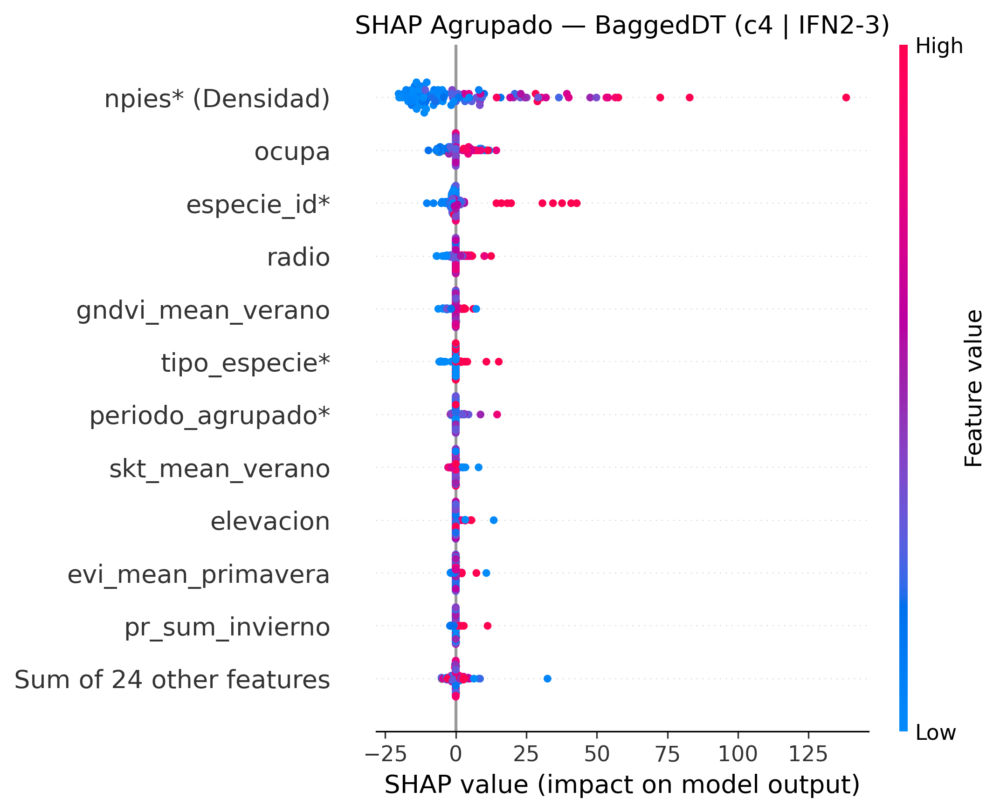

  [OK] BayesianNN


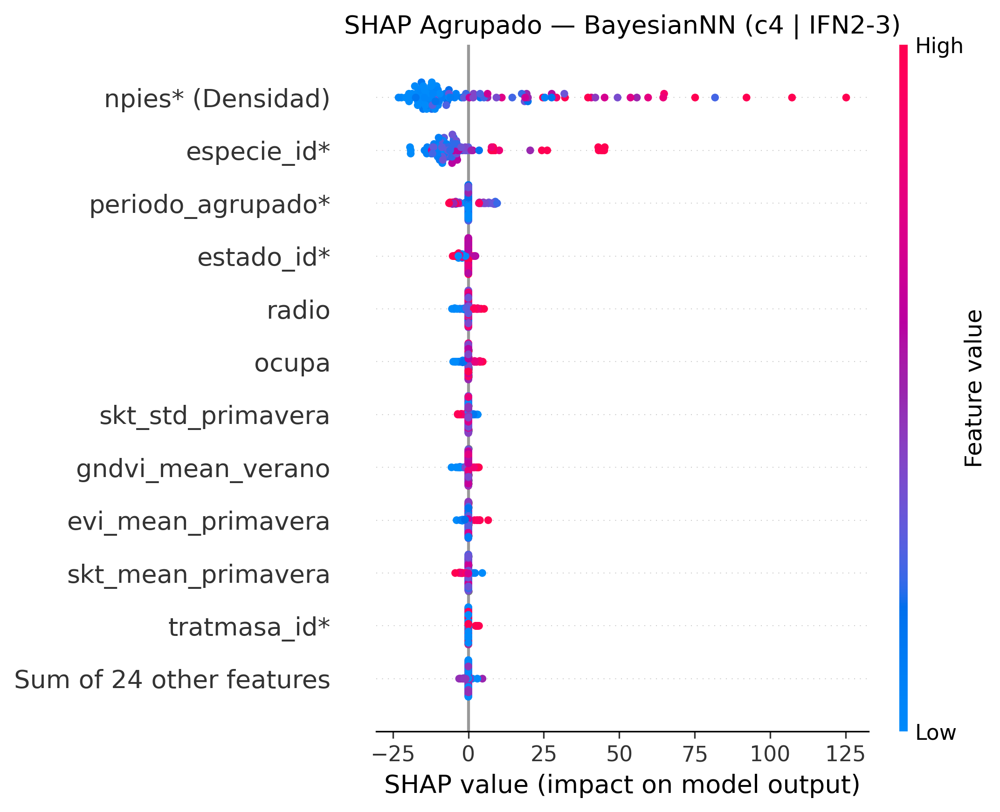

  [OK] CatBoost


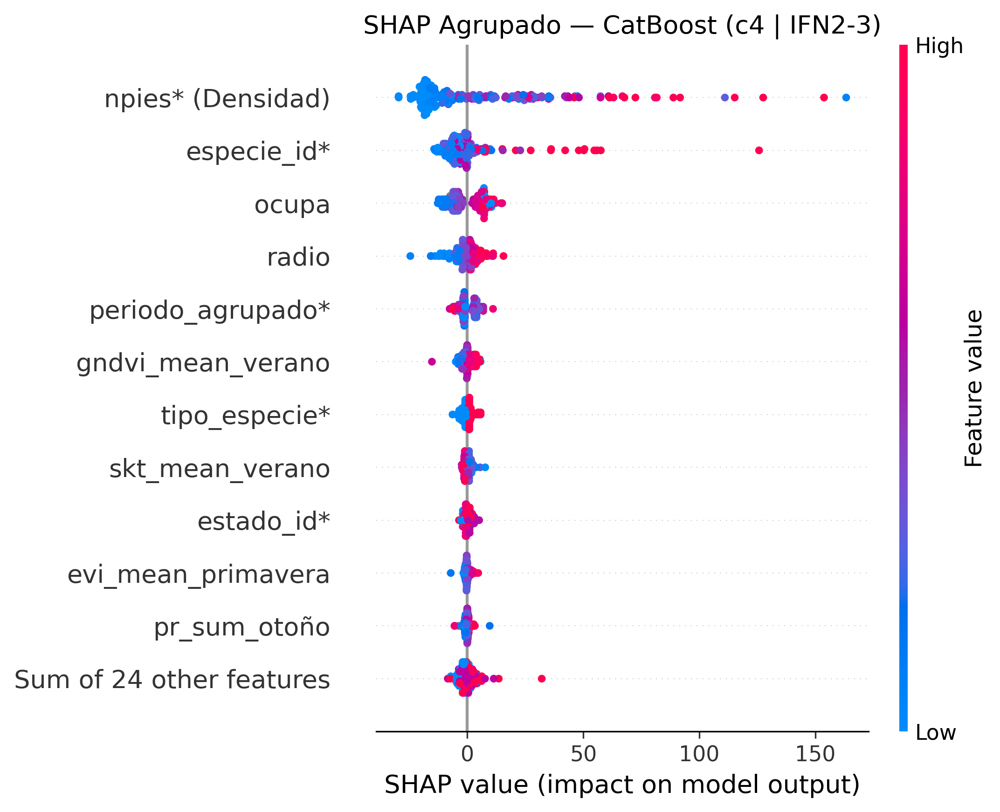

  [OK] GBDT


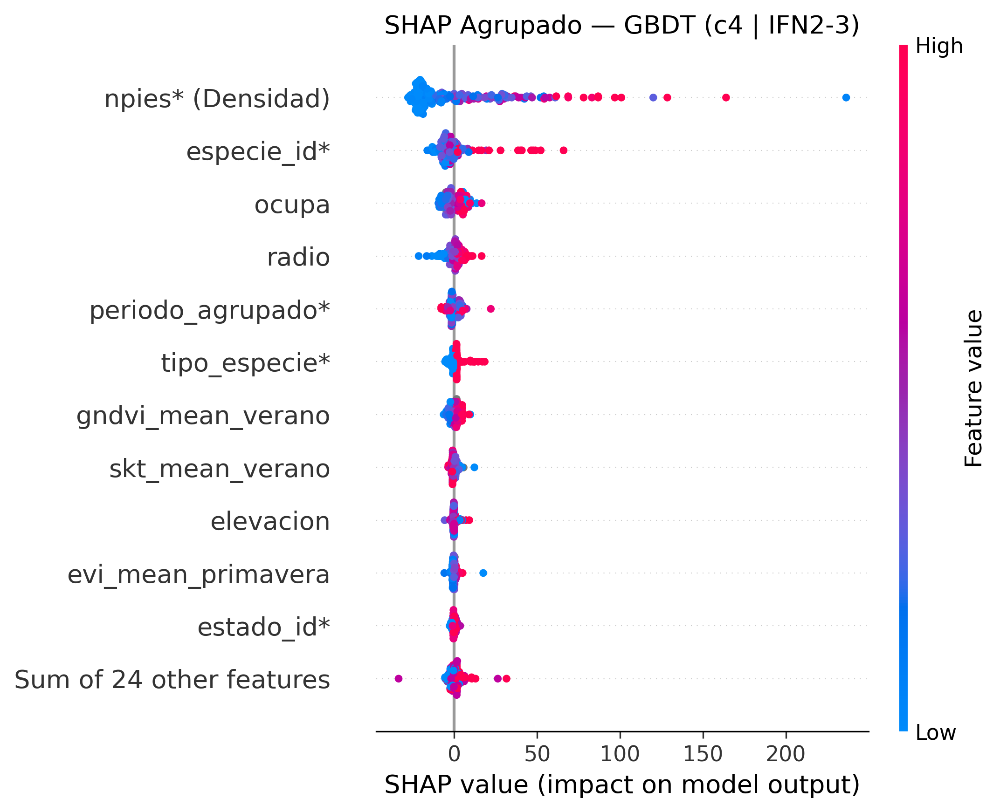

  [OK] LightGBM


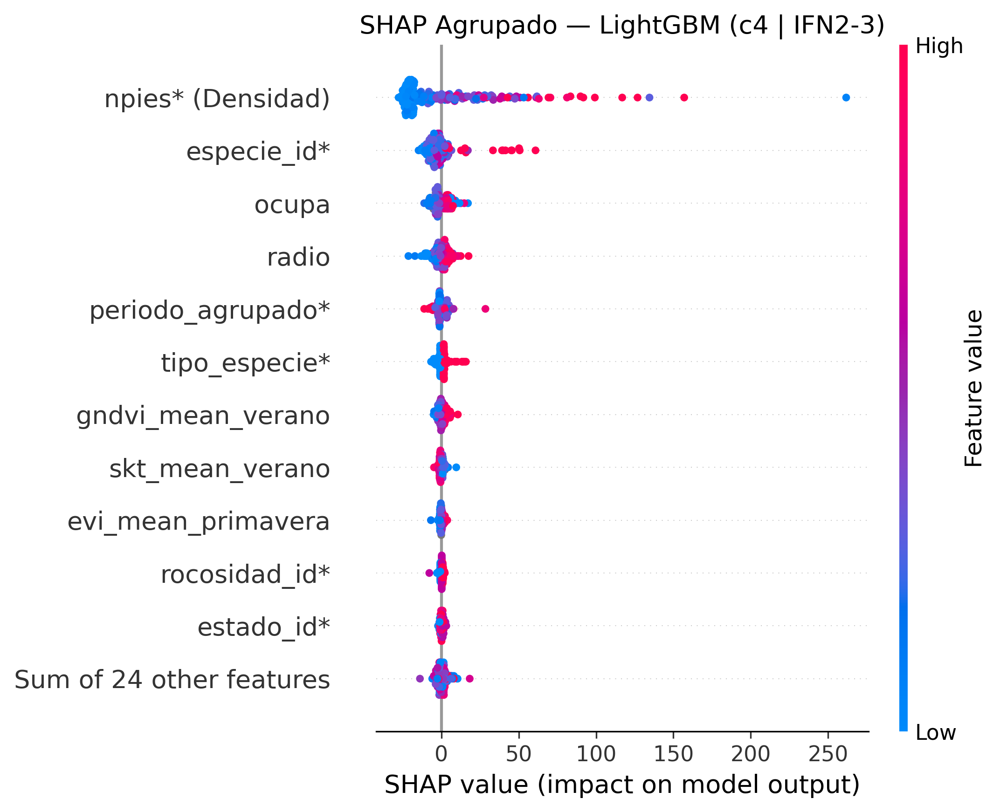

  [OK] MLP_PyTorch


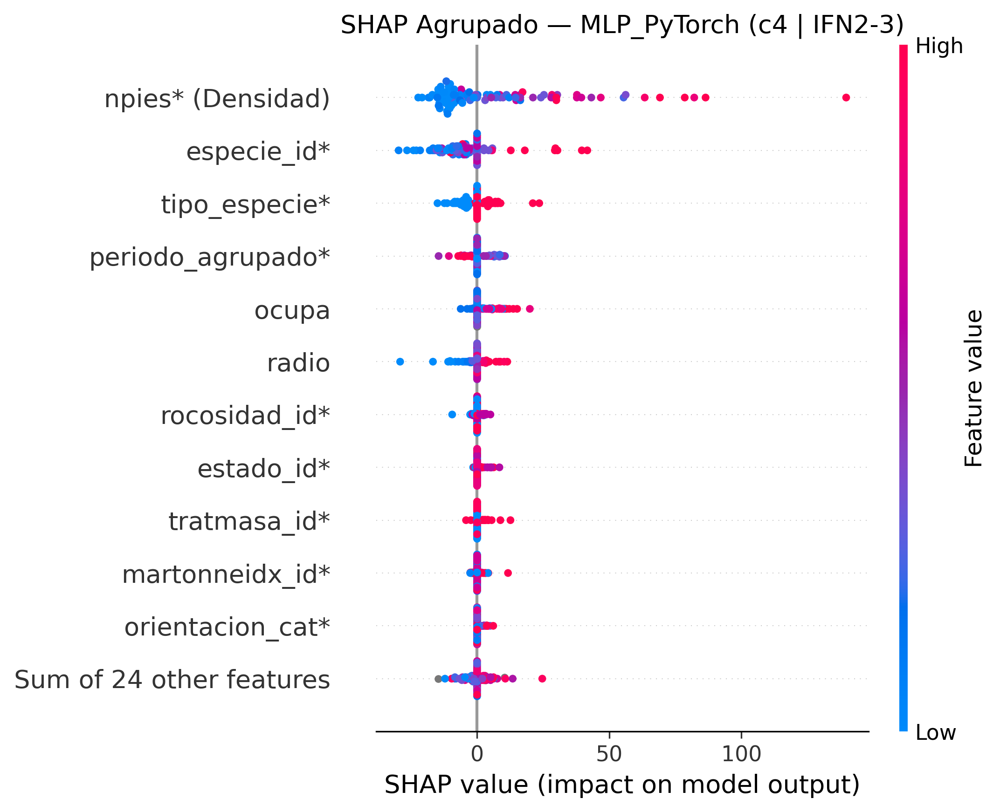

  [OK] Random_Forest


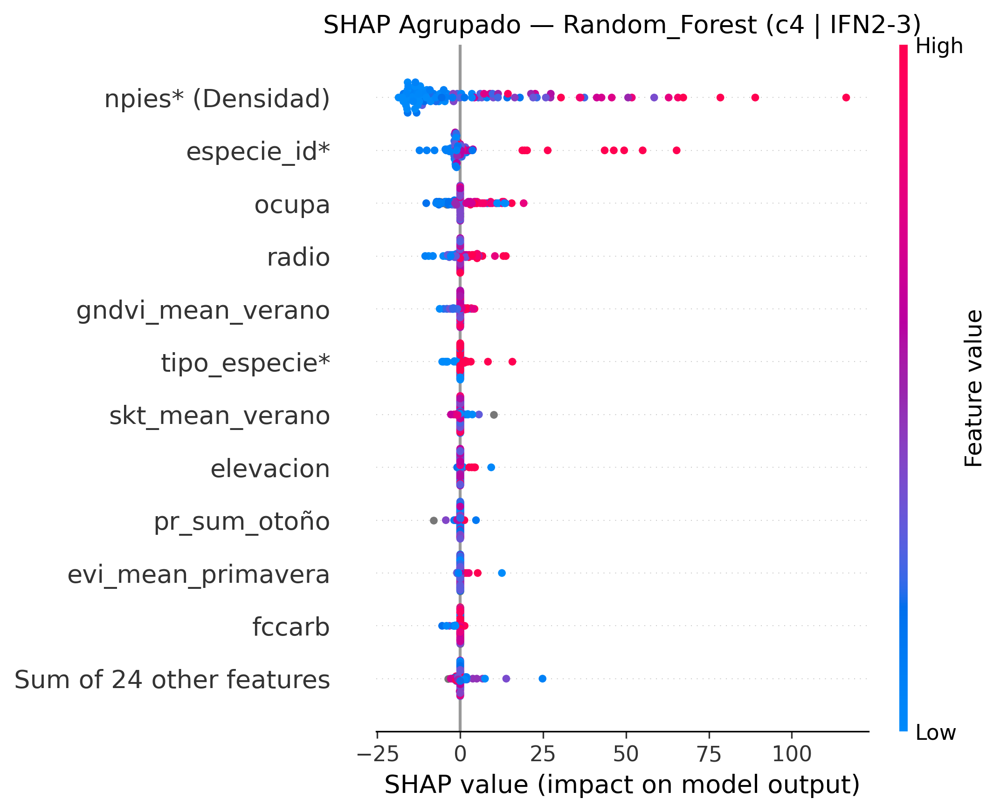

  [OK] SVR


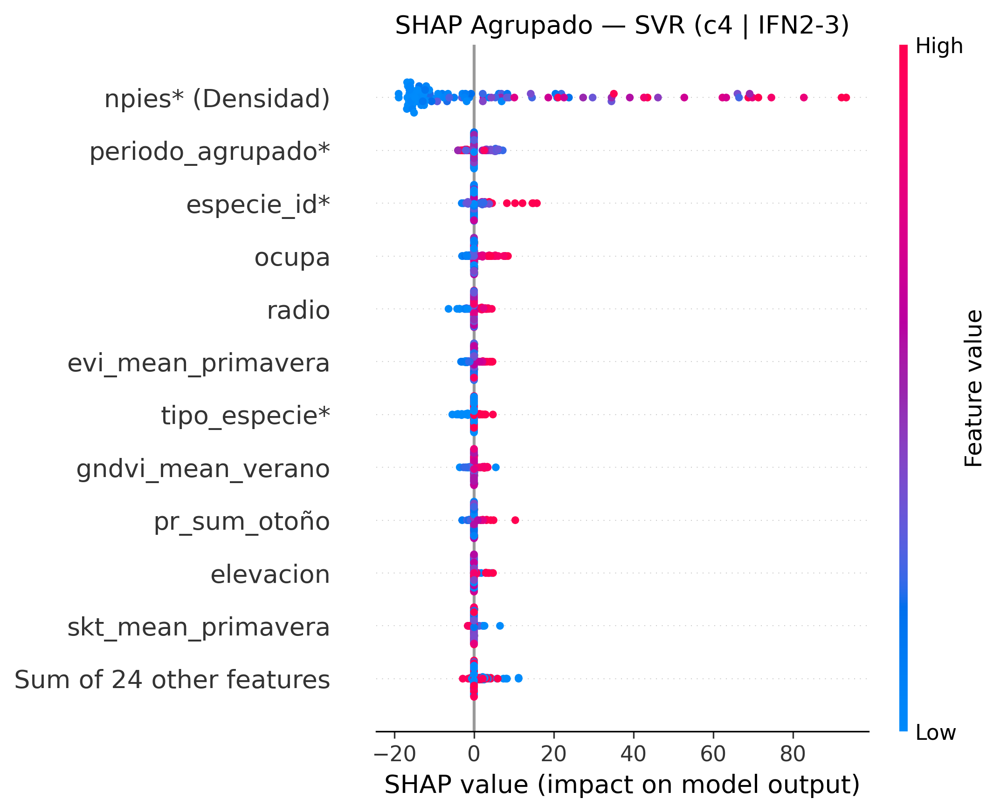

  [OK] XGBoost


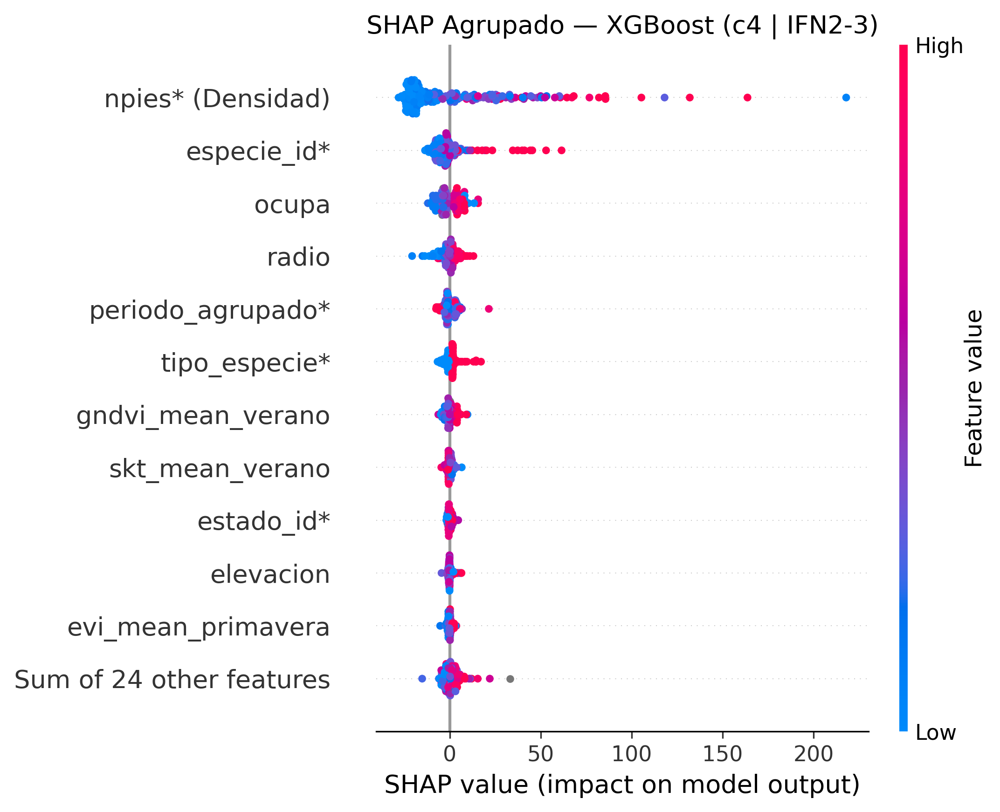


Seccion 1 completada.


In [6]:
model_files_c4 = sorted(
    f for f in os.listdir(MODELS_IFN23_C4)
    if f.endswith('.joblib') and 'training_context' not in f and 'test_indices' not in f
)

out_dir_c4 = OUTPUT_SHAP / 'c4' / 'beeswarm_grouped'
out_dir_c4.mkdir(parents=True, exist_ok=True)

print(f'Modelos c4 a procesar: {len(model_files_c4)}')

for fname in model_files_c4:
    model_name = fname.replace('.joblib', '')
    model_path = MODELS_IFN23_C4 / fname
    save_path  = out_dir_c4 / f'beeswarm_grouped_{model_name}.png'
    cache_path = CACHE_SHAP / 'base' / 'c4' / f'{model_name}.joblib'

    if save_path.exists() and save_path.with_suffix('.pdf').exists():
        print(f'  [OK] {model_name}')
        ipy_display(IPImage(str(save_path)))
        continue

    print(f'  {model_name}...', end=' ')
    try:
        shap_vals, feat_names, X_trans_df, X_raw_used, base_val = load_or_compute_shap(
            model_path, X_sample_c4, X_bg_c4, model_name, cache_path=cache_path
        )
        shap_g, data_g, names_g = group_shap_explanation(
            shap_vals, feat_names, X_raw_used, X_trans_df, tm_c4
        )
        explanation = shap.Explanation(
            values=shap_g, base_values=base_val,
            data=data_g, feature_names=names_g
        )
        fig, ax = plt.subplots(figsize=(10, 8))
        shap.plots.beeswarm(explanation, max_display=12, show=False)
        plt.title(f'SHAP Agrupado — {model_name} (c4 | IFN2-3)', fontsize=13)
        plt.subplots_adjust(left=0.35, bottom=0.10)
        print(f'  -> {save_path}')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
        plt.show()
        plt.close()
        print('OK')
    except Exception as e:
        print(f'ERROR: {e}')
    finally:
        gc.collect()

print('\nSeccion 1 completada.')

---
## 2. SHAP Beeswarm Agrupado — carbono\_bruto4 (IFN2-3)

Modelos carbono_bruto4 a procesar: 9
  [OK] BaggedDT


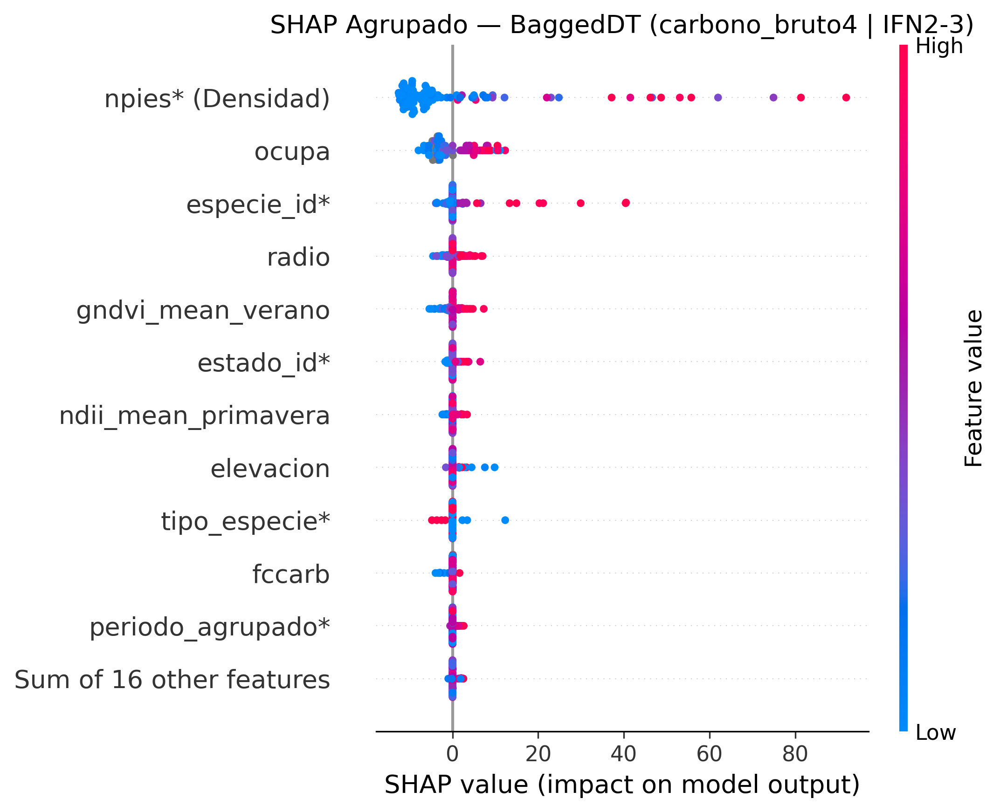

  [OK] BayesianNN


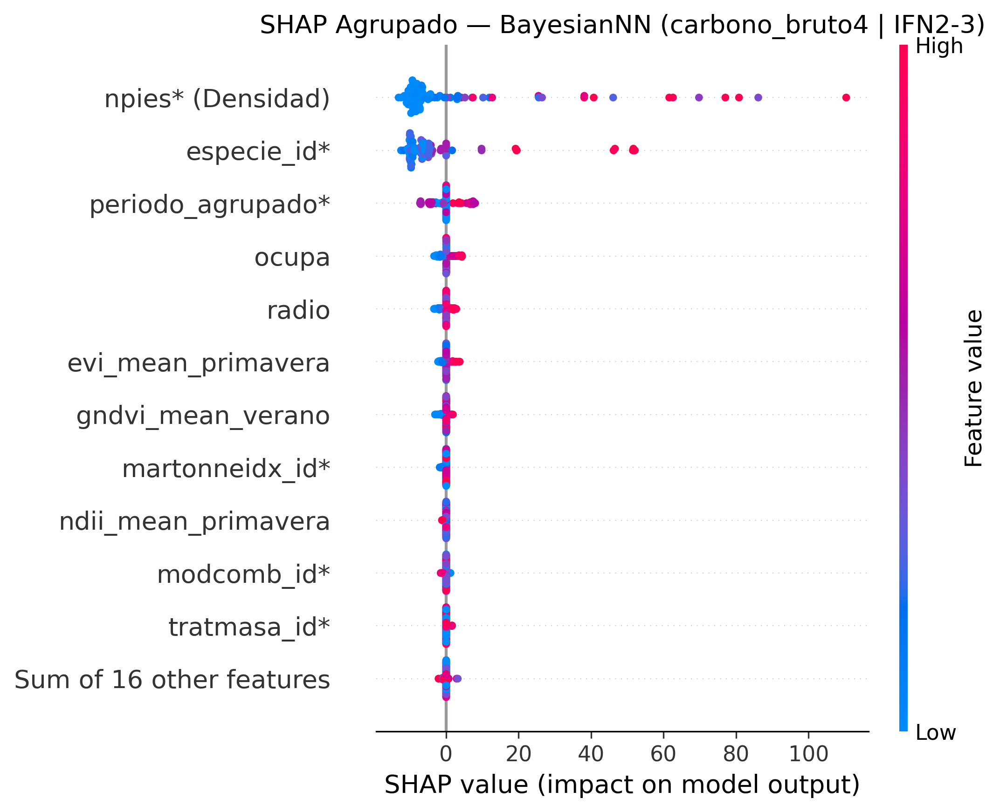

  [OK] CatBoost


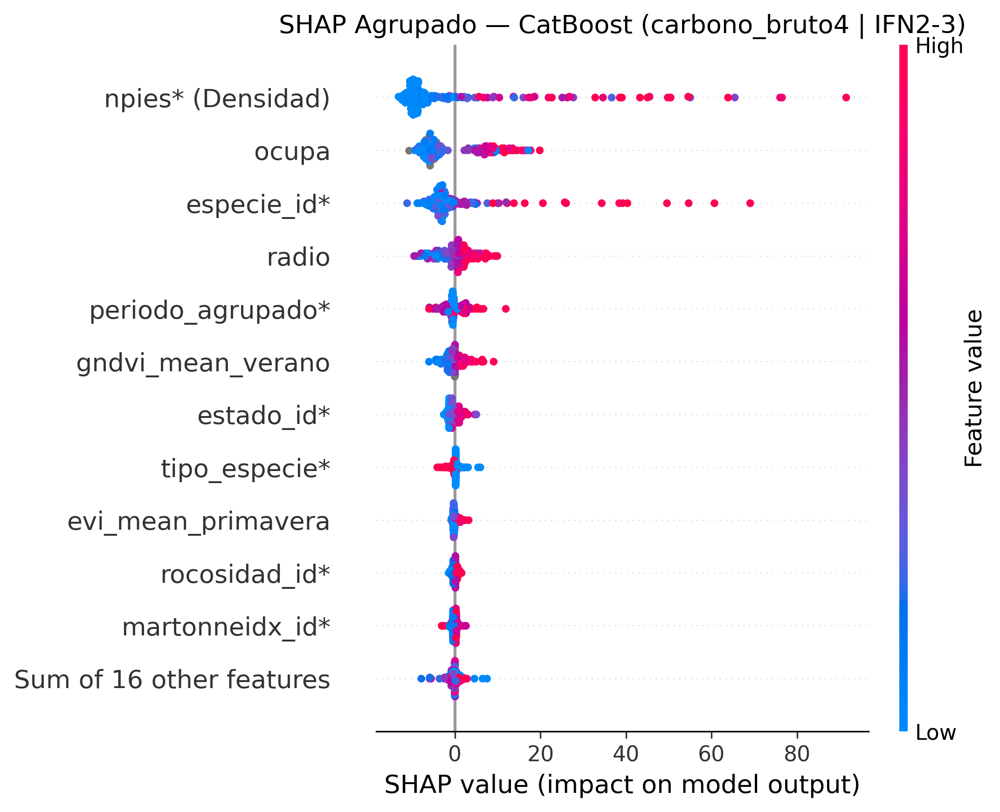

  [OK] GBDT


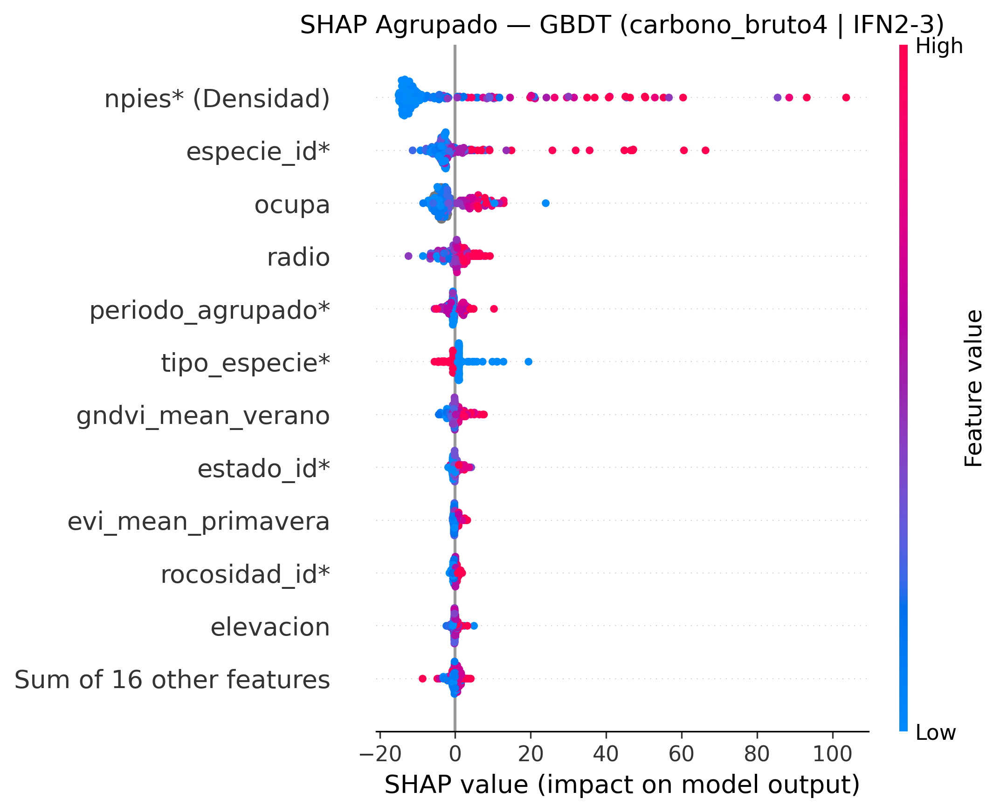

  [OK] LightGBM


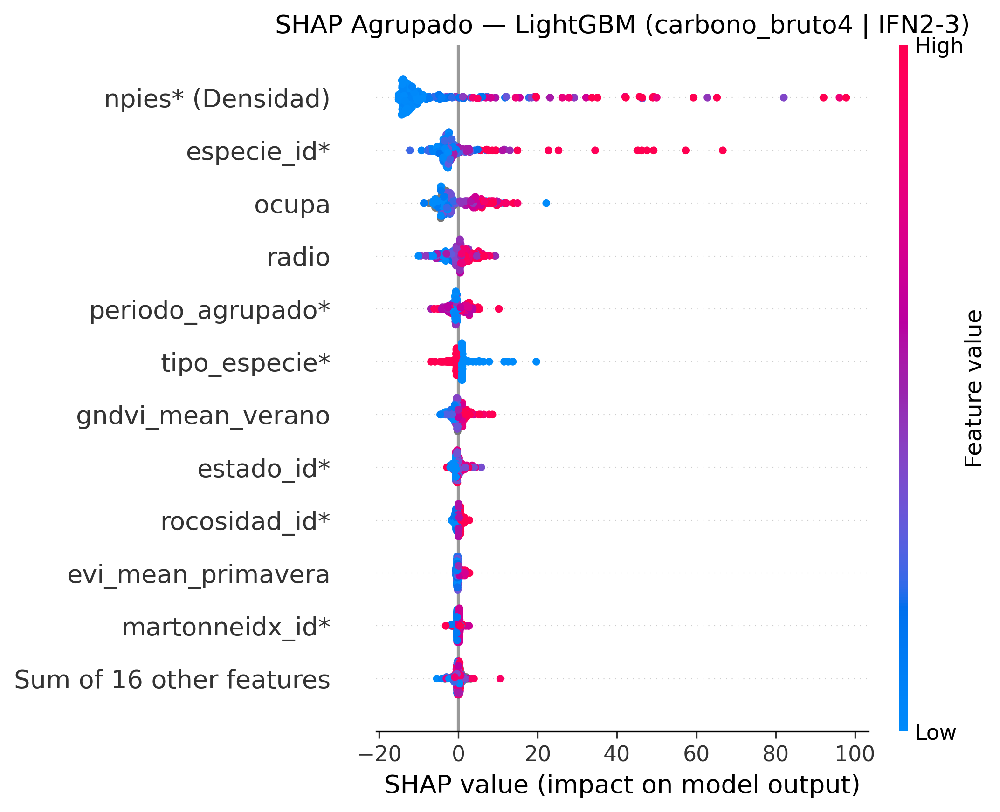

  [OK] MLP_PyTorch


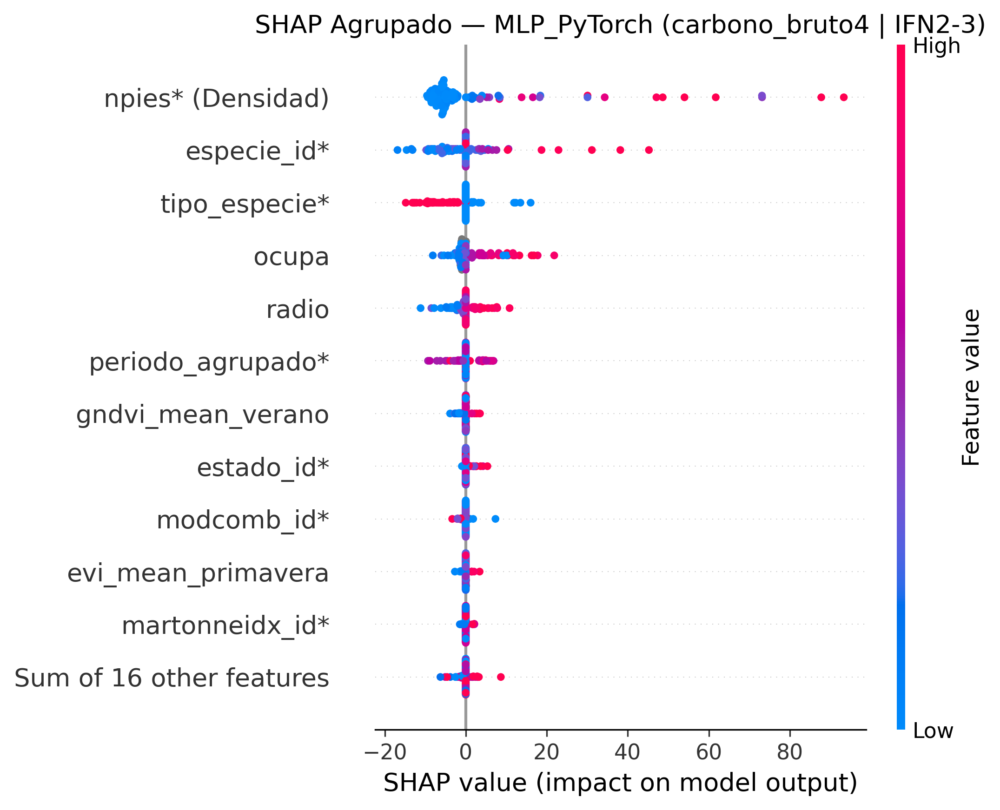

  [OK] Random_Forest


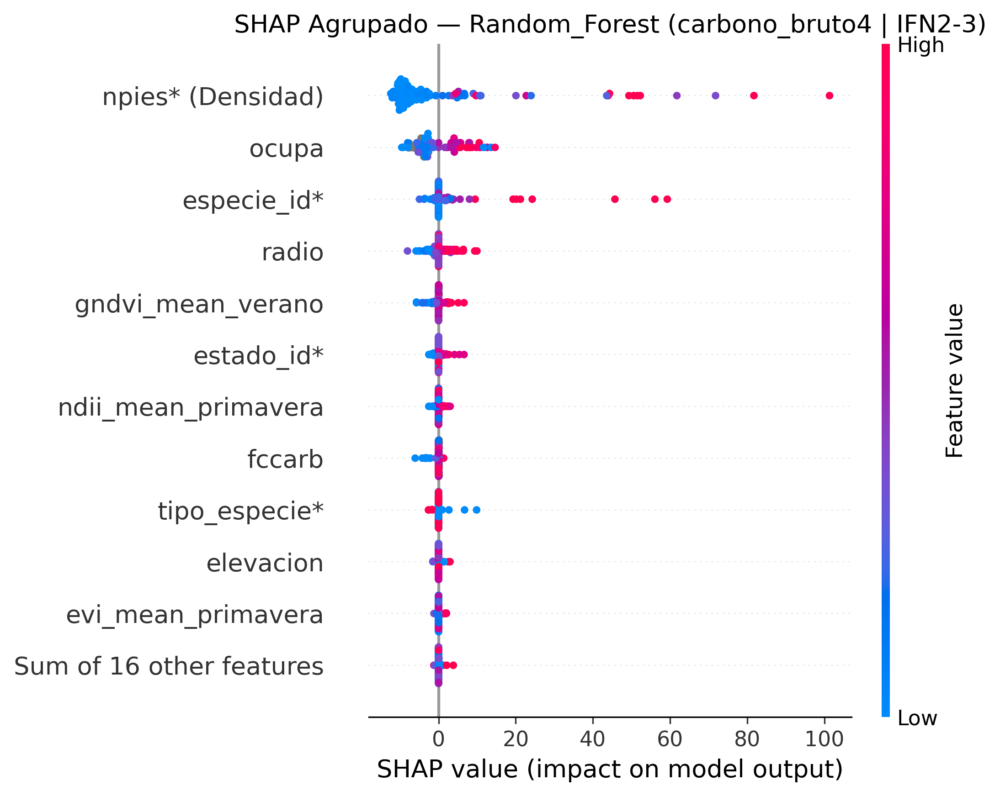

  [OK] SVR


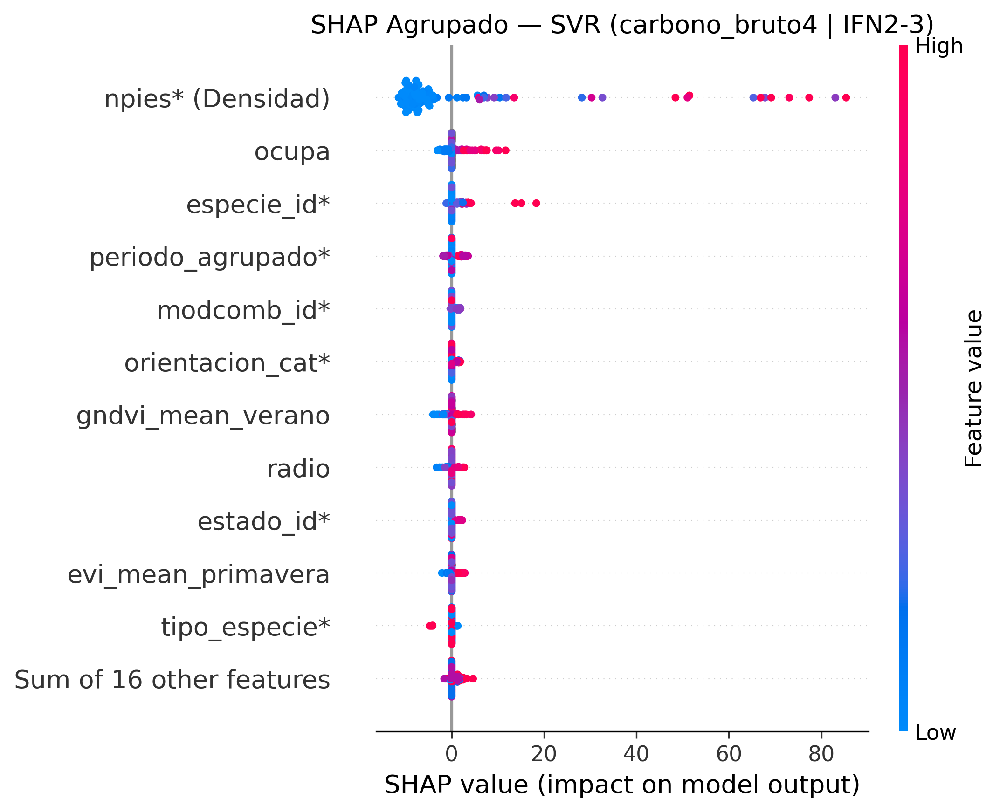

  [OK] XGBoost


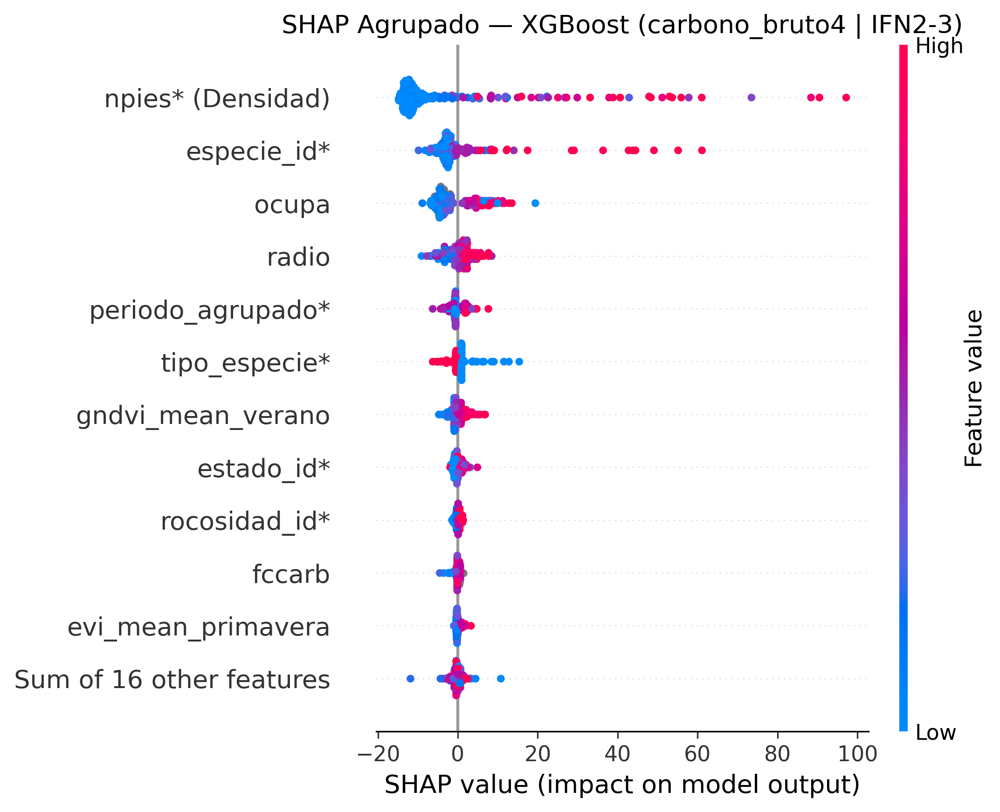


Seccion 2 completada.


In [7]:
model_files_cb4 = sorted(
    f for f in os.listdir(MODELS_IFN23_CB4)
    if f.endswith('.joblib') and 'training_context' not in f and 'test_indices' not in f
)

out_dir_cb4 = OUTPUT_SHAP / 'carbono_bruto4' / 'beeswarm_grouped'
out_dir_cb4.mkdir(parents=True, exist_ok=True)

print(f'Modelos carbono_bruto4 a procesar: {len(model_files_cb4)}')

for fname in model_files_cb4:
    model_name = fname.replace('.joblib', '')
    model_path = MODELS_IFN23_CB4 / fname
    save_path  = out_dir_cb4 / f'beeswarm_grouped_{model_name}.png'
    cache_path = CACHE_SHAP / 'base' / 'carbono_bruto4' / f'{model_name}.joblib'

    if save_path.exists() and save_path.with_suffix('.pdf').exists():
        print(f'  [OK] {model_name}')
        ipy_display(IPImage(str(save_path)))
        continue

    print(f'  {model_name}...', end=' ')
    try:
        shap_vals, feat_names, X_trans_df, X_raw_used, base_val = load_or_compute_shap(
            model_path, X_sample_cb4, X_bg_cb4, model_name, cache_path=cache_path
        )
        shap_g, data_g, names_g = group_shap_explanation(
            shap_vals, feat_names, X_raw_used, X_trans_df, tm_cb4
        )
        explanation = shap.Explanation(
            values=shap_g, base_values=base_val,
            data=data_g, feature_names=names_g
        )
        fig, ax = plt.subplots(figsize=(10, 8))
        shap.plots.beeswarm(explanation, max_display=12, show=False)
        plt.title(f'SHAP Agrupado — {model_name} (carbono_bruto4 | IFN2-3)', fontsize=13)
        plt.subplots_adjust(left=0.35, bottom=0.10)
        print(f'  -> {save_path}')
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
        plt.show()
        plt.close()
        print('OK')
    except Exception as e:
        print(f'ERROR: {e}')
    finally:
        gc.collect()

print('\nSeccion 2 completada.')

---
## 3. SHAP Dependence — c4 (IFN2-3, CatBoost)

### 3.1 Variables generales

In [8]:
X_dep_c4 = X_test_c4.sample(min(2000, len(X_test_c4)), random_state=42)

cache_dep_c4 = CACHE_SHAP / 'dependence' / 'c4' / 'CatBoost_2000.joblib'

if cache_dep_c4.exists():
    print('Cargando SHAP values CatBoost c4 desde caché...')
    _d = joblib.load(cache_dep_c4)
    feat_names_c4 = _d['feat_names']
    shap_vals_c4  = _d['shap_vals']
    X_df_c4       = _d['X_df']
    del _d; gc.collect()
else:
    print('Cargando CatBoost c4...')
    pipeline_catboost_c4 = joblib.load(MODELS_IFN23_C4 / 'CatBoost.joblib')

    preprocessor_c4 = pipeline_catboost_c4.named_steps['preprocessor']
    model_c4        = pipeline_catboost_c4.named_steps['regressor']

    feat_names_c4 = get_feature_names(preprocessor_c4)
    X_trans_c4    = preprocessor_c4.transform(X_dep_c4)
    if X_trans_c4.shape[1] != len(feat_names_c4):
        feat_names_c4 = [f'f_{i:03d}' for i in range(X_trans_c4.shape[1])]
    X_df_c4 = pd.DataFrame(X_trans_c4, columns=feat_names_c4)

    print('Calculando SHAP values (TreeExplainer)...')
    explainer_c4 = shap.TreeExplainer(model_c4)
    shap_vals_c4 = explainer_c4.shap_values(X_df_c4)
    if isinstance(shap_vals_c4, list):
        shap_vals_c4 = shap_vals_c4[0]

    del pipeline_catboost_c4, preprocessor_c4, model_c4, explainer_c4
    gc.collect()

    cache_dep_c4.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump({'feat_names': feat_names_c4, 'shap_vals': shap_vals_c4, 'X_df': X_df_c4},
                cache_dep_c4, compress=3)
    print('Caché guardada.')

print(f'SHAP values: {shap_vals_c4.shape}')

Cargando SHAP values CatBoost c4 desde caché...
SHAP values: (2000, 208)


  [OK] fccarb


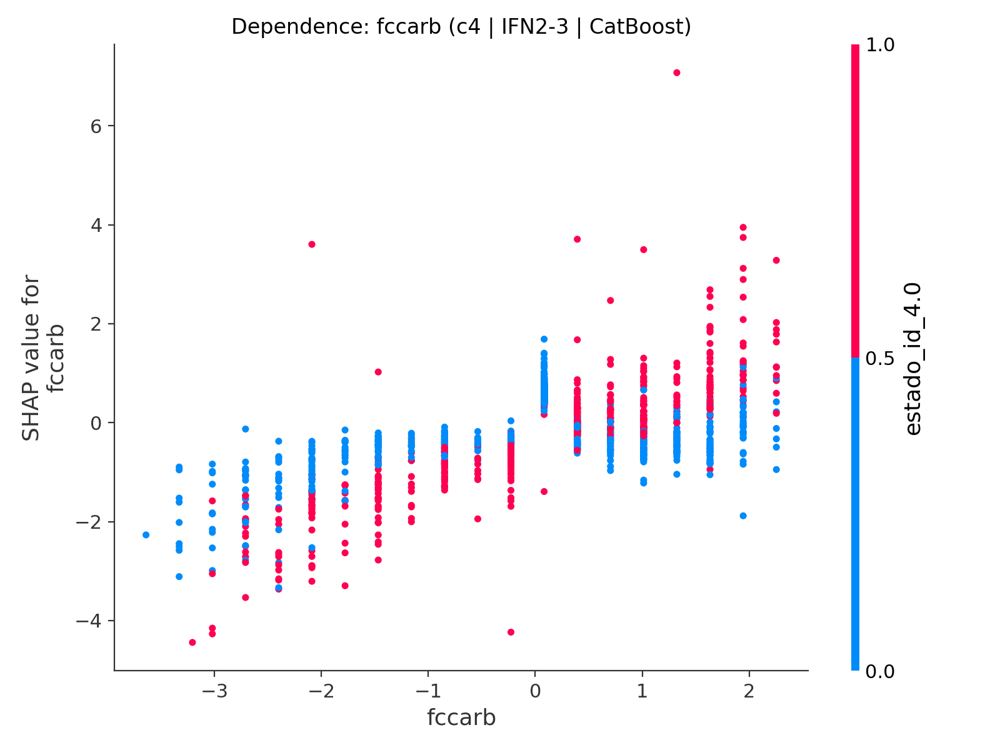

  [OK] elevacion


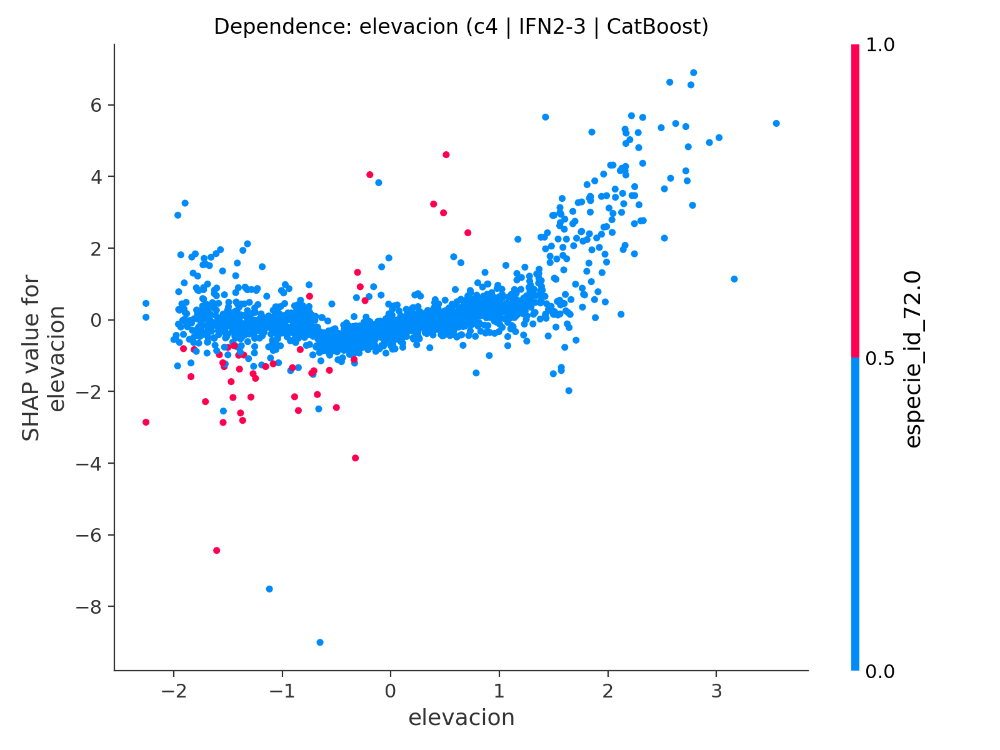

  [OK] gndvi_mean_verano


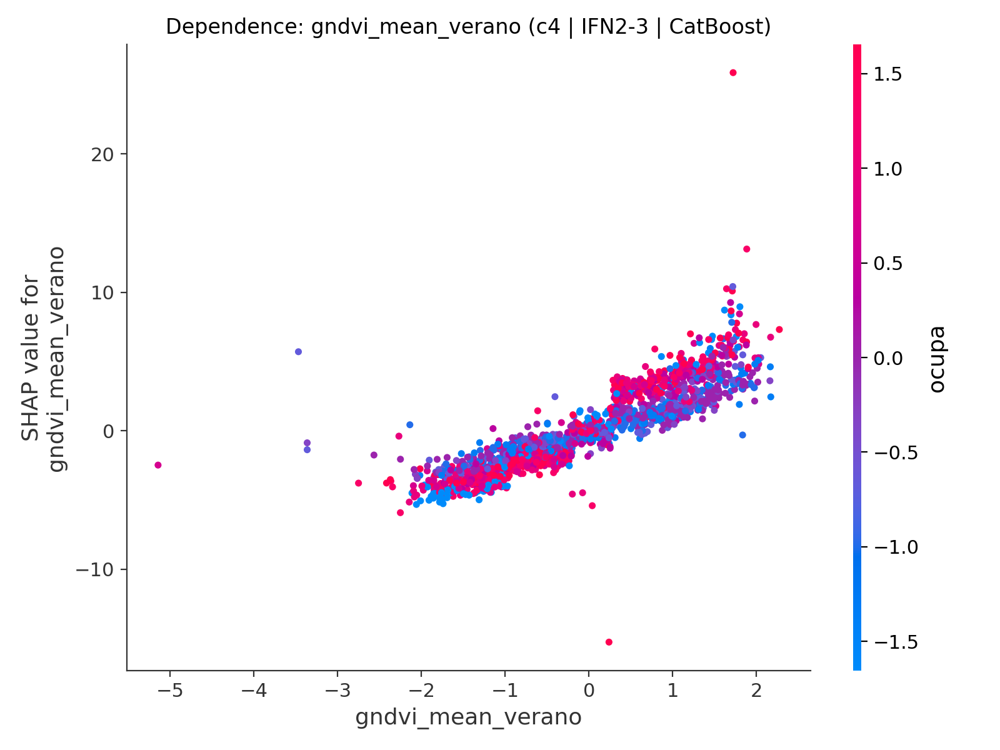

  [OK] evi_mean_primavera


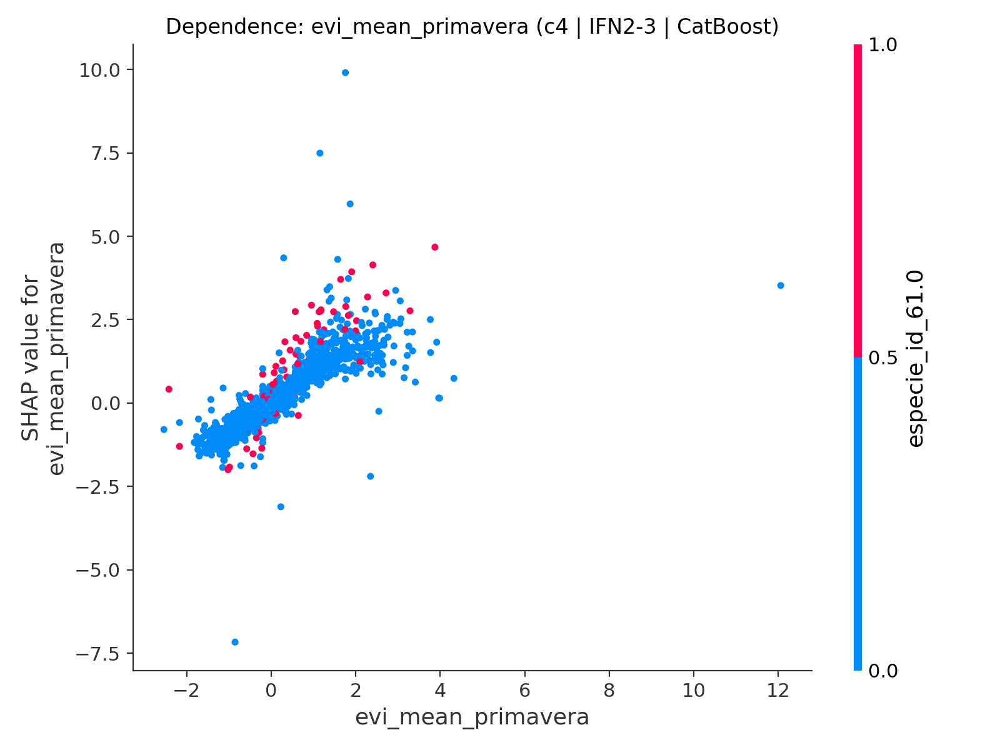

  [OK] skt_mean_verano


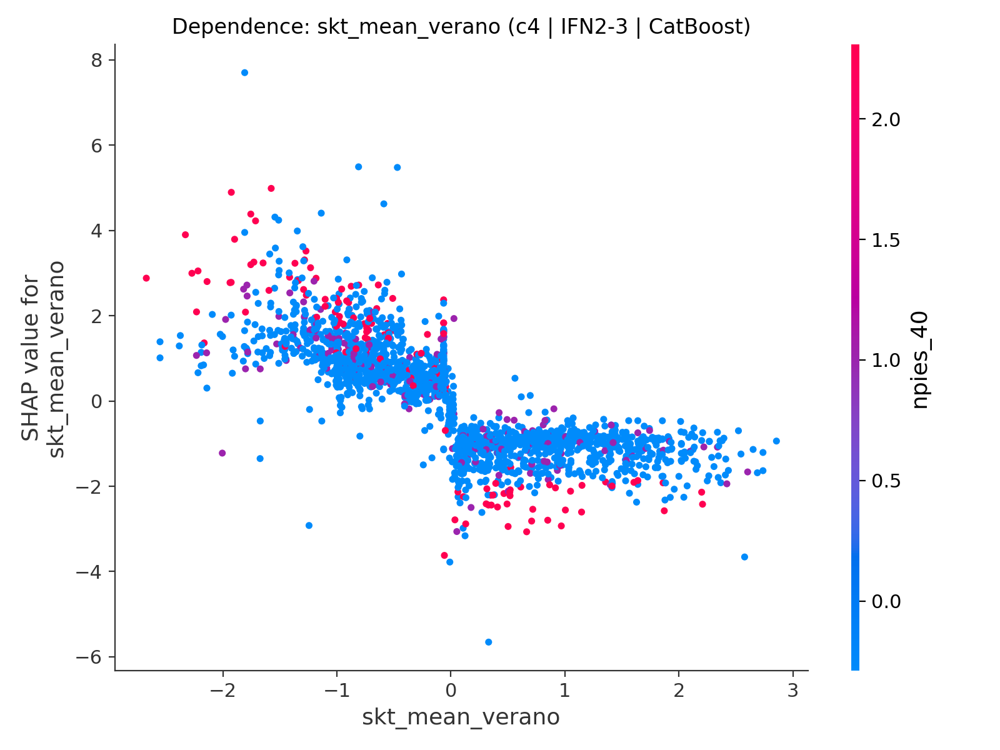

  [OK] pr_sum_primavera


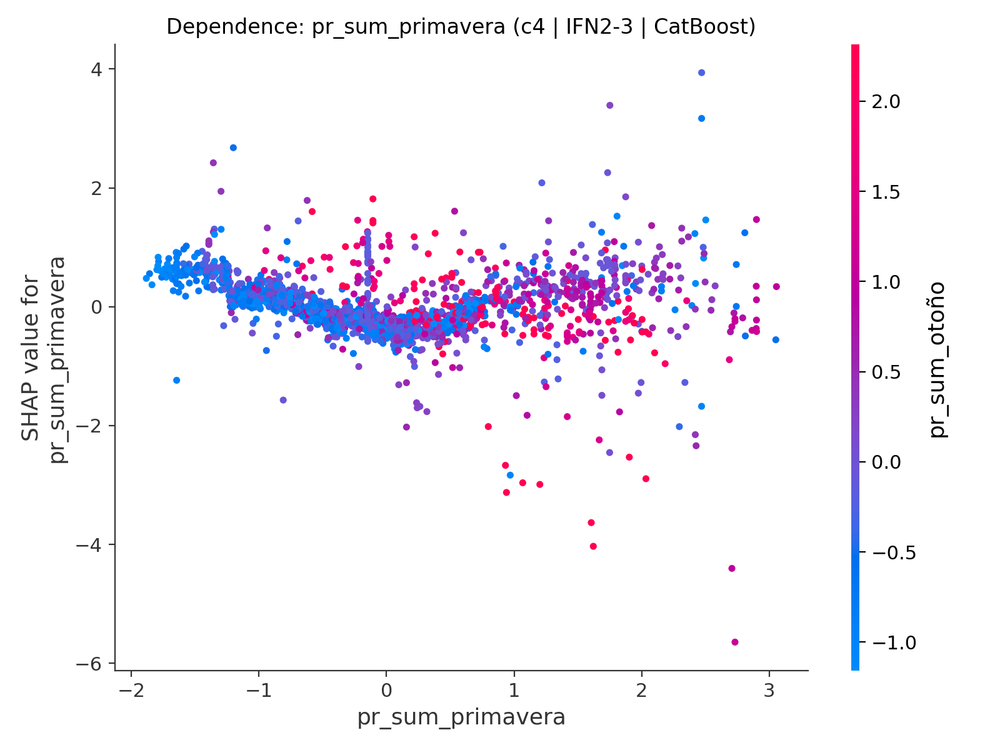

Dependence plots generales c4 completados.


In [9]:
feats_generales_c4 = [
    'fccarb', 'elevacion', 'gndvi_mean_verano',
    'evi_mean_primavera', 'skt_mean_verano', 'pr_sum_primavera'
]

out_dep_c4 = OUTPUT_SHAP / 'c4' / 'dependence'
out_dep_c4.mkdir(parents=True, exist_ok=True)

for feat in feats_generales_c4:
    save_path = out_dep_c4 / f'dep_{feat}.png'
    if save_path.exists() and save_path.with_suffix('.pdf').exists():
        print(f'  [OK] {feat}')
        ipy_display(IPImage(str(save_path)))
        continue
    col = next((f for f in feat_names_c4 if feat in f), None)
    if col is None:
        print(f'  Feature {feat} no encontrada, omitiendo')
        continue
    fig, ax = plt.subplots(figsize=(8, 6))
    shap.dependence_plot(col, shap_vals_c4, X_df_c4, display_features=X_df_c4, show=False, ax=ax)
    ax.set_title(f'Dependence: {feat} (c4 | IFN2-3 | CatBoost)', fontsize=12)
    plt.tight_layout()
    print(f'  -> {save_path}')
    plt.savefig(save_path, dpi=300)
    plt.savefig(save_path.with_suffix('.pdf'))
    plt.show()
    plt.close()

print('Dependence plots generales c4 completados.')

### 3.2 Estructura diamétrica vs tipo de especie (c4)

  [OK] npies_1


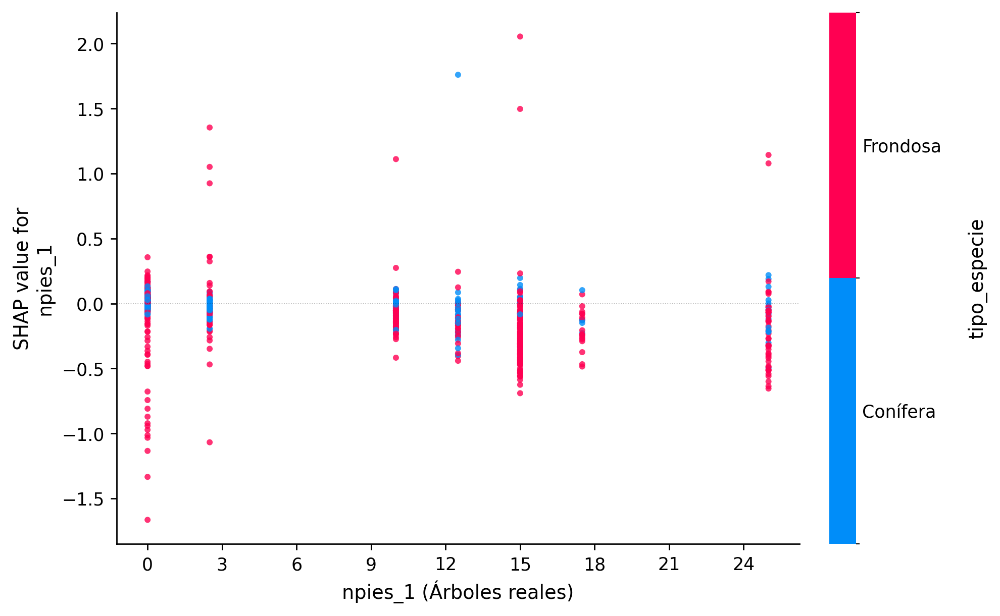

  [OK] npies_2


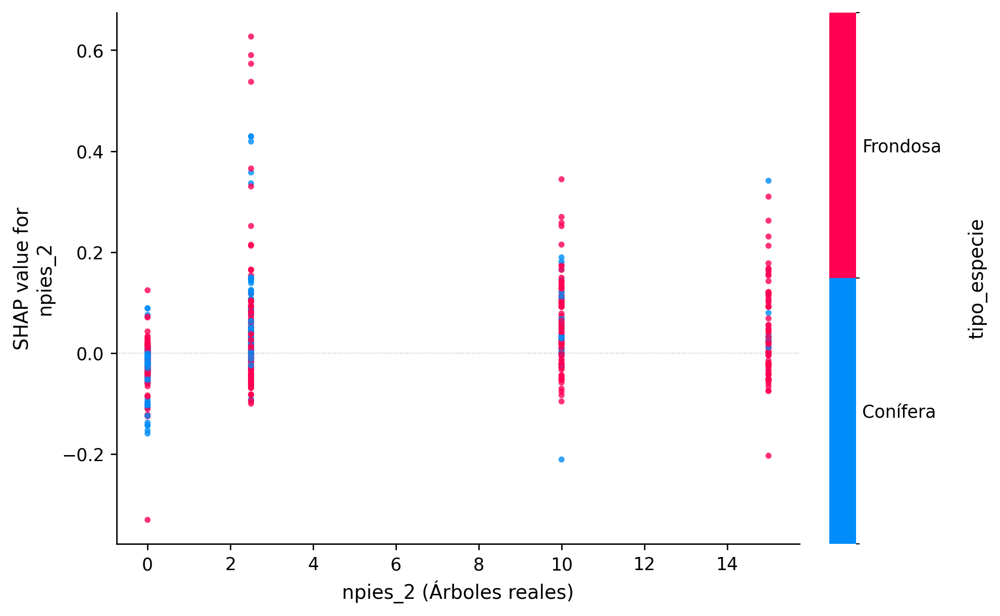

  [OK] npies_5


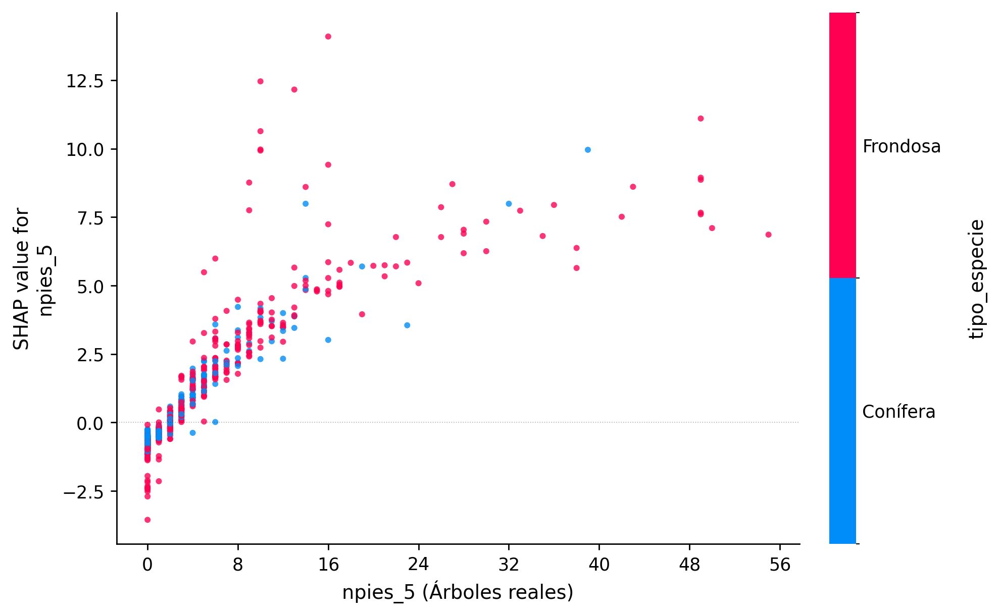

  [OK] npies_10


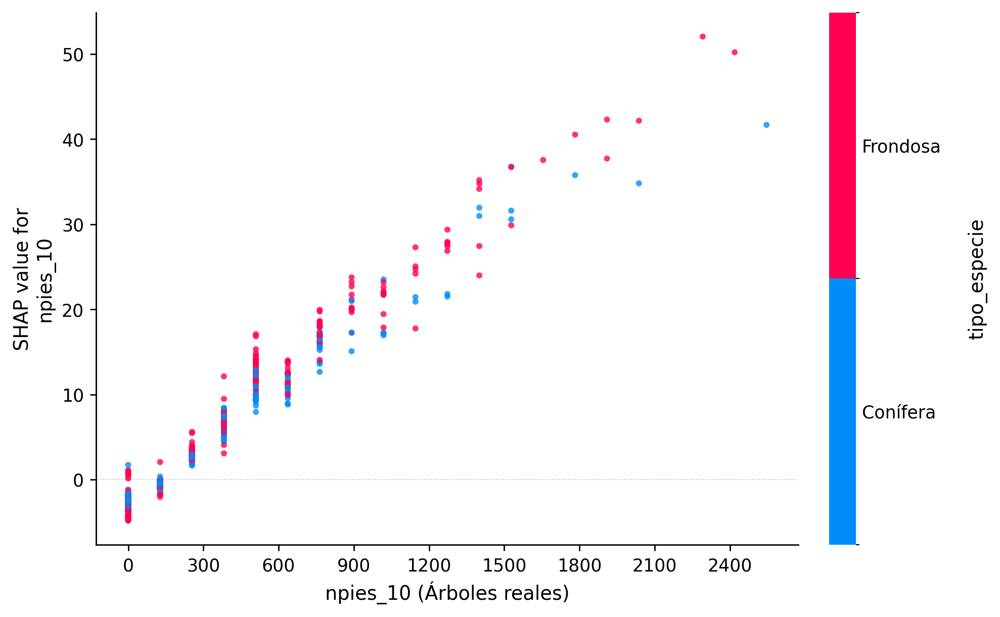

  [OK] npies_15


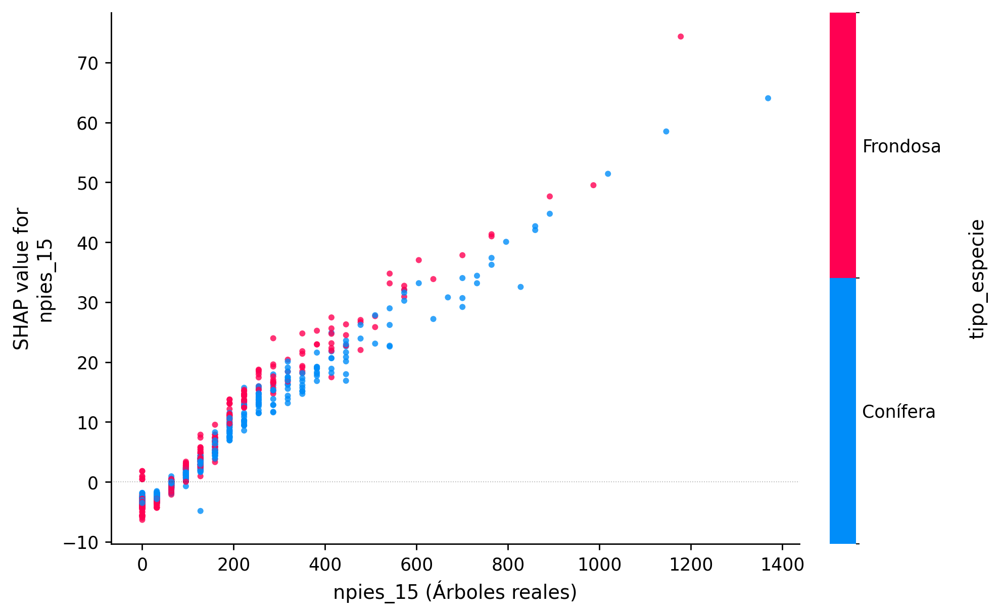

  [OK] npies_20


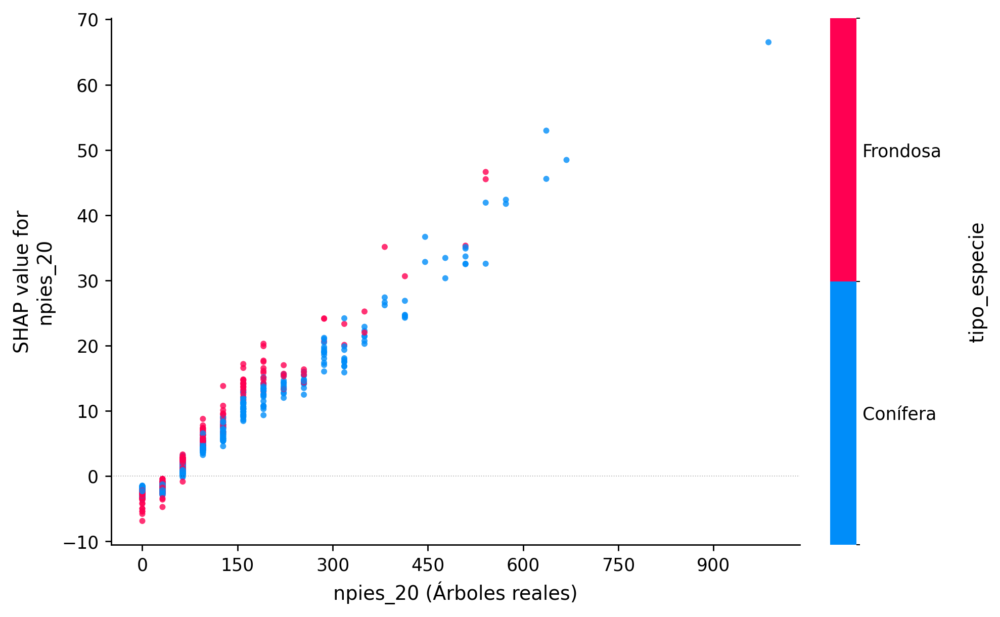

  [OK] npies_25


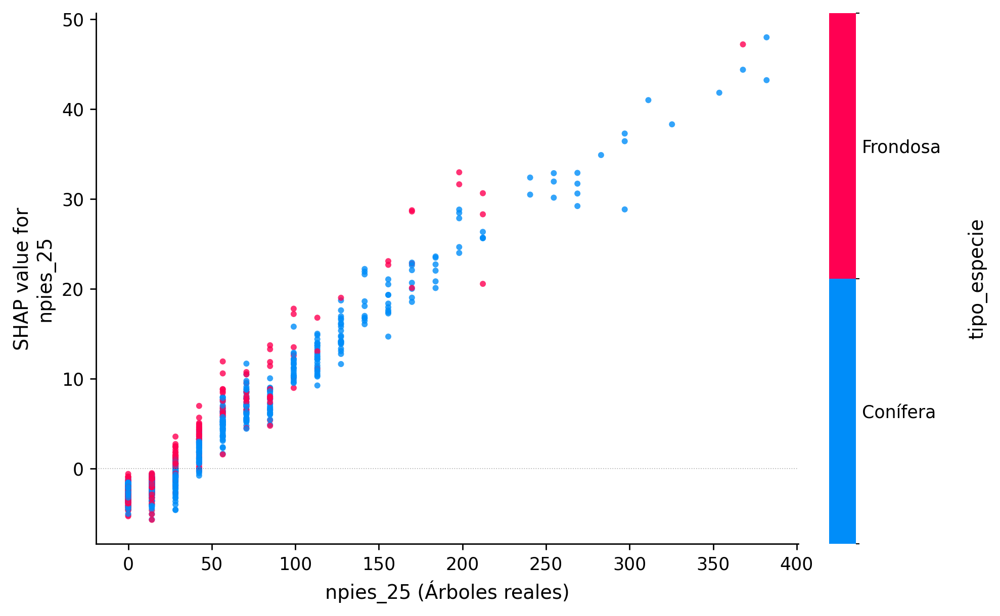

  [OK] npies_30


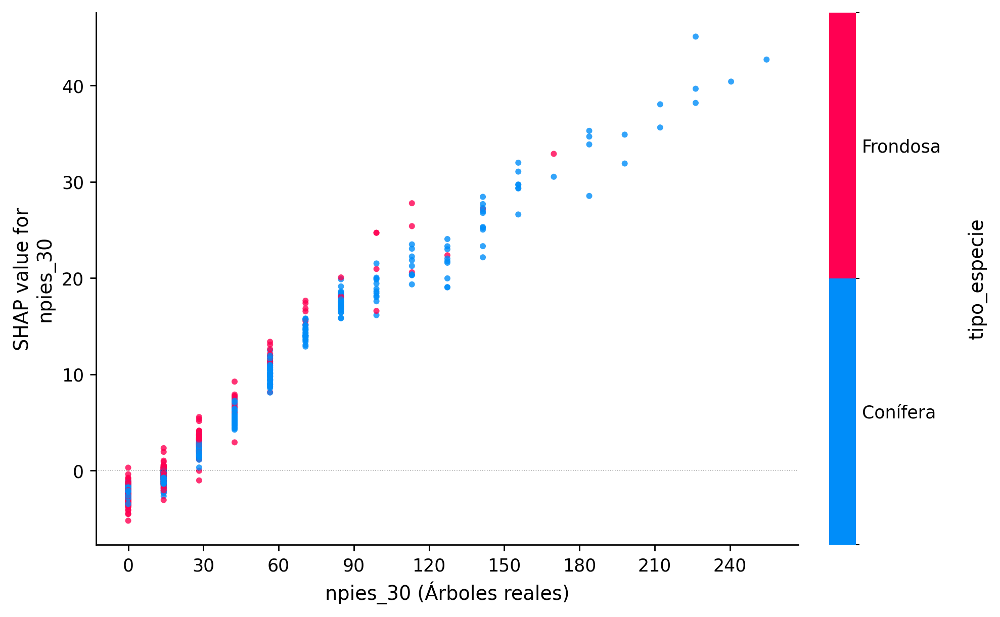

  [OK] npies_35


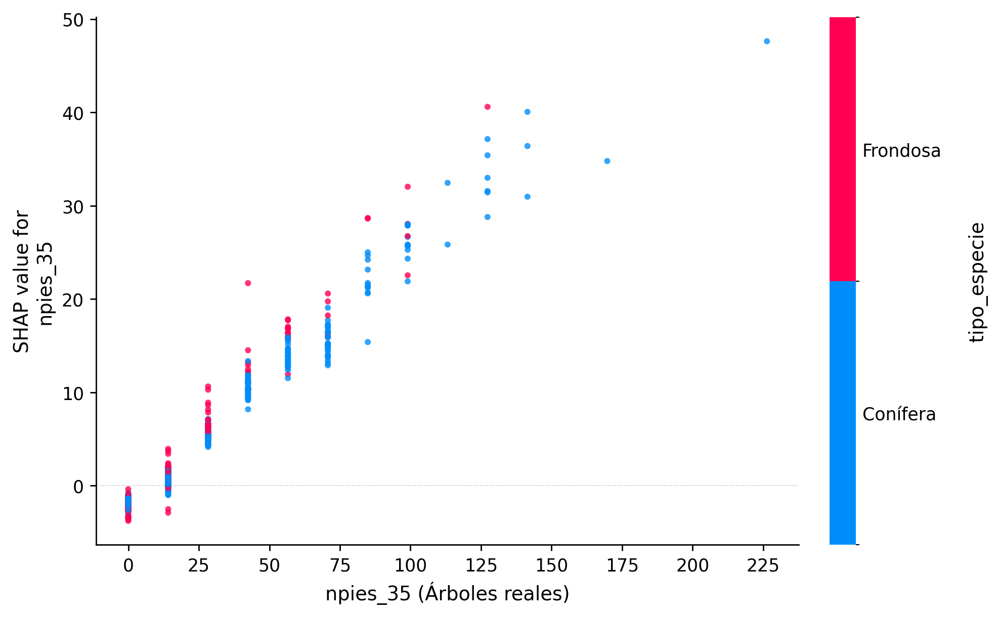

  [OK] npies_40


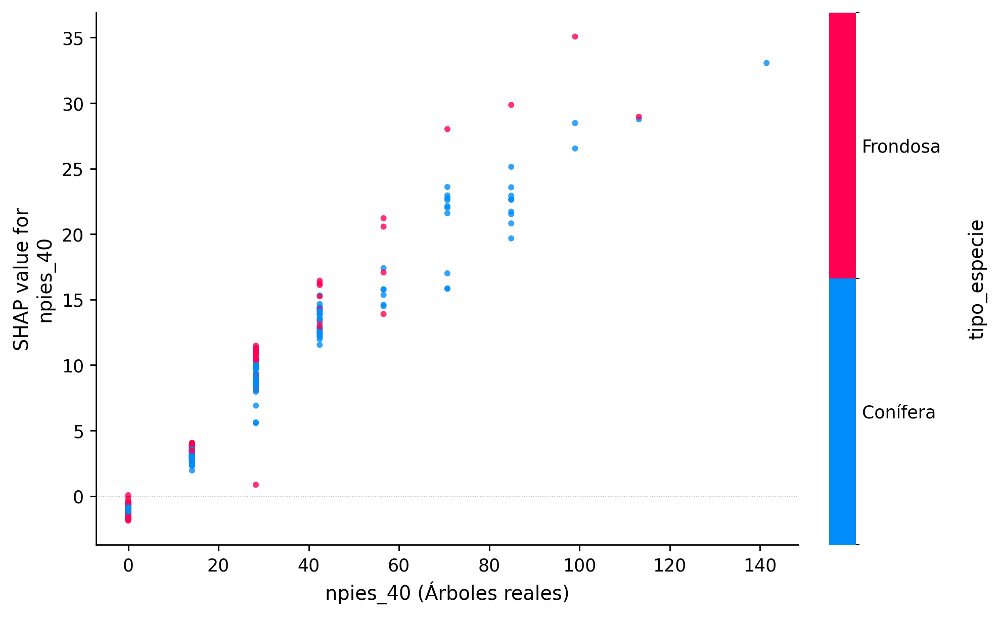

  [OK] npies_45


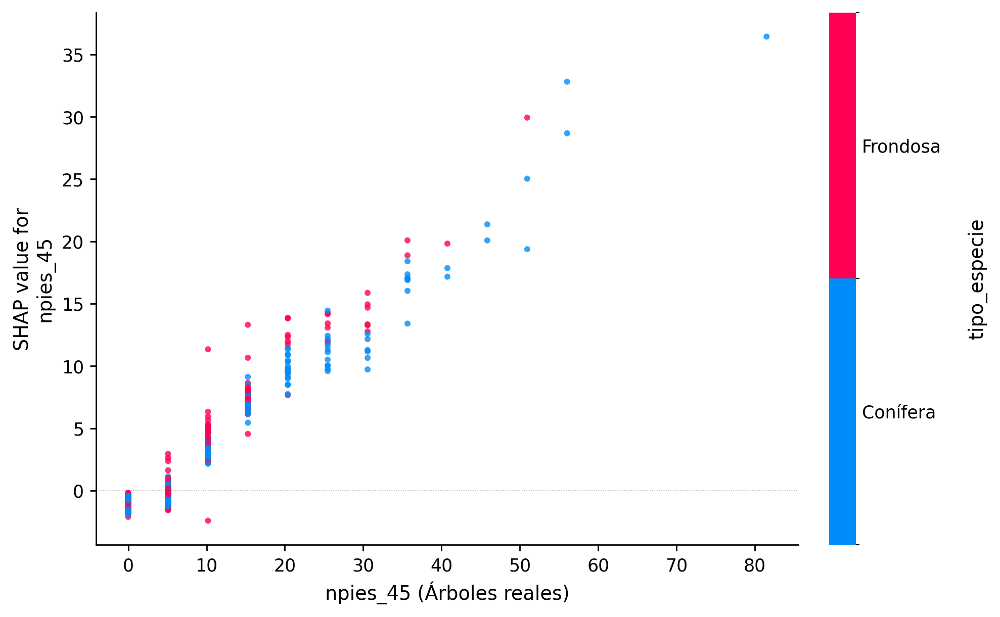

  [OK] npies_50


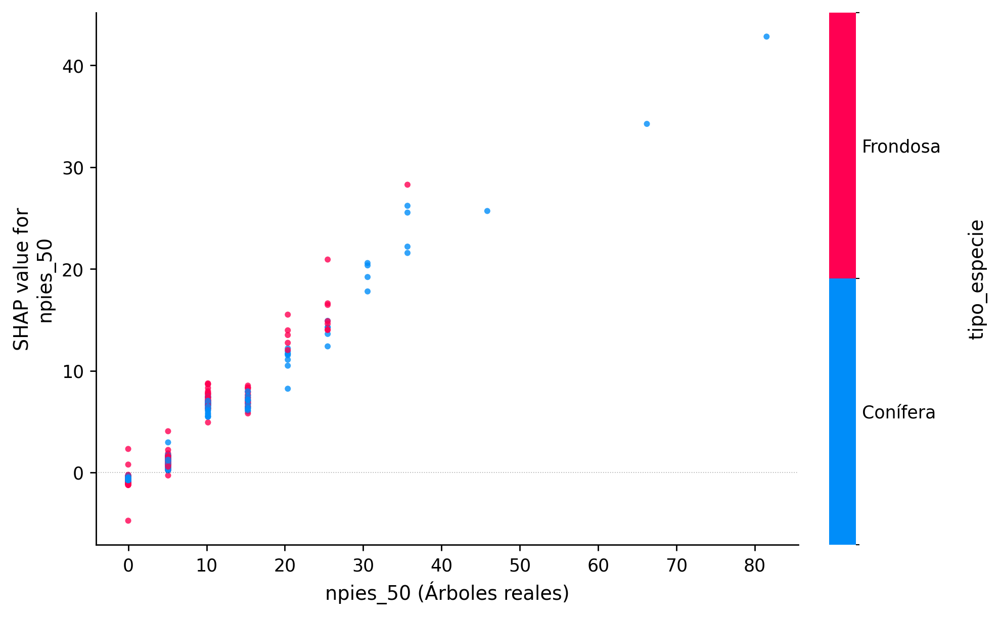

  [OK] npies_55


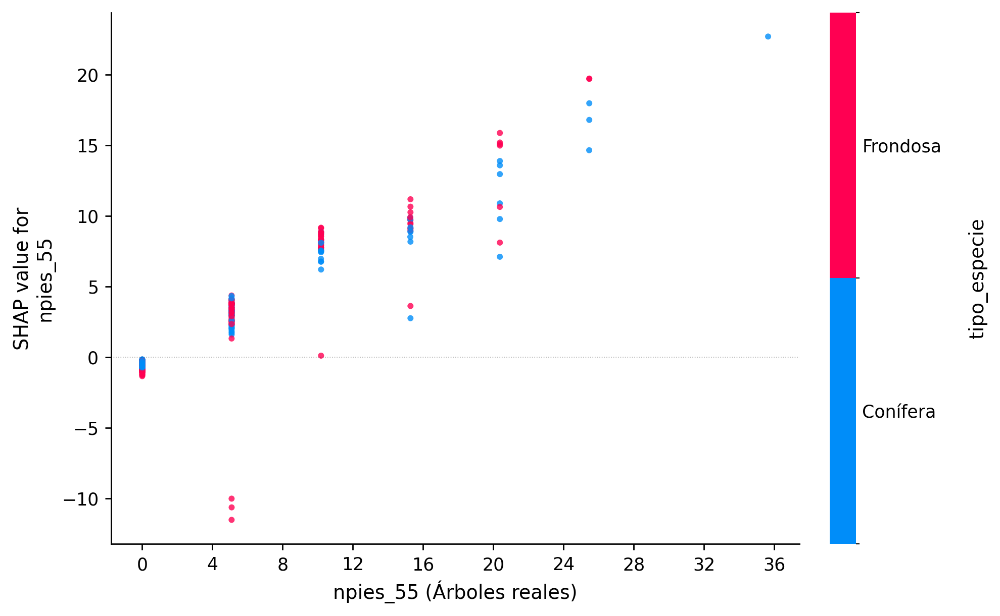

  [OK] npies_60


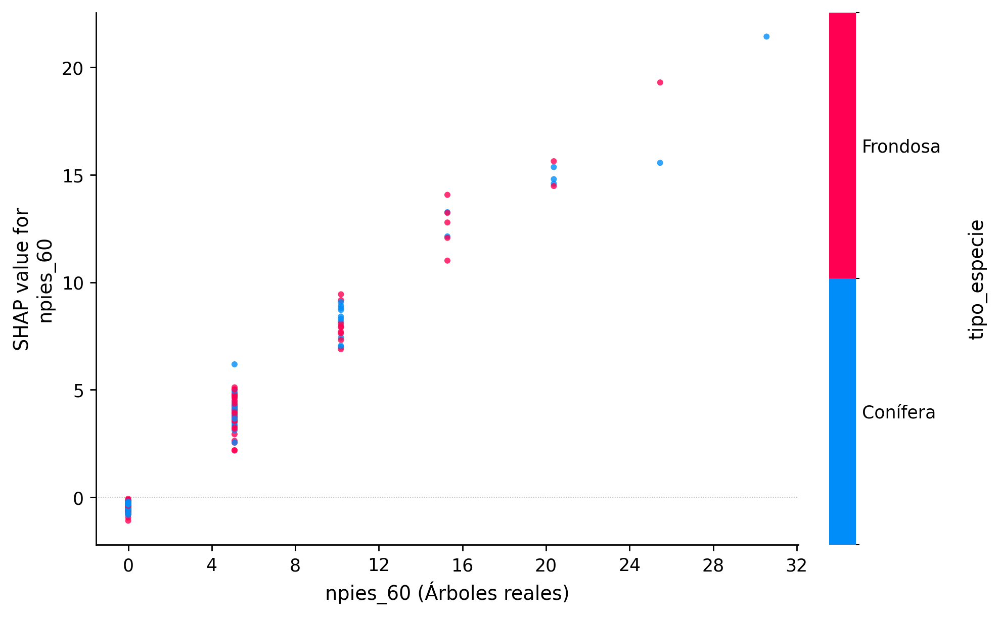

  [OK] npies_65


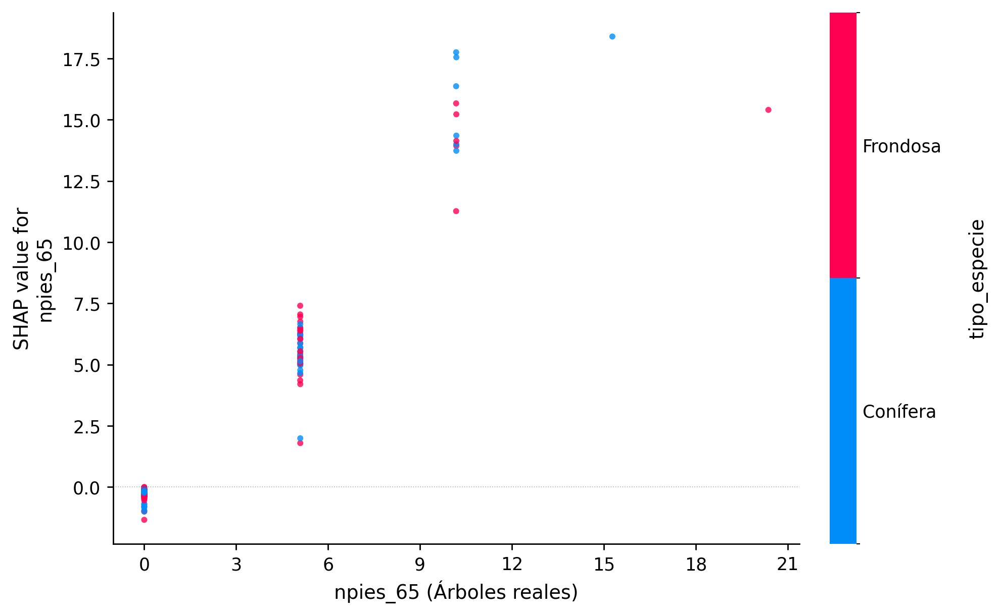

  [OK] npies_70


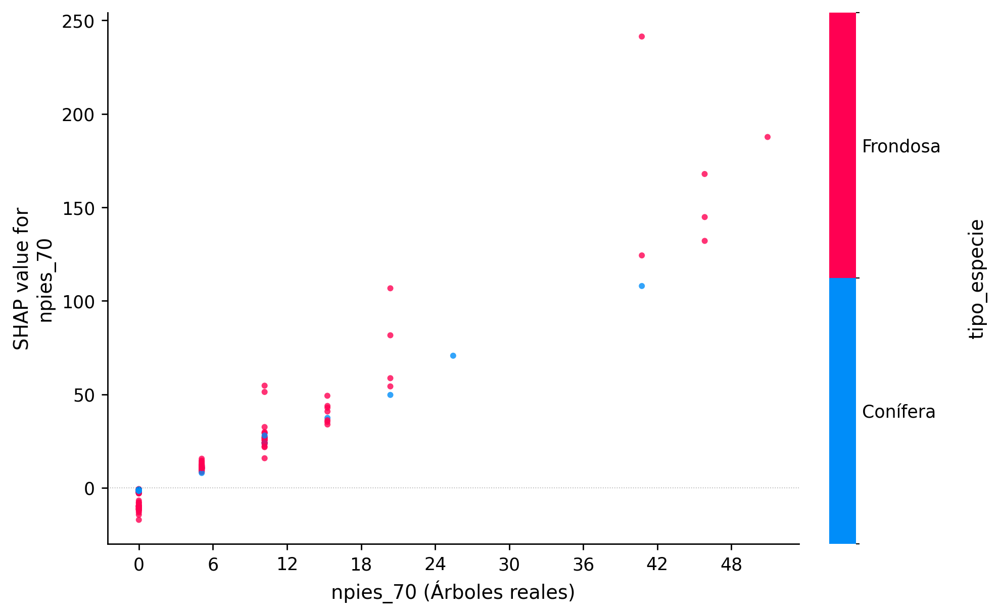

Dependence npies c4 completados.


In [10]:
shap_red  = '#ff0052'
shap_blue = '#008df9'
shap_cmap = ListedColormap([shap_blue, shap_red])

plt.rcParams['axes.spines.right'] = False
plt.rcParams['axes.spines.top']   = False

npies_cols = [c for c in FEATURES_C4 if 'npies_' in c]
cat_codes  = X_dep_c4['tipo_especie'].values if 'tipo_especie' in X_dep_c4.columns else None

out_npies_c4 = OUTPUT_SHAP / 'c4' / 'dependence_npies'
out_npies_c4.mkdir(parents=True, exist_ok=True)

for feat in npies_cols:
    save_path = out_npies_c4 / f'dep_npies_{feat}.png'
    if save_path.exists() and save_path.with_suffix('.pdf').exists():
        print(f'  [OK] {feat}')
        ipy_display(IPImage(str(save_path)))
        continue
    col = next((f for f in feat_names_c4 if feat in f), None)
    if col is None or cat_codes is None:
        continue
    col_idx = feat_names_c4.index(col)
    x_vals  = X_dep_c4[feat].values
    y_shap  = shap_vals_c4[:, col_idx]

    fig, ax = plt.subplots(figsize=(8, 5))
    norm = mpl.colors.BoundaryNorm([-0.5, 0.5, 1.5], shap_cmap.N)
    ax.scatter(x_vals, y_shap, c=cat_codes, cmap=shap_cmap,
               s=12, alpha=0.8, edgecolors='none', vmin=0, vmax=1)
    cbar = plt.colorbar(
        mpl.cm.ScalarMappable(norm=norm, cmap=shap_cmap),
        ax=ax, ticks=[0, 1], fraction=0.046, pad=0.04
    )
    cbar.set_ticklabels(['Con\u00edfera', 'Frondosa'])
    cbar.ax.set_ylabel('tipo_especie', rotation=90, labelpad=15, fontsize=11)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(size=0)
    ax.set_xlabel(f'{feat} (\u00c1rboles reales)', fontsize=11)
    ax.set_ylabel(f'SHAP value for\n{feat}', fontsize=11)
    ax.axhline(0, color='black', linestyle=':', linewidth=0.5, alpha=0.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.tight_layout()
    print(f'  -> {save_path}')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
    plt.show()
    plt.close()

print('Dependence npies c4 completados.')

---
## 4. SHAP Dependence — carbono\_bruto4 (IFN2-3, CatBoost)

### 4.1 Variables generales

In [11]:
X_dep_cb4 = X_test_cb4.sample(min(2000, len(X_test_cb4)), random_state=42)

cache_dep_cb4 = CACHE_SHAP / 'dependence' / 'carbono_bruto4' / 'CatBoost_2000.joblib'

if cache_dep_cb4.exists():
    print('Cargando SHAP values CatBoost carbono_bruto4 desde caché...')
    _d = joblib.load(cache_dep_cb4)
    feat_names_cb4 = _d['feat_names']
    shap_vals_cb4  = _d['shap_vals']
    X_df_cb4       = _d['X_df']
    del _d; gc.collect()
else:
    print('Cargando CatBoost carbono_bruto4...')
    pipeline_catboost_cb4 = joblib.load(MODELS_IFN23_CB4 / 'CatBoost.joblib')

    preprocessor_cb4 = pipeline_catboost_cb4.named_steps['preprocessor']
    model_cb4        = pipeline_catboost_cb4.named_steps['regressor']

    feat_names_cb4 = get_feature_names(preprocessor_cb4)
    X_trans_cb4    = preprocessor_cb4.transform(X_dep_cb4)
    if X_trans_cb4.shape[1] != len(feat_names_cb4):
        feat_names_cb4 = [f'f_{i:03d}' for i in range(X_trans_cb4.shape[1])]
    X_df_cb4 = pd.DataFrame(X_trans_cb4, columns=feat_names_cb4)

    print('Calculando SHAP values (TreeExplainer)...')
    explainer_cb4 = shap.TreeExplainer(model_cb4)
    shap_vals_cb4 = explainer_cb4.shap_values(X_df_cb4)
    if isinstance(shap_vals_cb4, list):
        shap_vals_cb4 = shap_vals_cb4[0]

    del pipeline_catboost_cb4, preprocessor_cb4, model_cb4, explainer_cb4
    gc.collect()

    cache_dep_cb4.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump({'feat_names': feat_names_cb4, 'shap_vals': shap_vals_cb4, 'X_df': X_df_cb4},
                cache_dep_cb4, compress=3)
    print('Caché guardada.')

print(f'SHAP values: {shap_vals_cb4.shape}')

Cargando SHAP values CatBoost carbono_bruto4 desde caché...
SHAP values: (2000, 210)


  [OK] fccarb


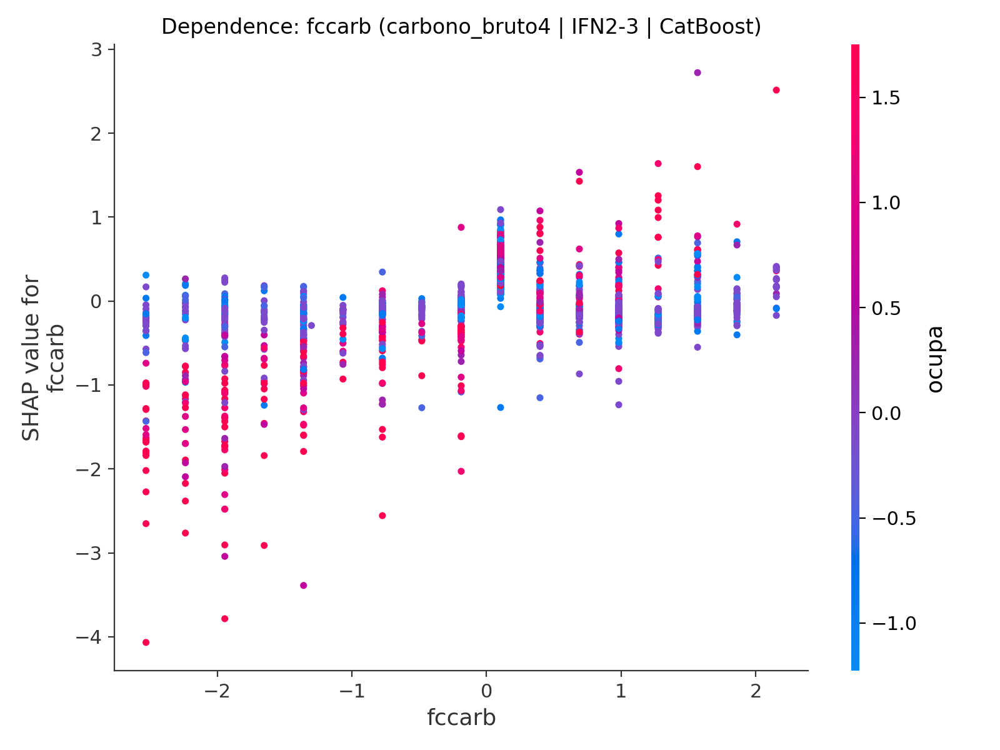

  [OK] elevacion


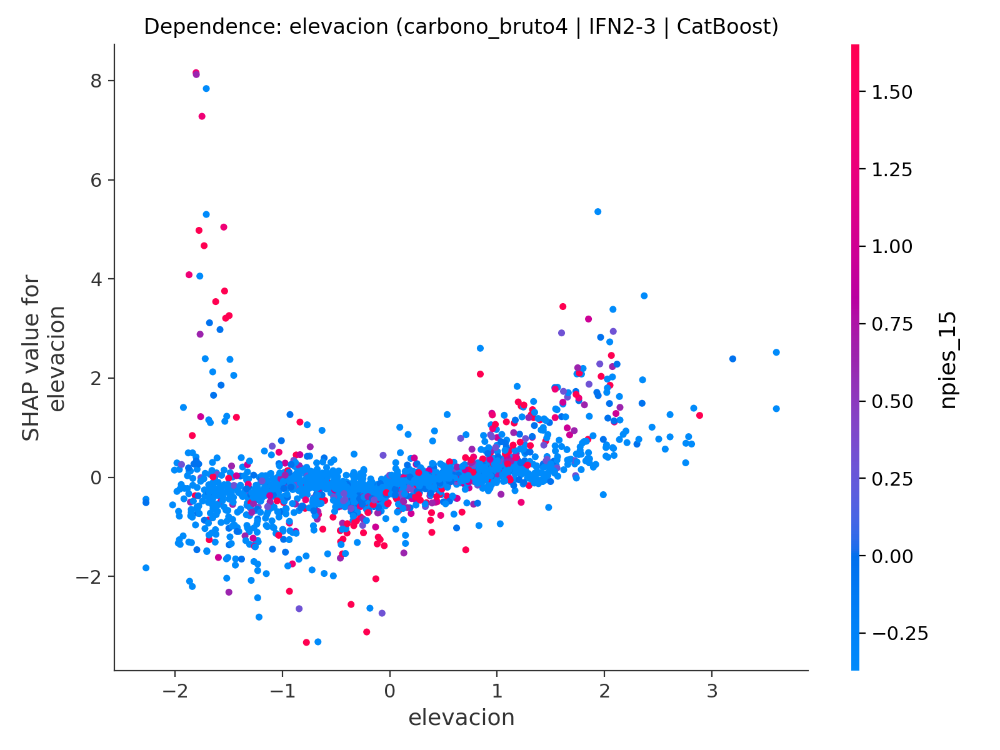

  [OK] gndvi_mean_verano


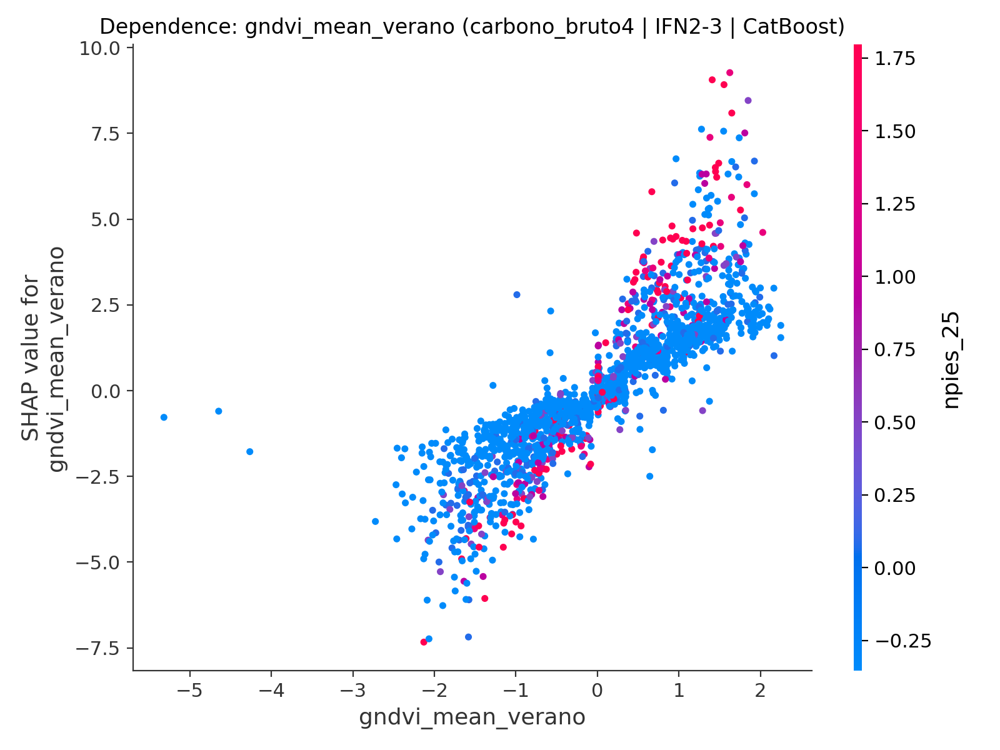

  [OK] evi_mean_primavera


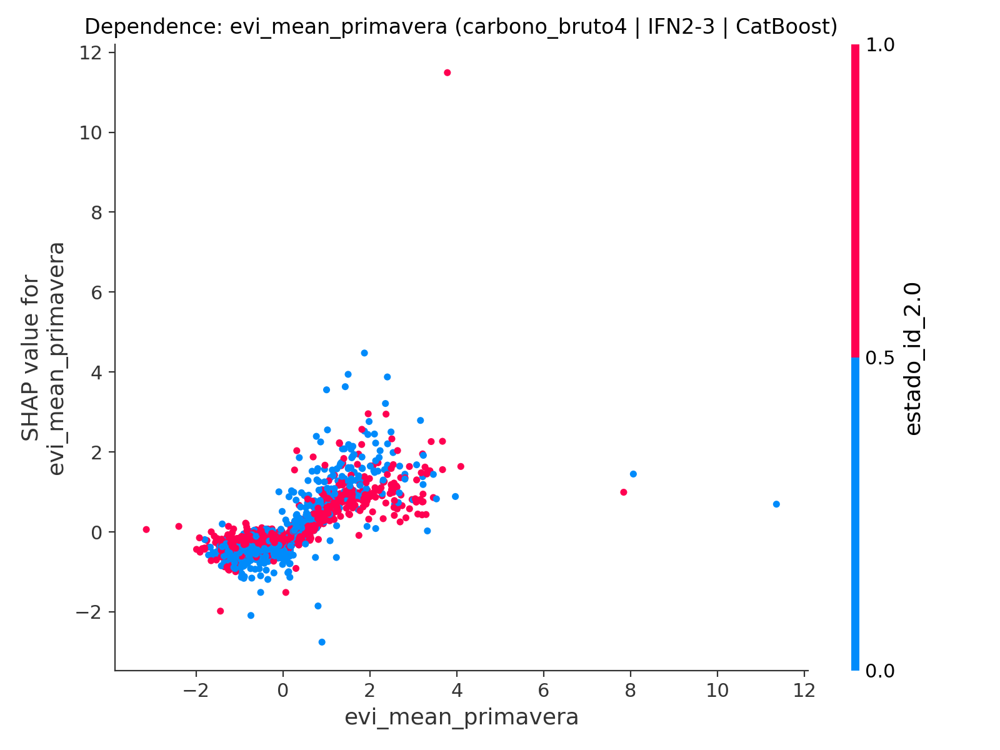

  [OK] martonneidx_id


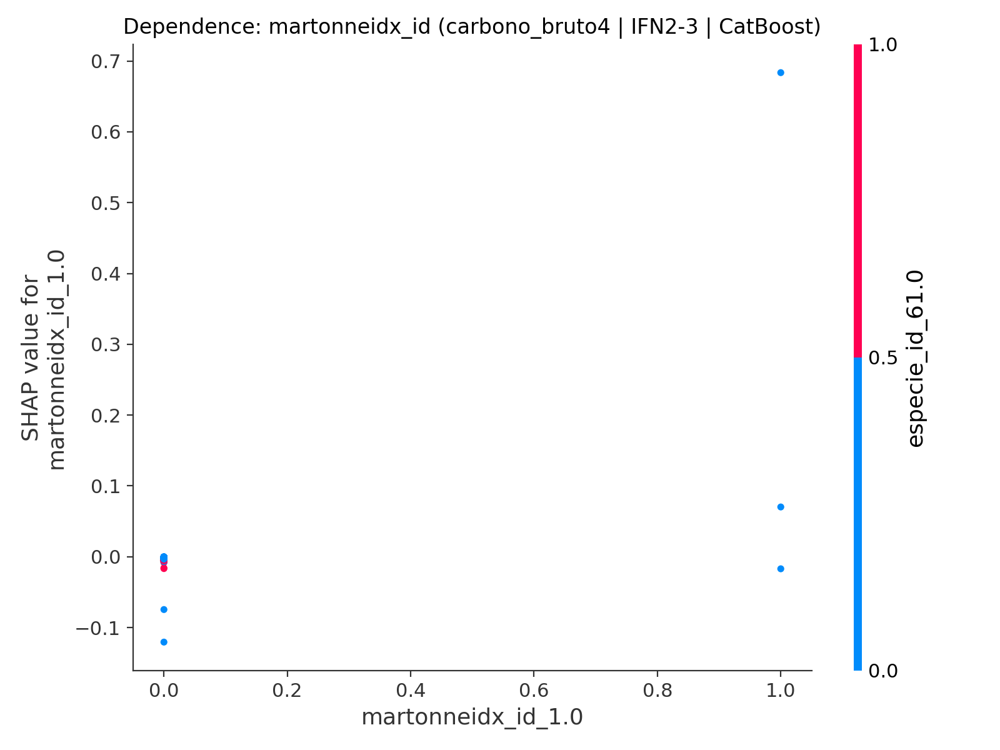

Dependence plots generales carbono_bruto4 completados.


In [12]:
feats_generales_cb4 = [
    'fccarb', 'elevacion', 'gndvi_mean_verano',
    'evi_mean_primavera', 'martonneidx_id'
]

out_dep_cb4 = OUTPUT_SHAP / 'carbono_bruto4' / 'dependence'
out_dep_cb4.mkdir(parents=True, exist_ok=True)

for feat in feats_generales_cb4:
    save_path = out_dep_cb4 / f'dep_{feat}.png'
    if save_path.exists() and save_path.with_suffix('.pdf').exists():
        print(f'  [OK] {feat}')
        ipy_display(IPImage(str(save_path)))
        continue
    col = next((f for f in feat_names_cb4 if feat in f), None)
    if col is None:
        print(f'  Feature {feat} no encontrada, omitiendo')
        continue
    fig, ax = plt.subplots(figsize=(8, 6))
    shap.dependence_plot(col, shap_vals_cb4, X_df_cb4, display_features=X_df_cb4, show=False, ax=ax)
    ax.set_title(f'Dependence: {feat} (carbono_bruto4 | IFN2-3 | CatBoost)', fontsize=12)
    plt.tight_layout()
    print(f'  -> {save_path}')
    plt.savefig(save_path, dpi=300)
    plt.savefig(save_path.with_suffix('.pdf'))
    plt.show()
    plt.close()

print('Dependence plots generales carbono_bruto4 completados.')

### 4.2 Estructura diamétrica vs tipo de especie (carbono\_bruto4)

  [OK] npies_1


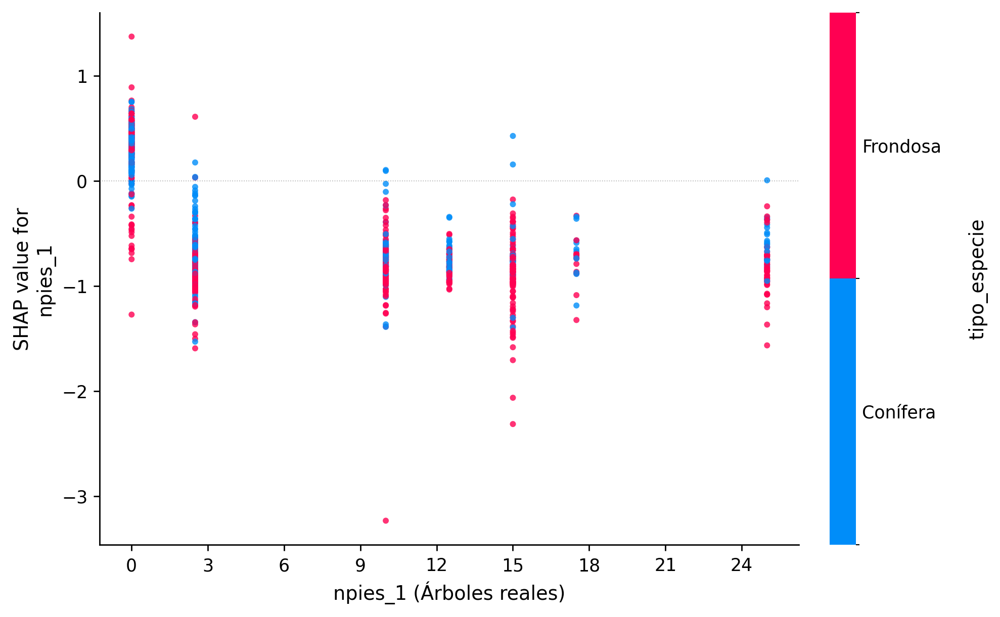

  [OK] npies_2


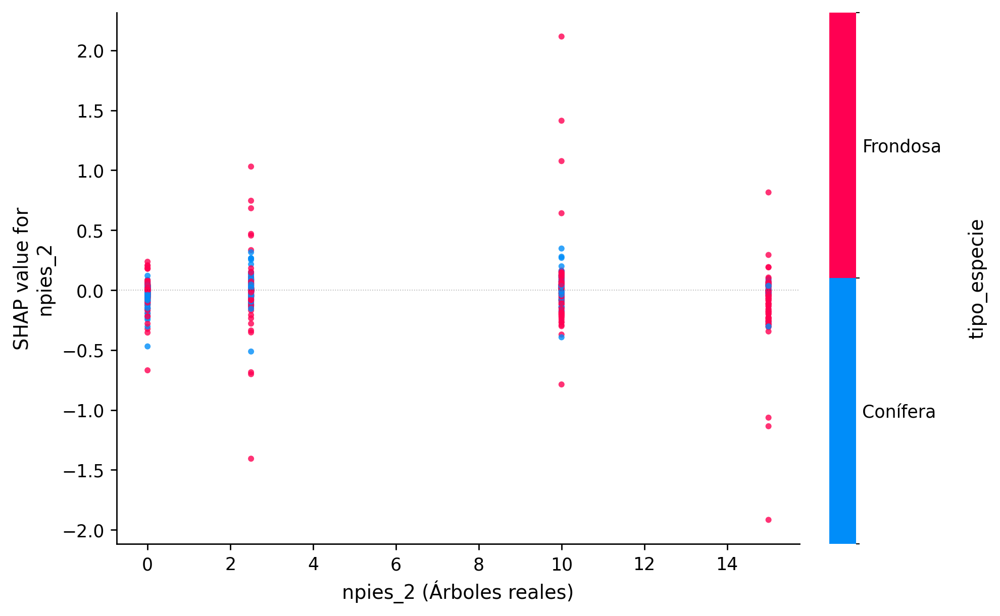

  [OK] npies_5


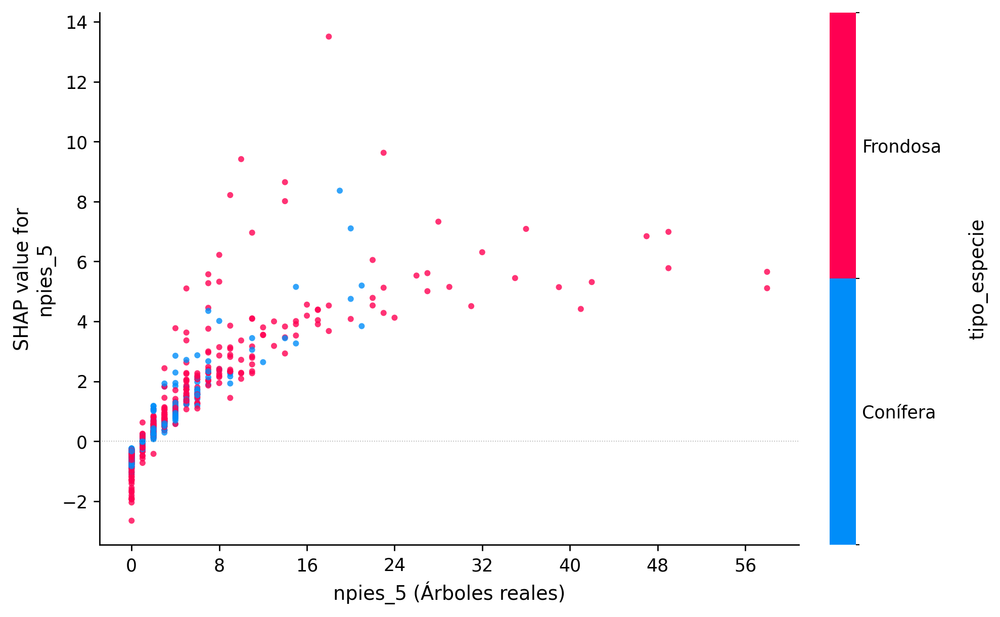

  [OK] npies_10


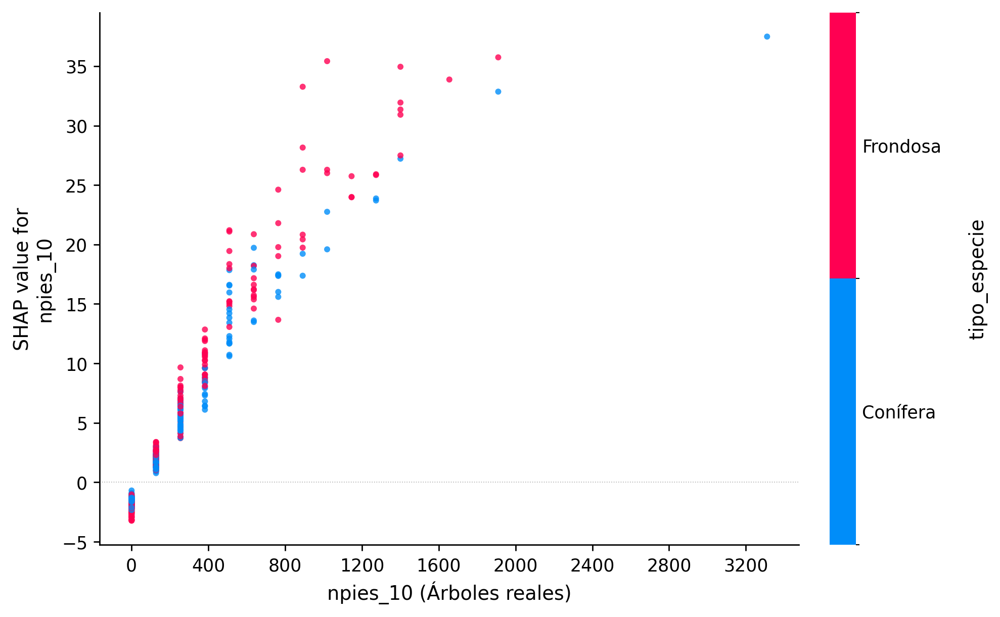

  [OK] npies_15


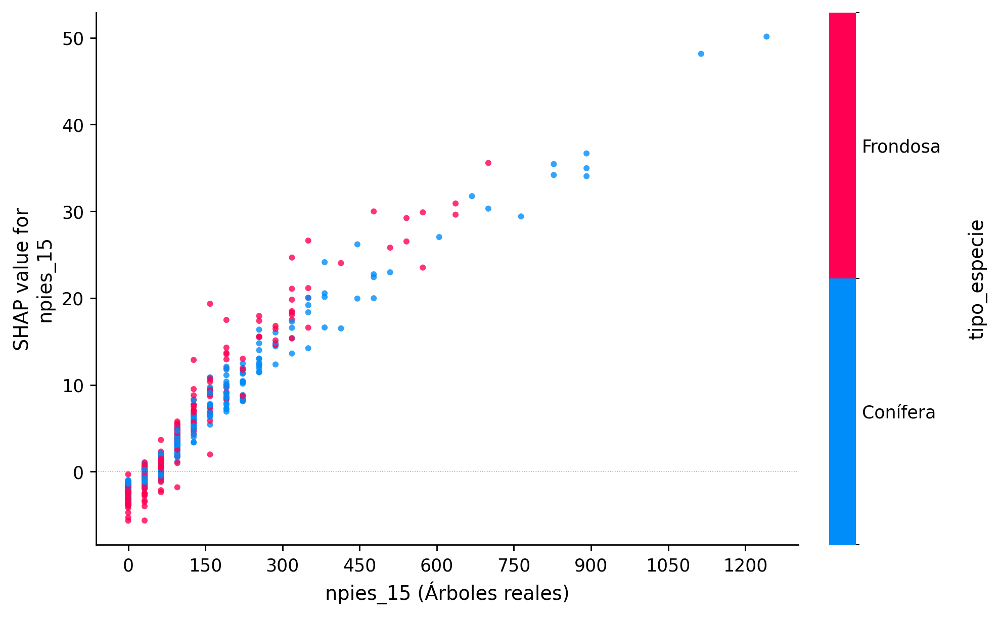

  [OK] npies_20


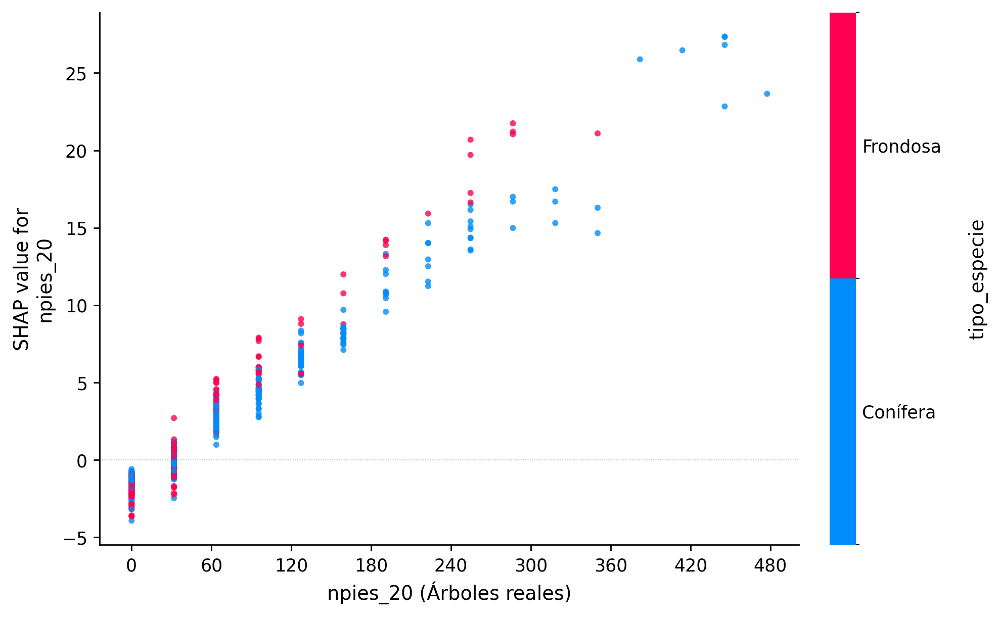

  [OK] npies_25


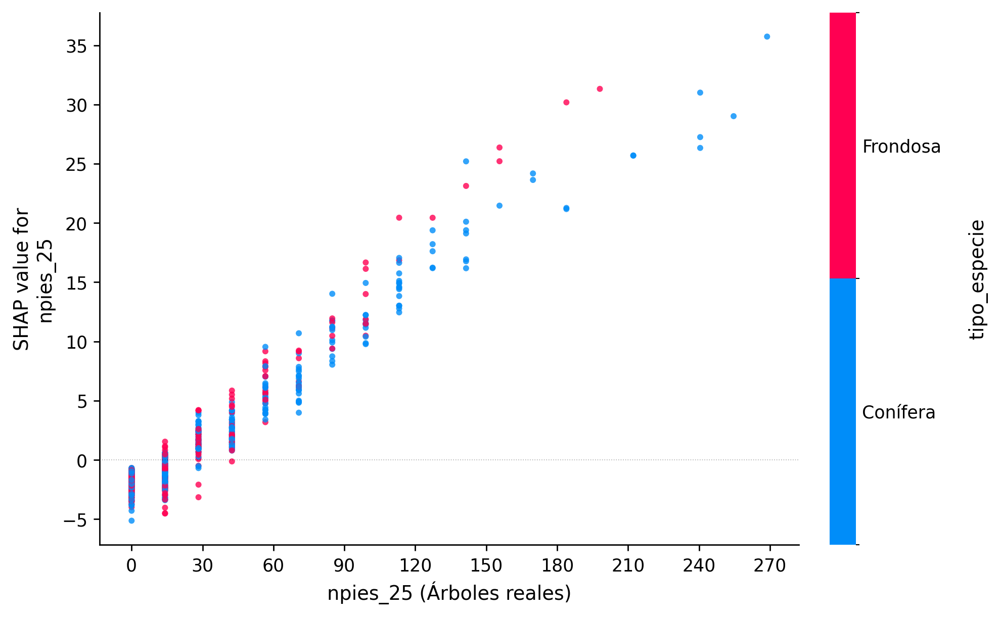

  [OK] npies_30


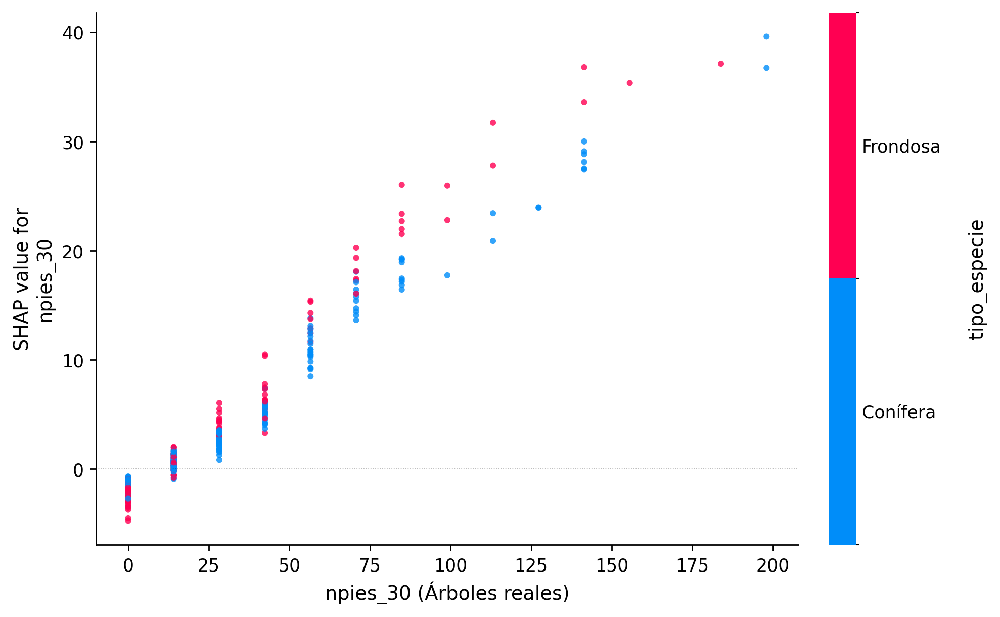

  [OK] npies_35


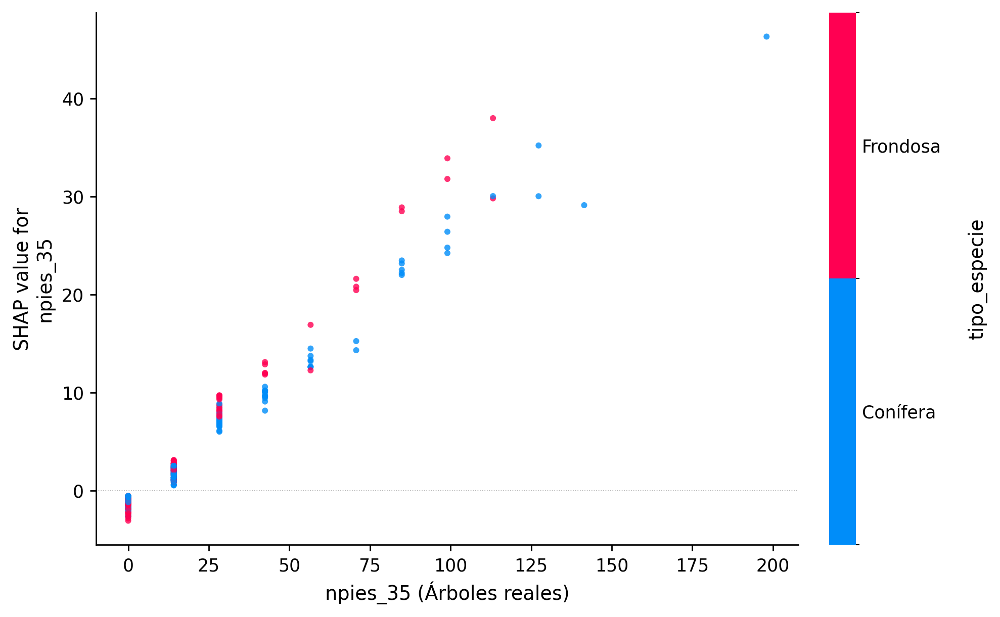

  [OK] npies_40


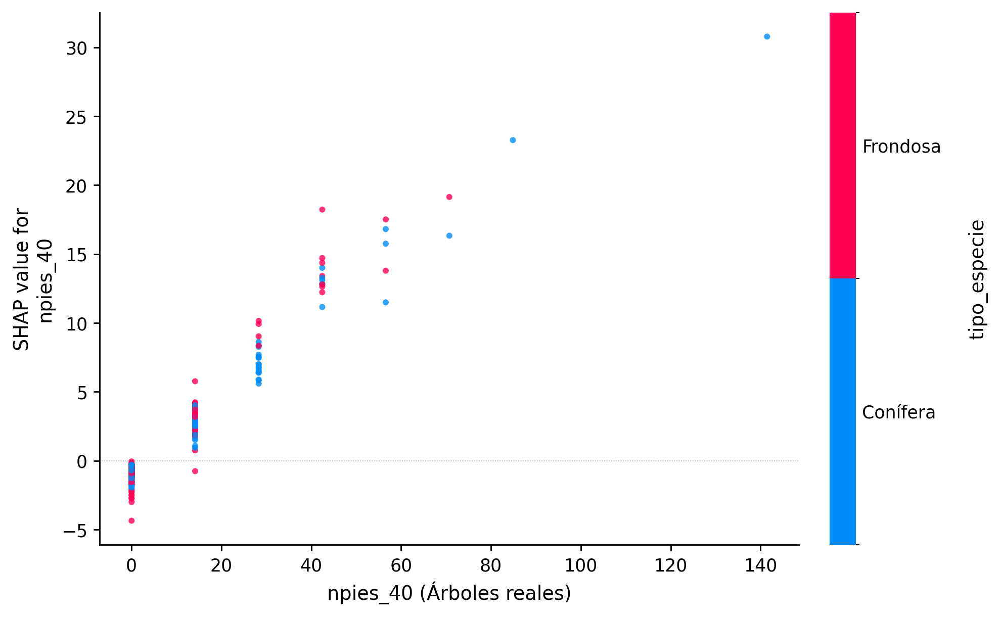

  [OK] npies_45


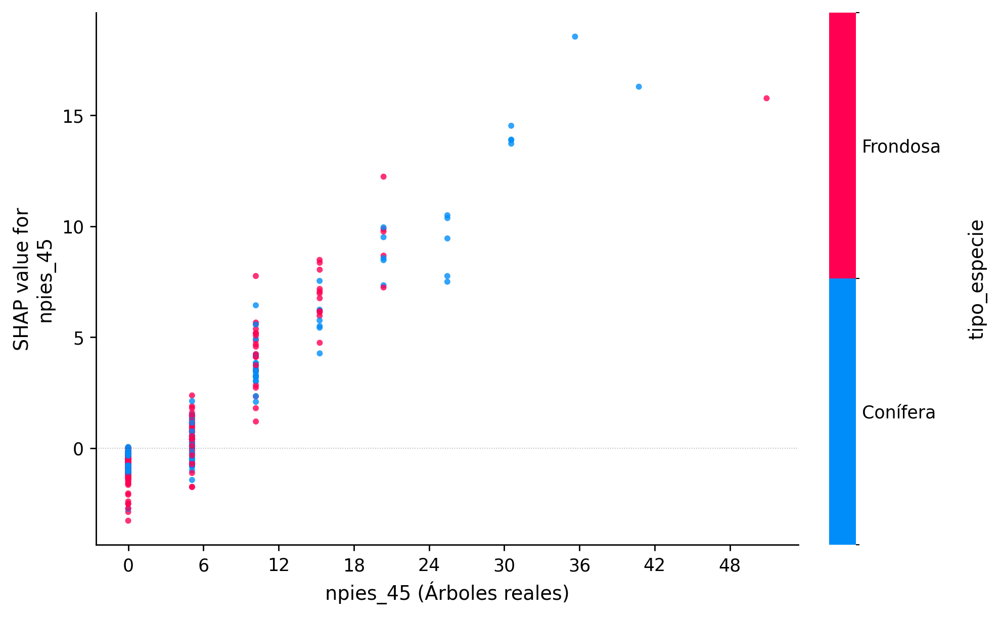

  [OK] npies_50


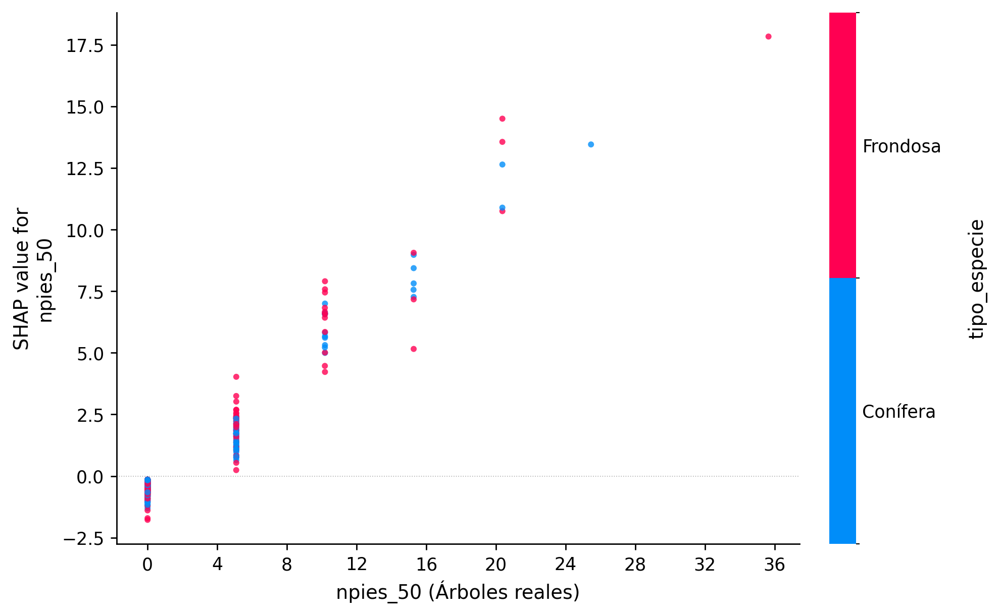

  [OK] npies_55


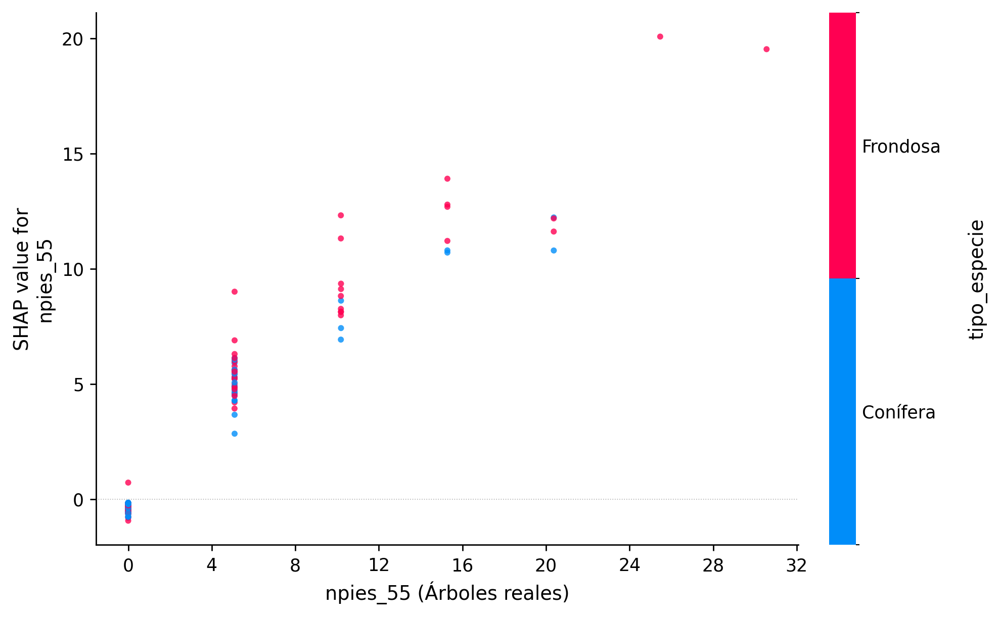

  [OK] npies_60


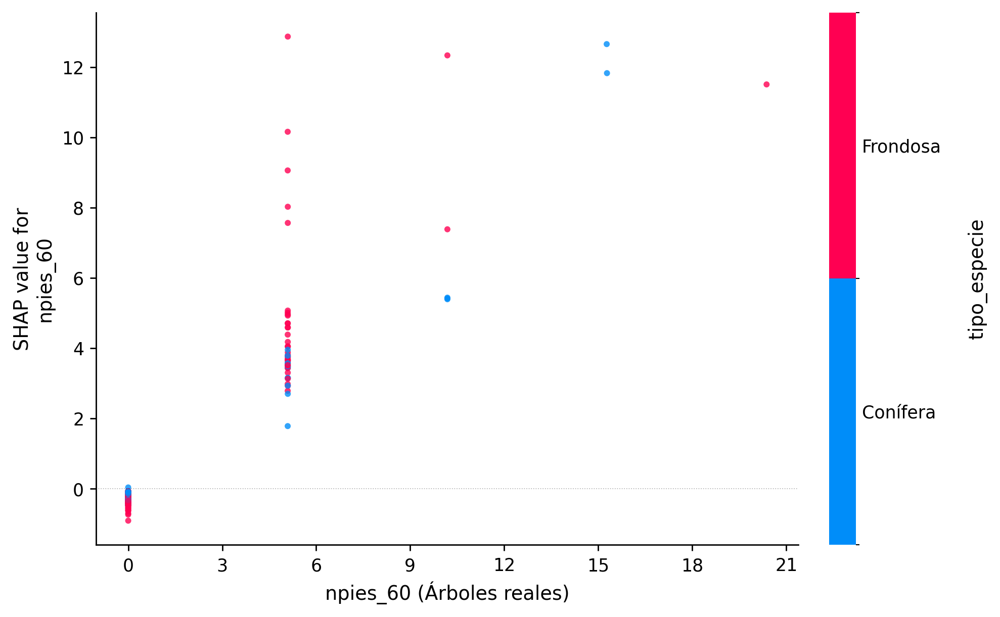

  [OK] npies_65


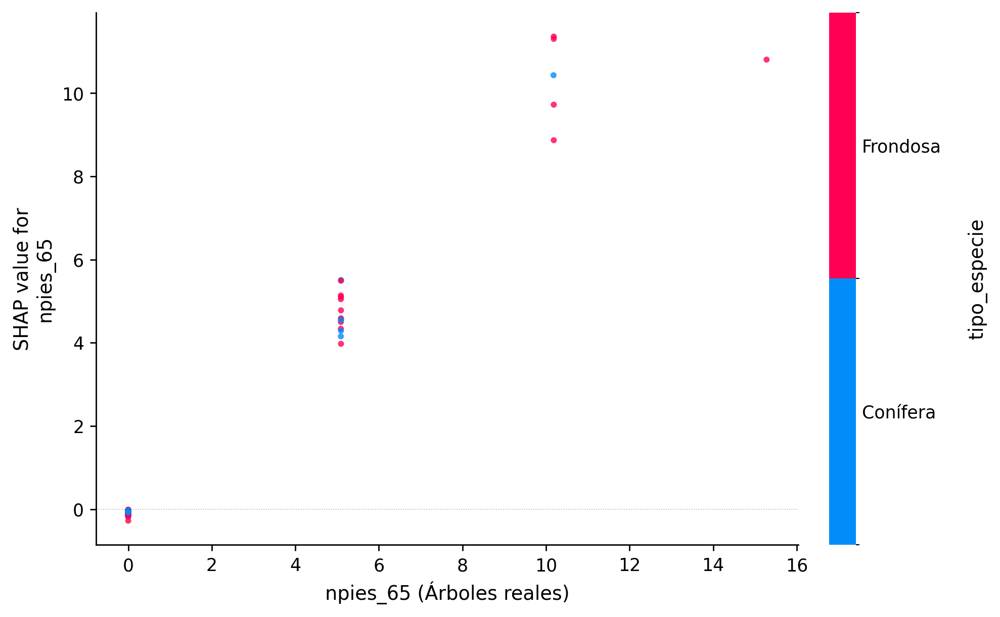

  [OK] npies_70


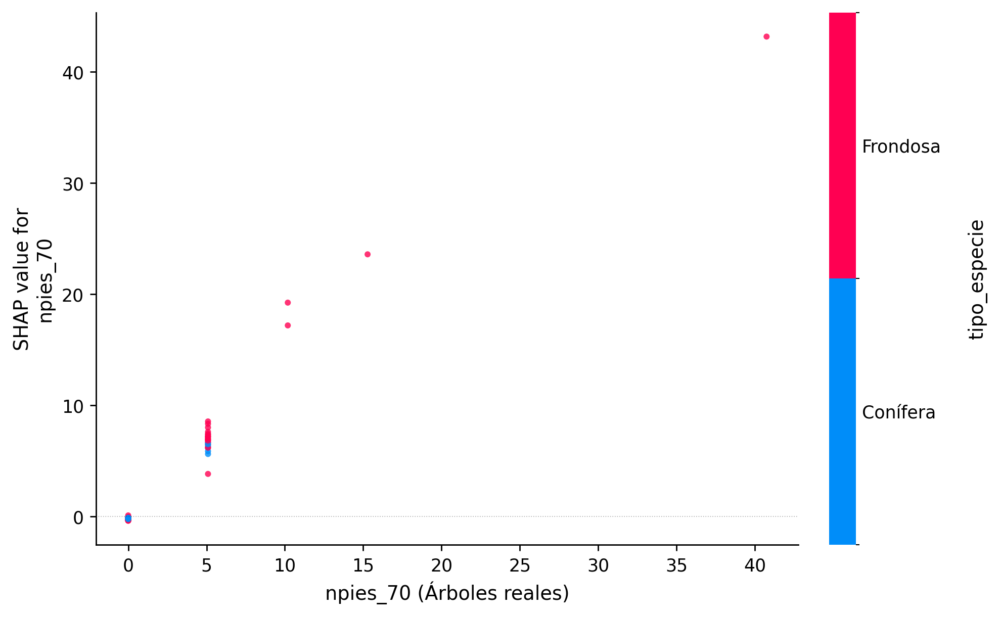

Dependence npies carbono_bruto4 completados.


In [13]:
npies_cols_cb4 = [c for c in FEATURES_CB4 if 'npies_' in c]
cat_codes_cb4  = X_dep_cb4['tipo_especie'].values if 'tipo_especie' in X_dep_cb4.columns else None

out_npies_cb4 = OUTPUT_SHAP / 'carbono_bruto4' / 'dependence_npies'
out_npies_cb4.mkdir(parents=True, exist_ok=True)

for feat in npies_cols_cb4:
    save_path = out_npies_cb4 / f'dep_npies_{feat}.png'
    if save_path.exists() and save_path.with_suffix('.pdf').exists():
        print(f'  [OK] {feat}')
        ipy_display(IPImage(str(save_path)))
        continue
    col = next((f for f in feat_names_cb4 if feat in f), None)
    if col is None or cat_codes_cb4 is None:
        continue
    col_idx = feat_names_cb4.index(col)
    x_vals  = X_dep_cb4[feat].values
    y_shap  = shap_vals_cb4[:, col_idx]

    fig, ax = plt.subplots(figsize=(8, 5))
    norm = mpl.colors.BoundaryNorm([-0.5, 0.5, 1.5], shap_cmap.N)
    ax.scatter(x_vals, y_shap, c=cat_codes_cb4, cmap=shap_cmap,
               s=12, alpha=0.8, edgecolors='none', vmin=0, vmax=1)
    cbar = plt.colorbar(
        mpl.cm.ScalarMappable(norm=norm, cmap=shap_cmap),
        ax=ax, ticks=[0, 1], fraction=0.046, pad=0.04
    )
    cbar.set_ticklabels(['Con\u00edfera', 'Frondosa'])
    cbar.ax.set_ylabel('tipo_especie', rotation=90, labelpad=15, fontsize=11)
    cbar.outline.set_visible(False)
    cbar.ax.tick_params(size=0)
    ax.set_xlabel(f'{feat} (\u00c1rboles reales)', fontsize=11)
    ax.set_ylabel(f'SHAP value for\n{feat}', fontsize=11)
    ax.axhline(0, color='black', linestyle=':', linewidth=0.5, alpha=0.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    plt.tight_layout()
    print(f'  -> {save_path}')
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
    plt.show()
    plt.close()

print('Dependence npies carbono_bruto4 completados.')

---
## 5. Análisis Estructura Diamétrica (npies) — carbono\_bruto4 (IFN2-3)

  BaggedDT... [caché] [caché] 

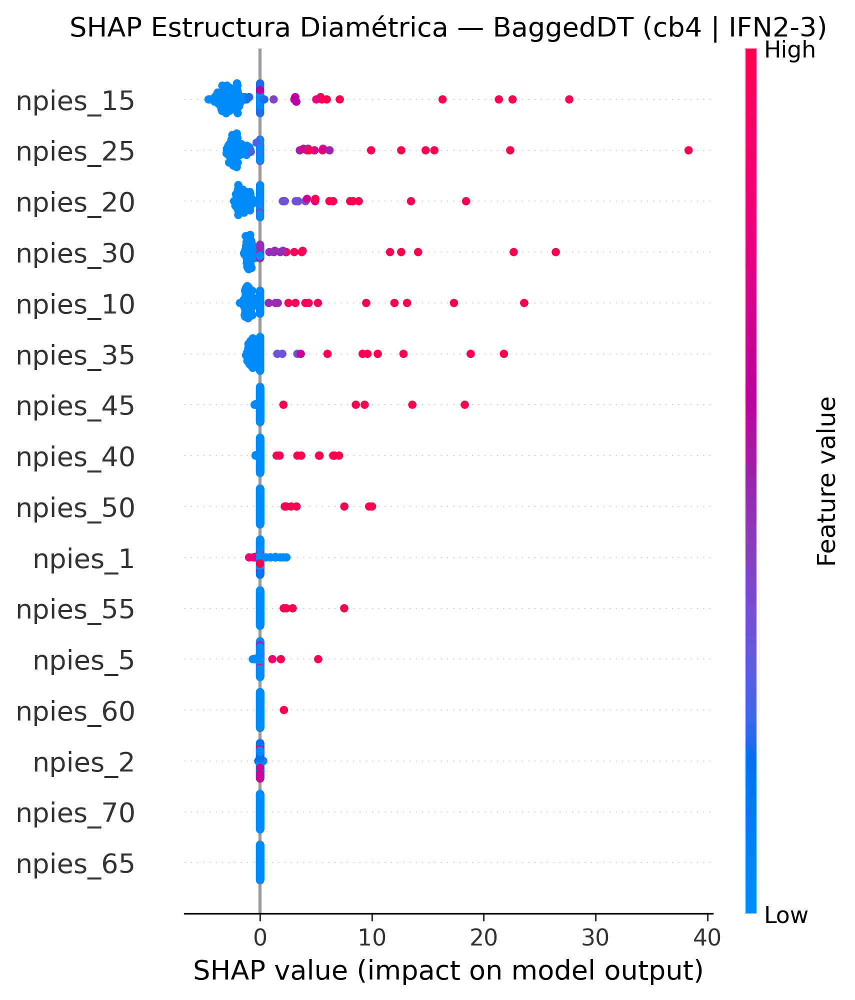

OK
  BayesianNN... [caché] [caché] 

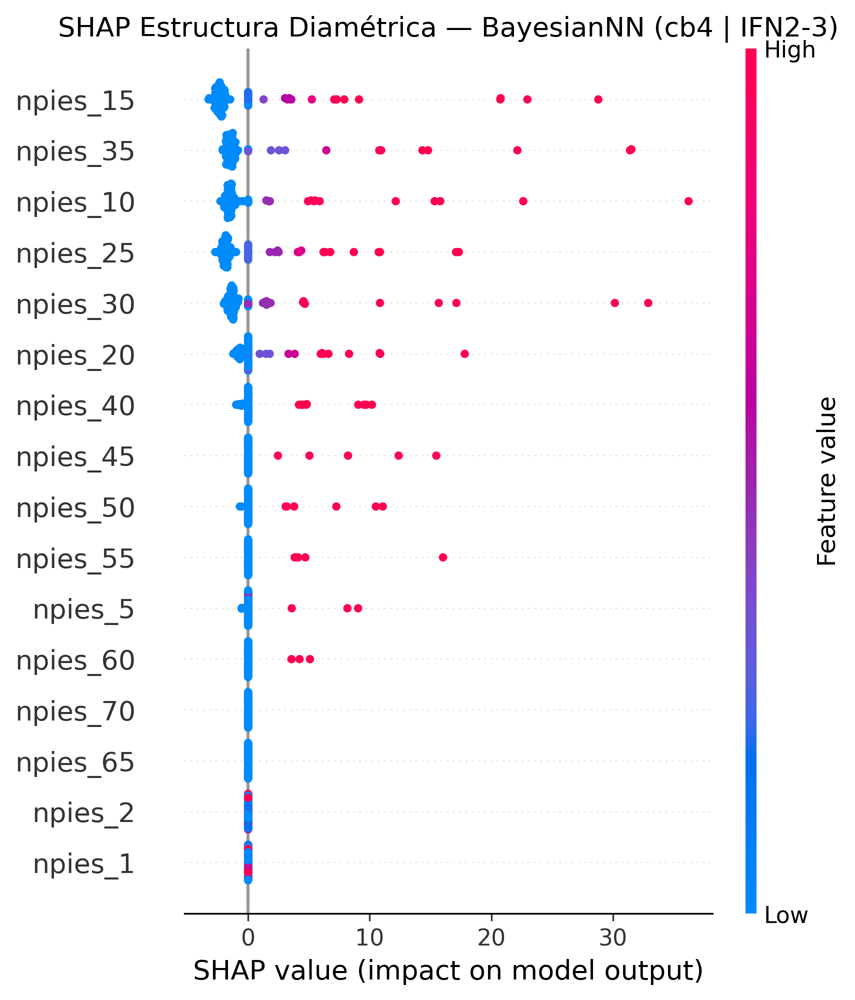

OK
  CatBoost... [caché] [caché] 

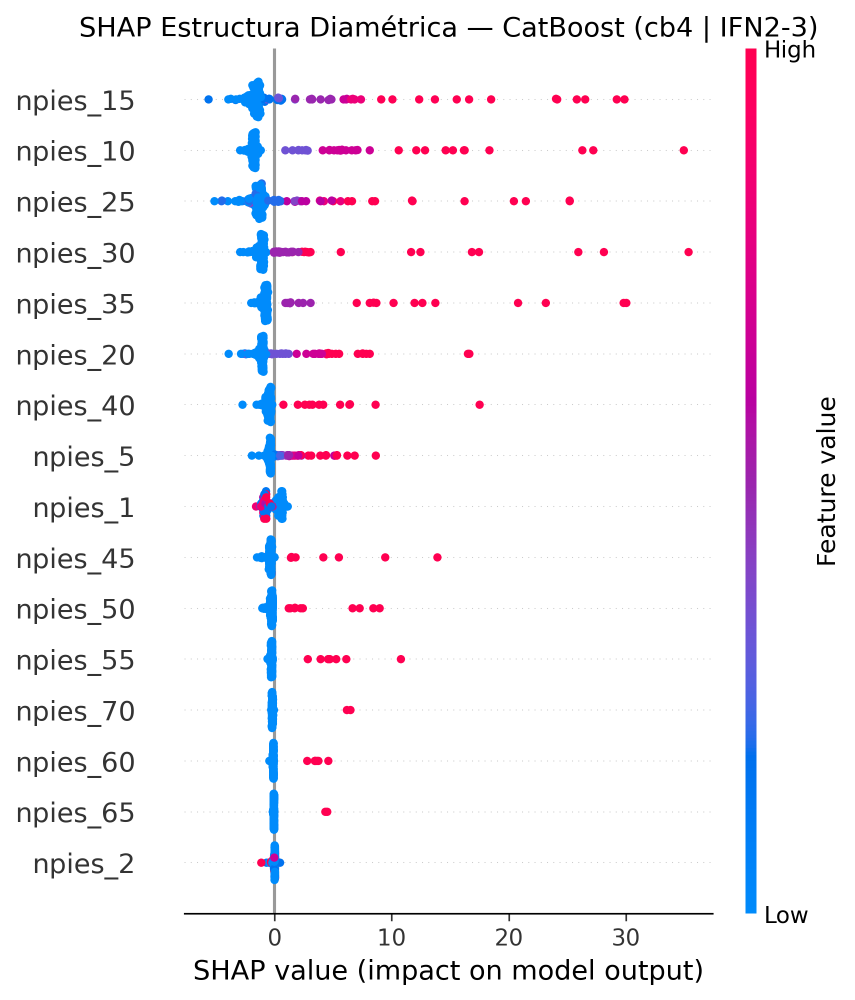

OK
  GBDT... [caché] [caché] 

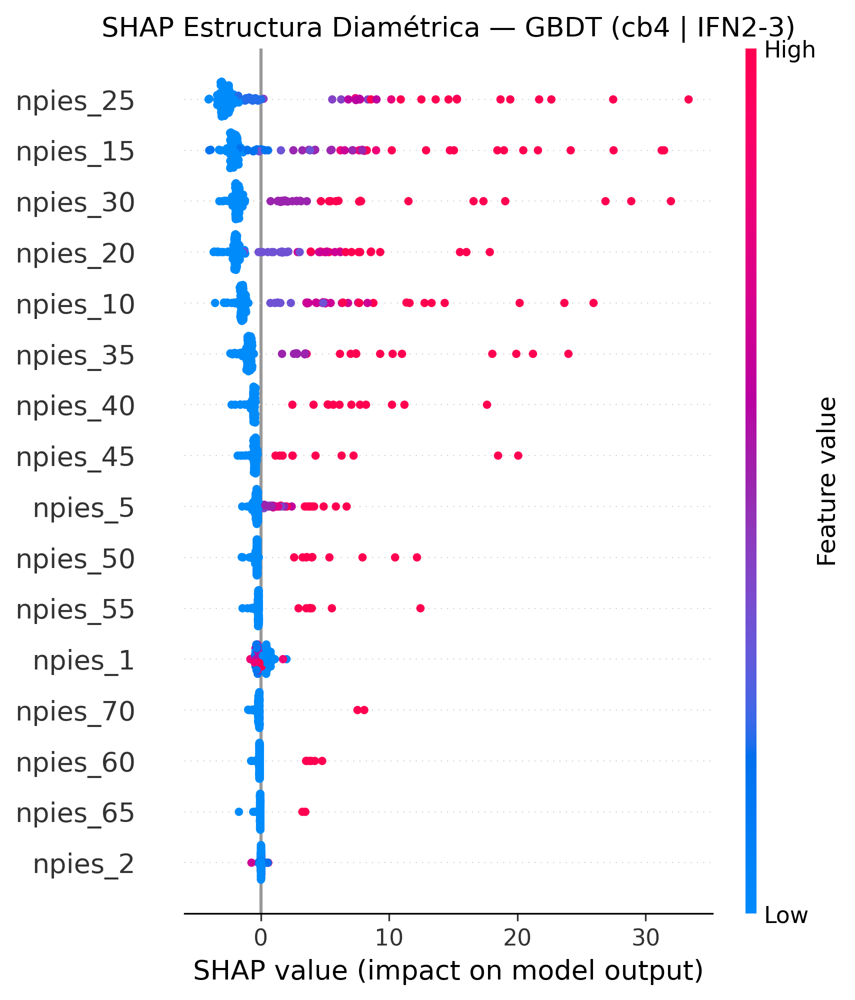

OK
  LightGBM... [caché] [caché] 

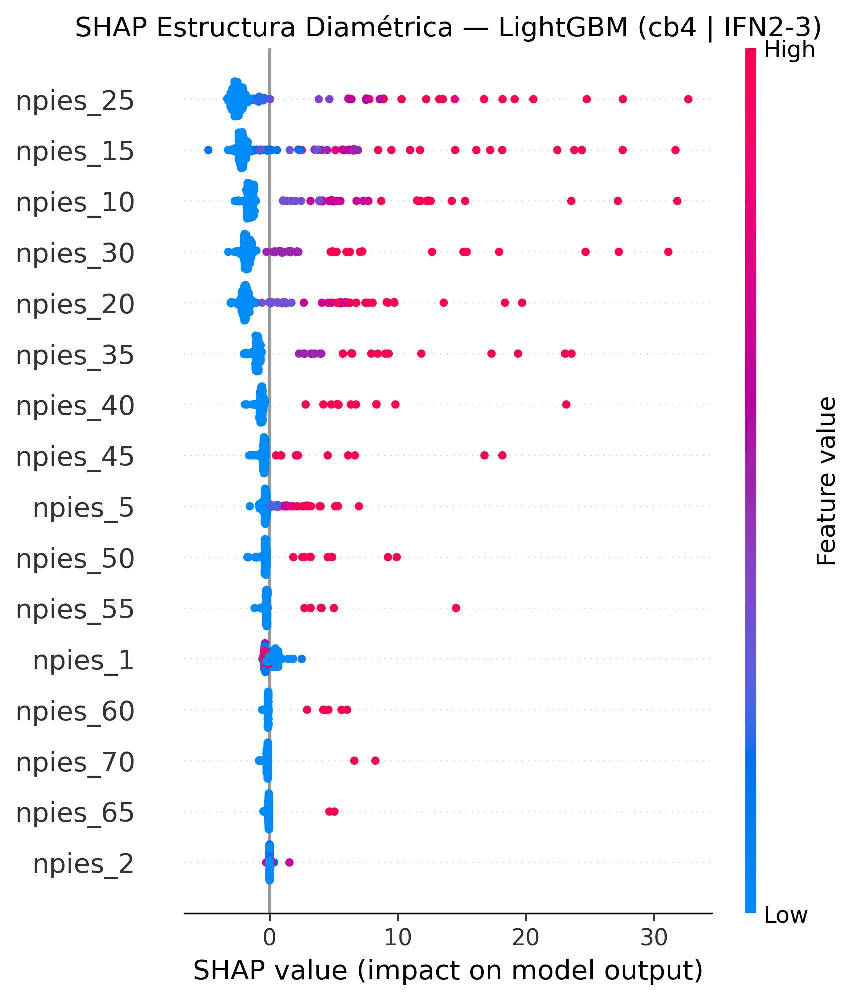

OK
  MLP_PyTorch... [caché] [caché] 

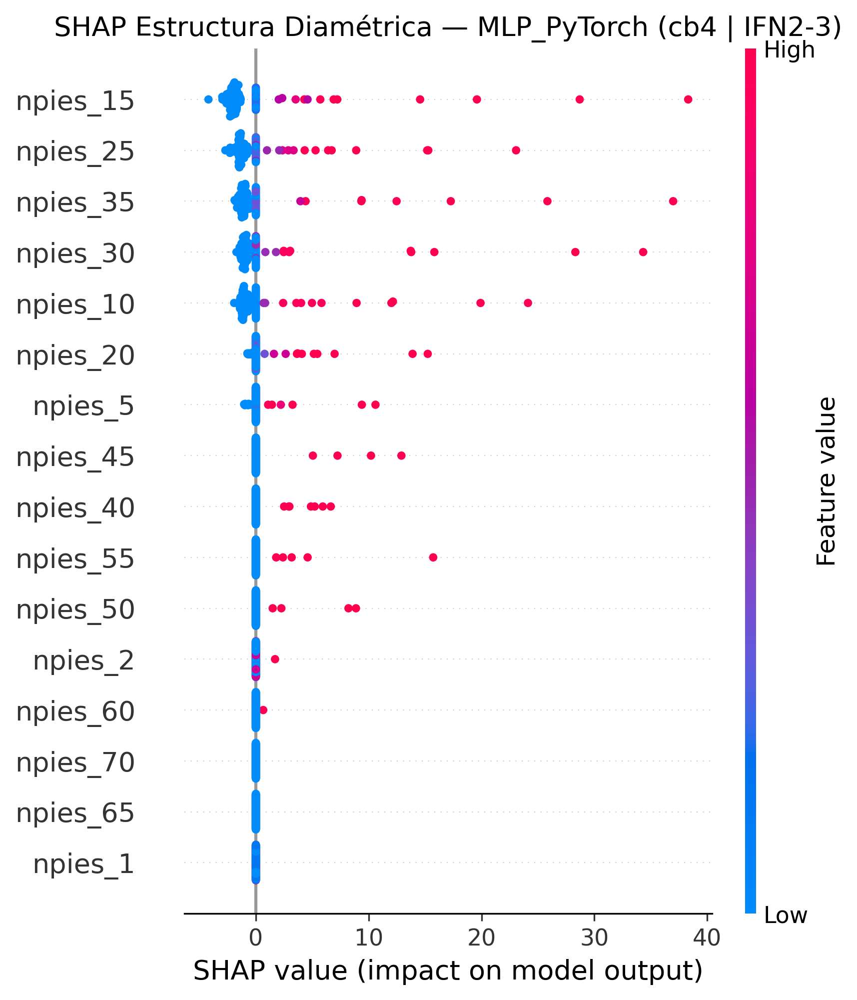

OK
  Random_Forest... [caché] [caché] 

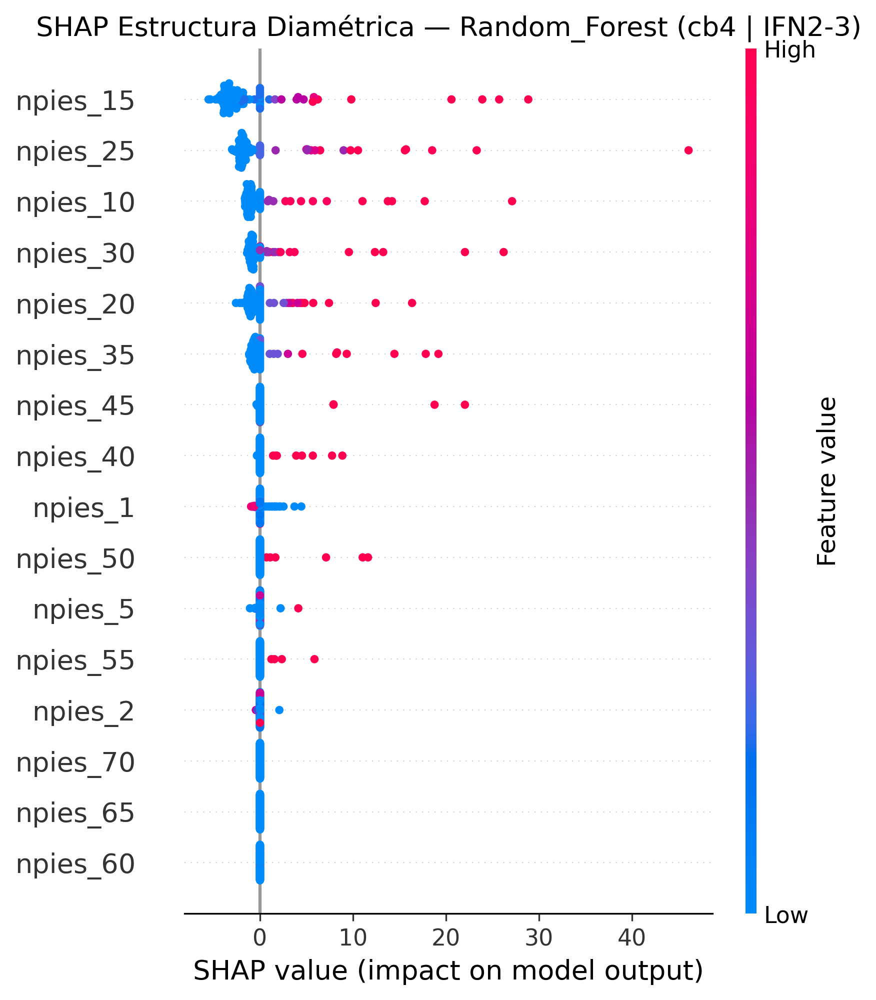

OK
  SVR... [caché] [caché] 

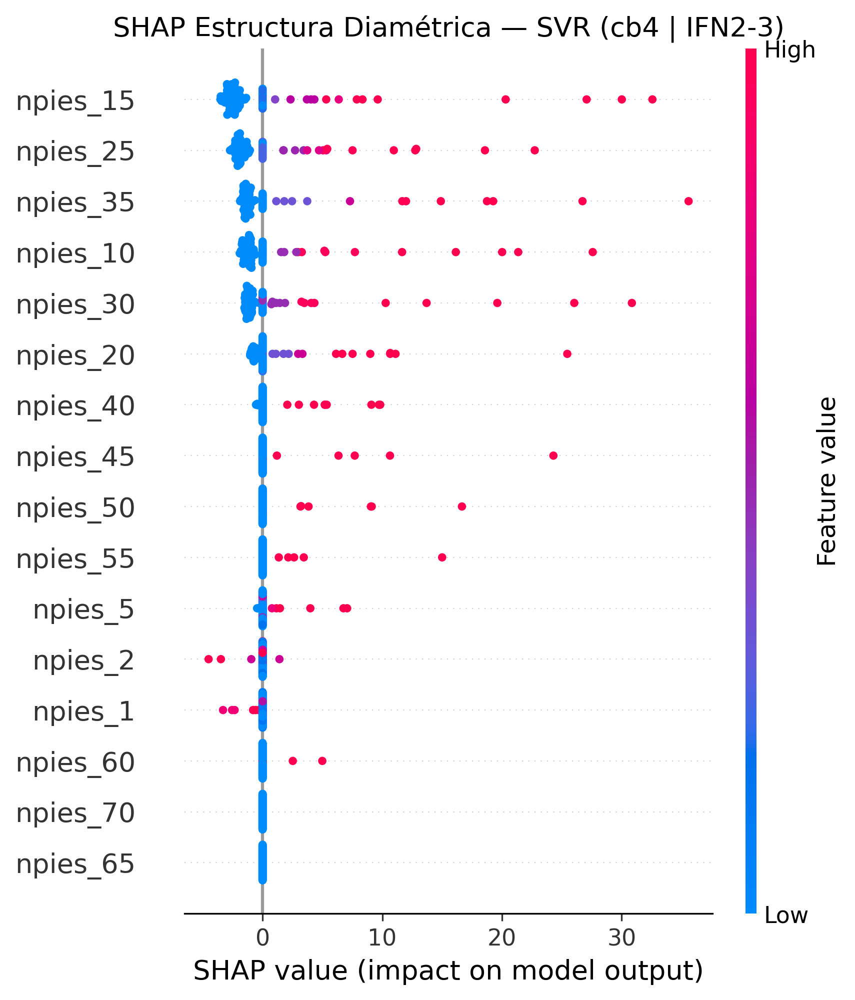

OK
  XGBoost... [caché] [caché] 

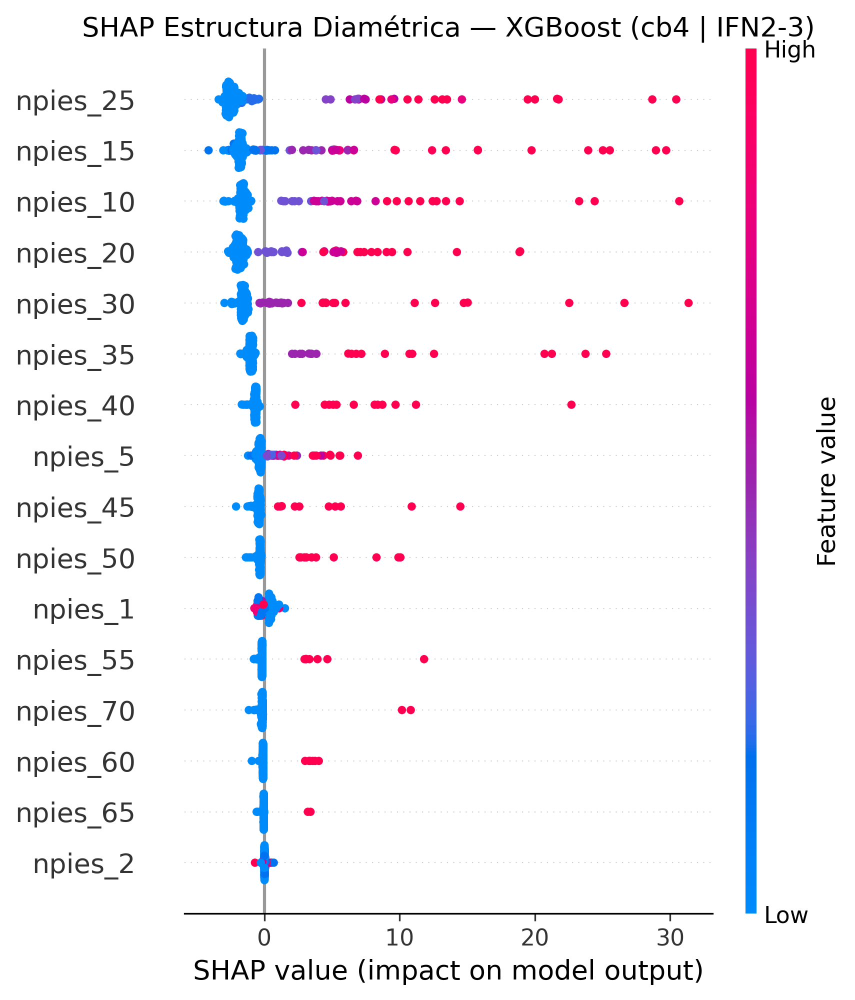

OK

Estadísticas recopiladas: 144 entradas


In [14]:
out_npies_all = OUTPUT_SHAP / 'carbono_bruto4' / 'npies_analysis'
out_npies_all.mkdir(parents=True, exist_ok=True)

stats_all = []

for fname in model_files_cb4:
    model_name = fname.replace('.joblib', '')
    model_path = MODELS_IFN23_CB4 / fname
    cache_path = CACHE_SHAP / 'base' / 'carbono_bruto4' / f'{model_name}.joblib'

    print(f'  {model_name}...', end=' ')
    try:
        sv, fn, Xt_df, Xr_used, base_val = load_or_compute_shap(
            model_path, X_sample_cb4, X_bg_cb4, model_name, cache_path=cache_path
        )

        npies_idx = [i for i, f in enumerate(fn) if f.startswith('npies')]
        if not npies_idx:
            print('sin npies features, omitiendo')
            continue

        sv_npies = sv[:, npies_idx]
        fn_npies = [fn[i] for i in npies_idx]

        save_bee = out_npies_all / f'beeswarm_npies_{model_name}.png'
        if save_bee.exists() and save_bee.with_suffix('.pdf').exists():
            print('[caché] ', end='')
            ipy_display(IPImage(str(save_bee)))
        else:
            expl = shap.Explanation(
                values=sv_npies, base_values=base_val,
                data=Xt_df.iloc[:, npies_idx].values, feature_names=fn_npies
            )
            fig, ax = plt.subplots(figsize=(10, 8))
            shap.plots.beeswarm(expl, max_display=30, show=False)
            plt.title(f'SHAP Estructura Diamétrica — {model_name} (cb4 | IFN2-3)', fontsize=13)
            plt.subplots_adjust(left=0.35, bottom=0.15)
            print(f'  -> {save_bee}')
            plt.savefig(save_bee, dpi=300, bbox_inches='tight')
            plt.savefig(save_bee.with_suffix('.pdf'), bbox_inches='tight')
            plt.show()
            plt.close()

        for i, fname_npies in enumerate(fn_npies):
            m = re.search(r'npies_(\d+)', fname_npies)
            if m:
                cd = int(m.group(1))
                col_sv = sv_npies[:, i]
                stats_all.append({
                    'Model': model_name,
                    'Clase_Diametrica': cd,
                    'Mean_Abs_SHAP': float(np.mean(np.abs(col_sv))),
                    'Mean_Raw_SHAP': float(np.mean(col_sv)),
                    'Median_Raw_SHAP': float(np.median(col_sv))
                })
        print('OK')
    except Exception as e:
        print(f'ERROR: {e}')
    finally:
        gc.collect()

print(f'\nEstadísticas recopiladas: {len(stats_all)} entradas')

CSV guardado: ../../figures/shap_ifn2_3/carbono_bruto4/npies_analysis/shap_npies_consolidado.csv
  -> ../../figures/shap_ifn2_3/carbono_bruto4/npies_analysis/consolidado_npies_importancia.png


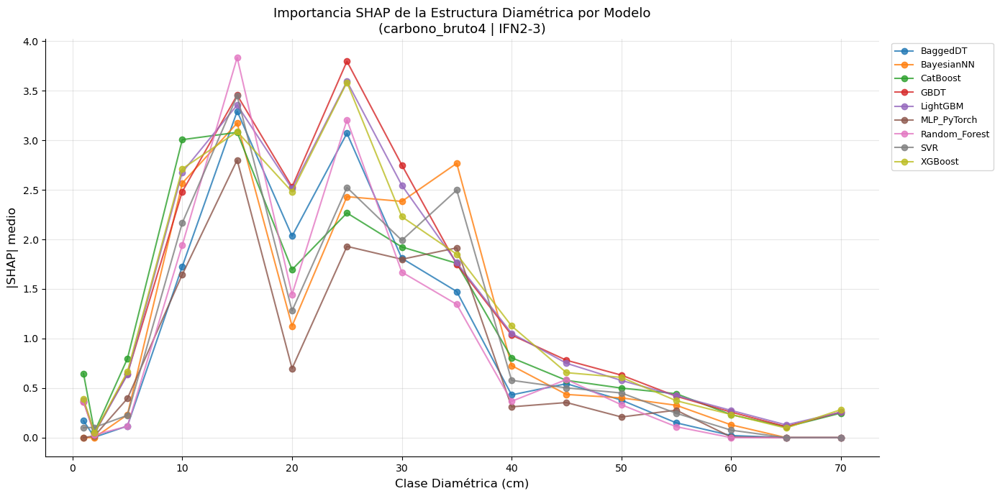

  -> ../../figures/shap_ifn2_3/carbono_bruto4/npies_analysis/consolidado_npies_direccion.png


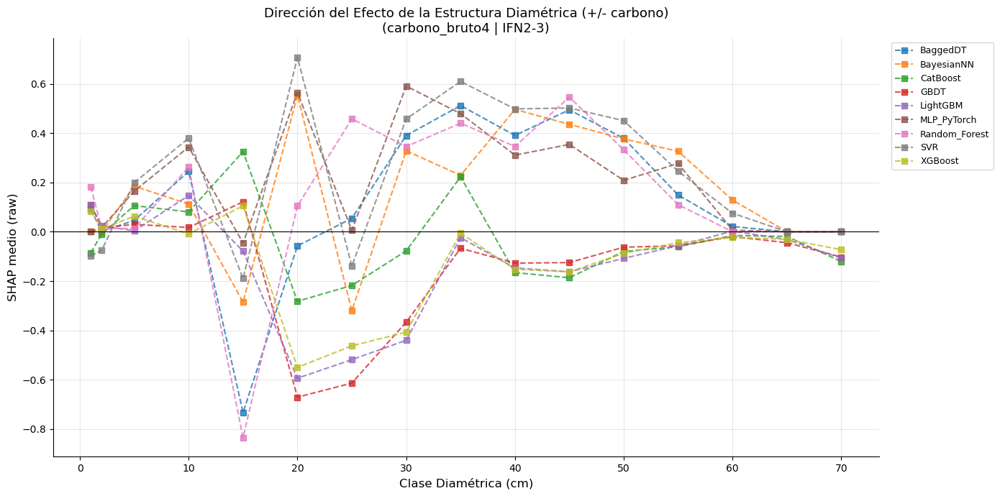

Model,BaggedDT,BayesianNN,CatBoost,GBDT,LightGBM,MLP_PyTorch,Random_Forest,SVR,XGBoost
Clase_Diametrica,,,,,,,,,
1,0.1697,0.0000,0.6469,0.3634,0.3770,0.0000,0.3642,0.0990,0.3916
2,0.0045,0.0000,0.0577,0.0451,0.0428,0.0170,0.0284,0.1035,0.0464
5,0.1170,0.2311,0.7965,0.6436,0.6337,0.3944,0.1136,0.2248,0.6650
10,1.7273,2.5679,3.0064,2.4823,2.6778,1.6455,1.9430,2.1664,2.7123
15,3.2932,3.1732,3.0800,3.4555,3.3560,2.8012,3.8347,3.4484,3.0872
20,2.0335,1.1263,1.6951,2.5304,2.5117,0.6979,1.4454,1.2800,2.4807
25,3.0710,2.4312,2.2667,3.7966,3.5940,1.9297,3.2057,2.5235,3.5834
30,1.8093,2.3837,1.9236,2.7505,2.5457,1.7998,1.6697,1.9910,2.2290
35,1.4744,2.7674,1.7590,1.7491,1.7652,1.9143,1.3446,2.4976,1.8506



Análisis SHAP IFN2-3 completado.


In [15]:
if stats_all:
    df_stats = pd.DataFrame(stats_all).sort_values(['Model', 'Clase_Diametrica'])

    csv_path = out_npies_all / 'shap_npies_consolidado.csv'
    df_stats.to_csv(csv_path, index=False)
    print(f'CSV guardado: {csv_path}')

    fig, ax = plt.subplots(figsize=(14, 7))
    for model in sorted(df_stats['Model'].unique()):
        sub = df_stats[df_stats['Model'] == model]
        ax.plot(sub['Clase_Diametrica'], sub['Mean_Abs_SHAP'],
                marker='o', label=model, alpha=0.8, linewidth=1.5)
    ax.set_xlabel('Clase Diamétrica (cm)', fontsize=12)
    ax.set_ylabel('|SHAP| medio', fontsize=12)
    ax.set_title('Importancia SHAP de la Estructura Diamétrica por Modelo\n(carbono_bruto4 | IFN2-3)', fontsize=13)
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    print(f'  -> {out_npies_all / "consolidado_npies_importancia.png"}')
    plt.savefig(out_npies_all / 'consolidado_npies_importancia.png', dpi=300)
    plt.savefig(out_npies_all / 'consolidado_npies_importancia.pdf')
    plt.show()
    plt.close()

    fig, ax = plt.subplots(figsize=(14, 7))
    for model in sorted(df_stats['Model'].unique()):
        sub = df_stats[df_stats['Model'] == model]
        ax.plot(sub['Clase_Diametrica'], sub['Mean_Raw_SHAP'],
                marker='s', label=model, linestyle='--', alpha=0.8, linewidth=1.5)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xlabel('Clase Diamétrica (cm)', fontsize=12)
    ax.set_ylabel('SHAP medio (raw)', fontsize=12)
    ax.set_title('Dirección del Efecto de la Estructura Diamétrica (+/- carbono)\n(carbono_bruto4 | IFN2-3)', fontsize=13)
    ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    print(f'  -> {out_npies_all / "consolidado_npies_direccion.png"}')
    plt.savefig(out_npies_all / 'consolidado_npies_direccion.png', dpi=300)
    plt.savefig(out_npies_all / 'consolidado_npies_direccion.pdf')
    plt.show()
    plt.close()

    ipy_display(df_stats.pivot_table(
        index='Clase_Diametrica', columns='Model',
        values='Mean_Abs_SHAP', aggfunc='mean'
    ).round(4))
else:
    print('No hay datos de npies para graficar.')

print('\nAnálisis SHAP IFN2-3 completado.')

---
## 6. SHAP Beeswarm — Modelos Stacking (c4, IFN2-3)

In [16]:
def make_meta_features(base_names, base_models_dir, X_raw, features):
    present = [c for c in features if c in X_raw.columns]
    preds = {}
    for name in base_names:
        path = base_models_dir / f'{name}.joblib'
        print(f'    [{name}]...', end=' ')
        pipe = None
        try:
            pipe = joblib.load(path)
            preds[name] = pipe.predict(X_raw[present])
            print('OK')
        except Exception as e:
            print(f'ERROR: {e}')
            preds[name] = np.zeros(len(X_raw))
        finally:
            if pipe is not None:
                del pipe
            gc.collect()
    return pd.DataFrame(preds)


def compute_meta_shap(meta_pipe, X_meta):
    scaler = meta_pipe.named_steps['scaler']
    meta   = meta_pipe.named_steps['meta']
    X_scaled = pd.DataFrame(scaler.transform(X_meta), columns=X_meta.columns)

    meta_type = type(meta).__name__

    if any(t in meta_type for t in ['GradientBoosting', 'RandomForest']):
        explainer = shap.TreeExplainer(meta)
        shap_vals = explainer.shap_values(X_scaled)
    elif any(t in meta_type for t in ['LinearRegression', 'Ridge', 'BayesianRidge']):
        explainer = shap.LinearExplainer(meta, X_scaled)
        shap_vals = explainer.shap_values(X_scaled)
    else:
        bg = shap.kmeans(X_scaled, min(5, len(X_scaled)))
        explainer = shap.KernelExplainer(meta.predict, bg)
        shap_vals = explainer.shap_values(X_scaled)

    if isinstance(shap_vals, list):
        shap_vals = shap_vals[0]
    base_val = explainer.expected_value
    if isinstance(base_val, (list, np.ndarray)):
        base_val = float(base_val[0])

    return shap_vals, X_scaled, base_val


print('Funciones stacking SHAP OK')

Funciones stacking SHAP OK



Stack1 (c4) — bases: ['LightGBM', 'Random_Forest']
  Todos los plots existen — mostrando desde disco
  [OK] Stack1_GradientBoosting


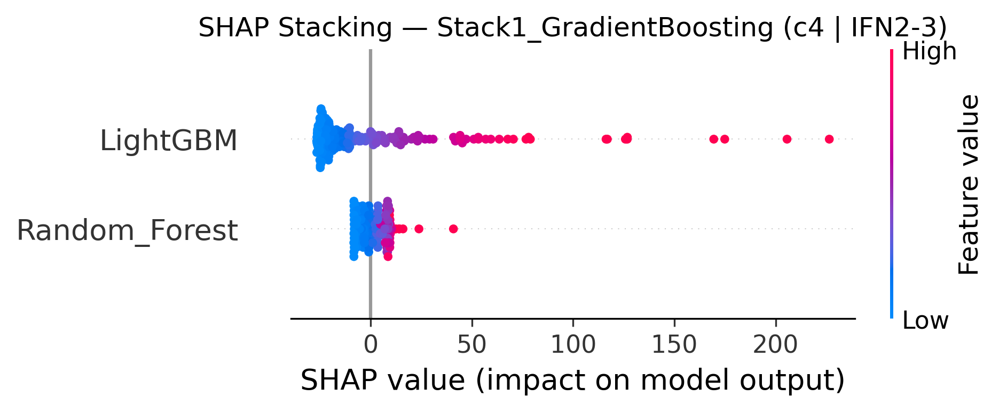

  [OK] Stack1_LinearRegression


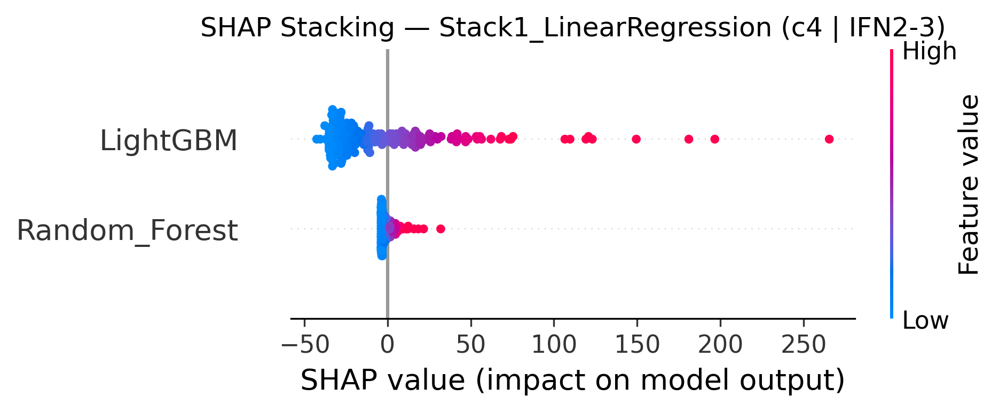

  [OK] Stack1_MLP


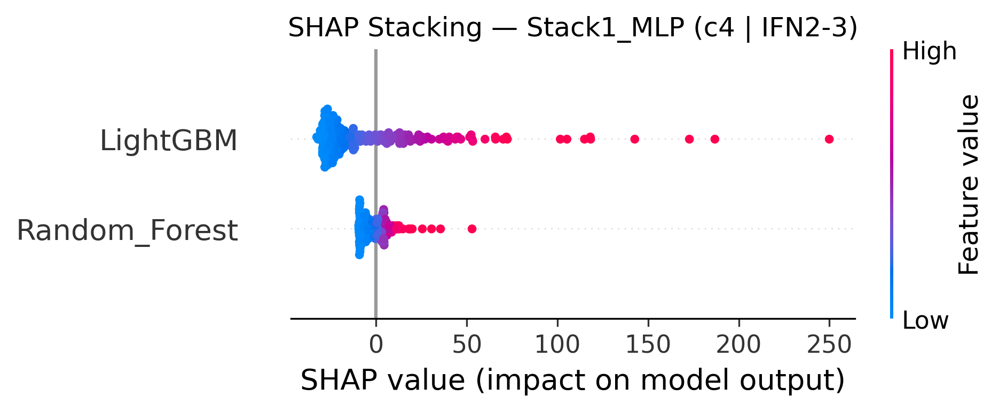

  [OK] Stack1_RandomForest


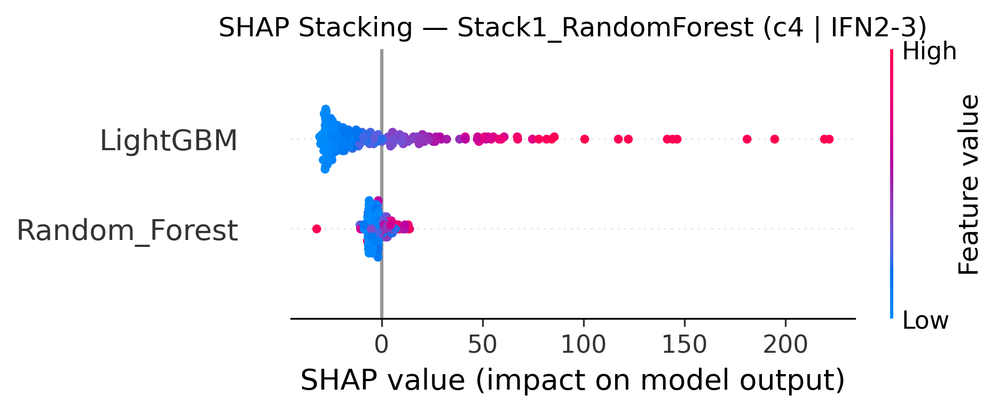

  [OK] Stack1_Ridge


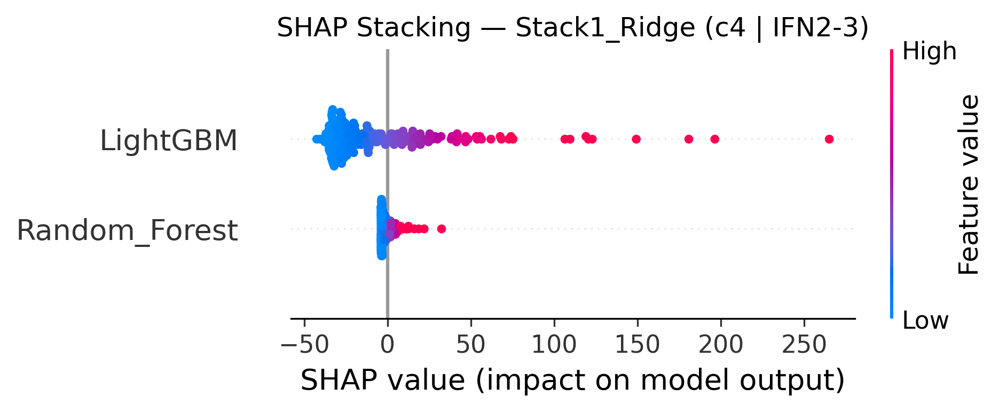

  [OK] Stack1_SVR


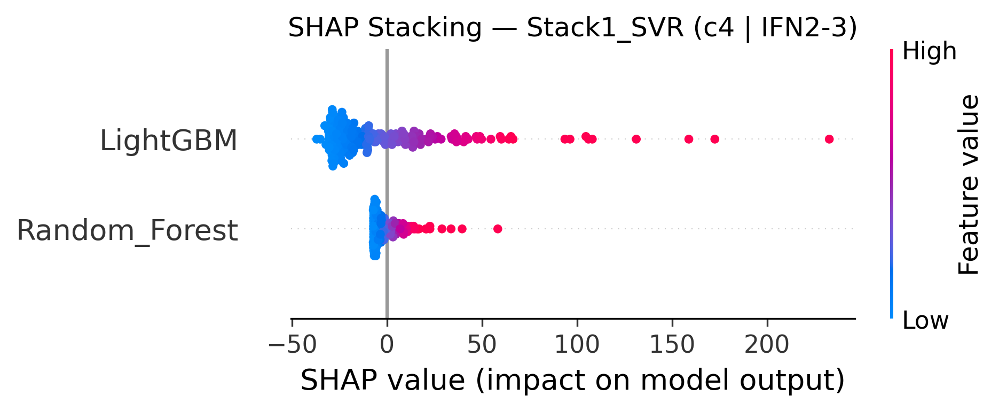


Stack2 (c4) — bases: ['LightGBM', 'XGBoost', 'GBDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack2_GradientBoosting


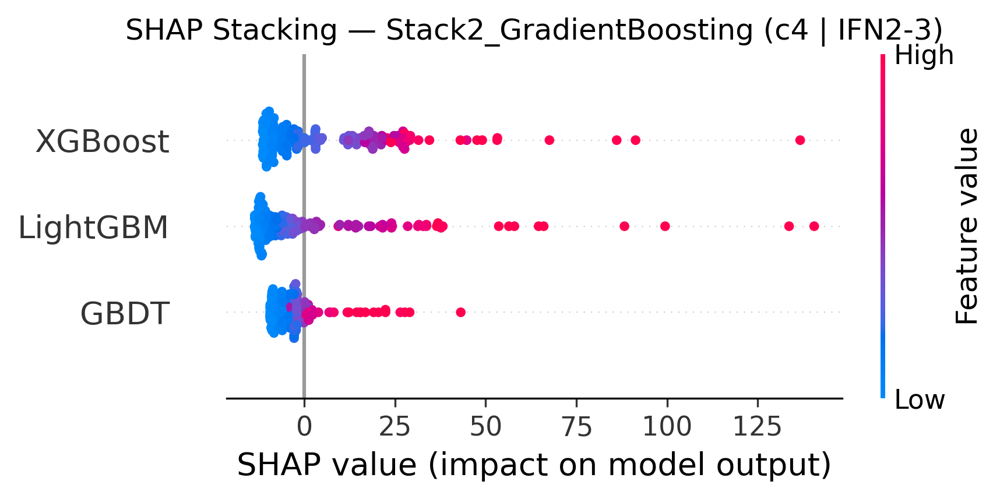

  [OK] Stack2_LinearRegression


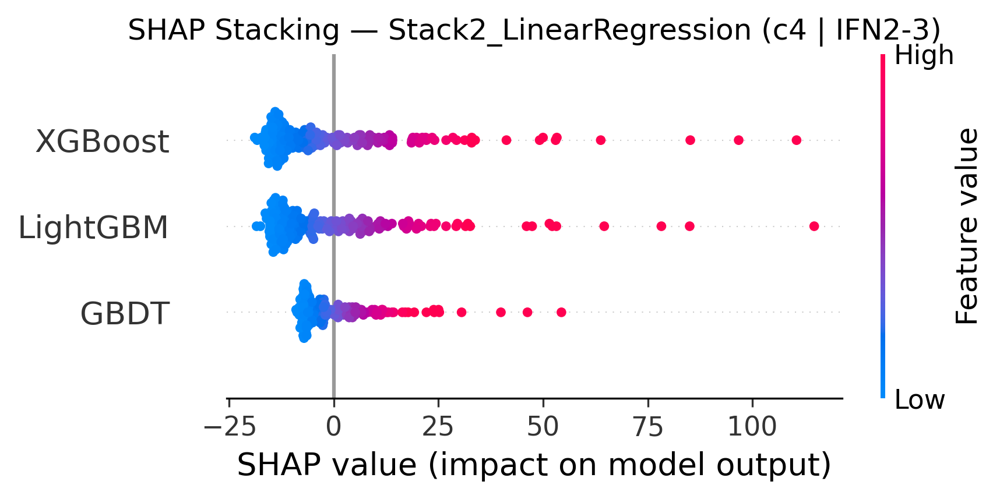

  [OK] Stack2_MLP


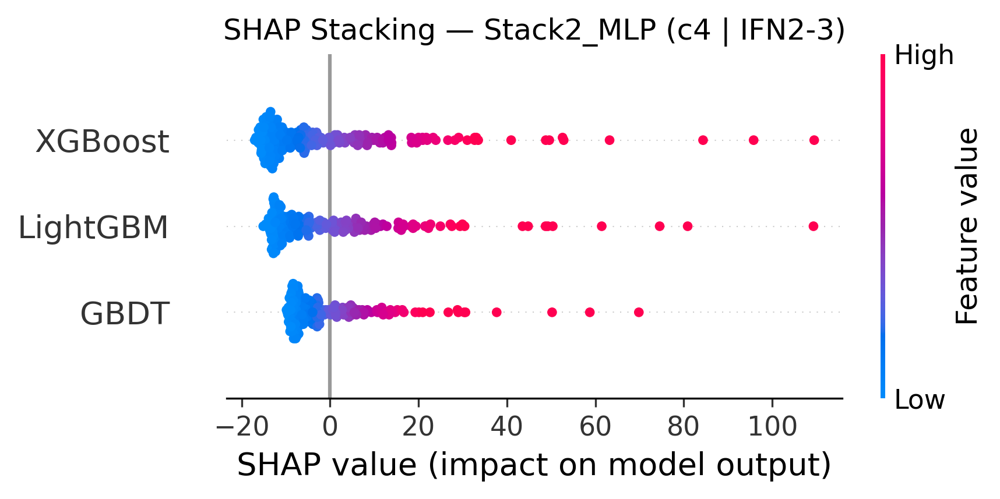

  [OK] Stack2_RandomForest


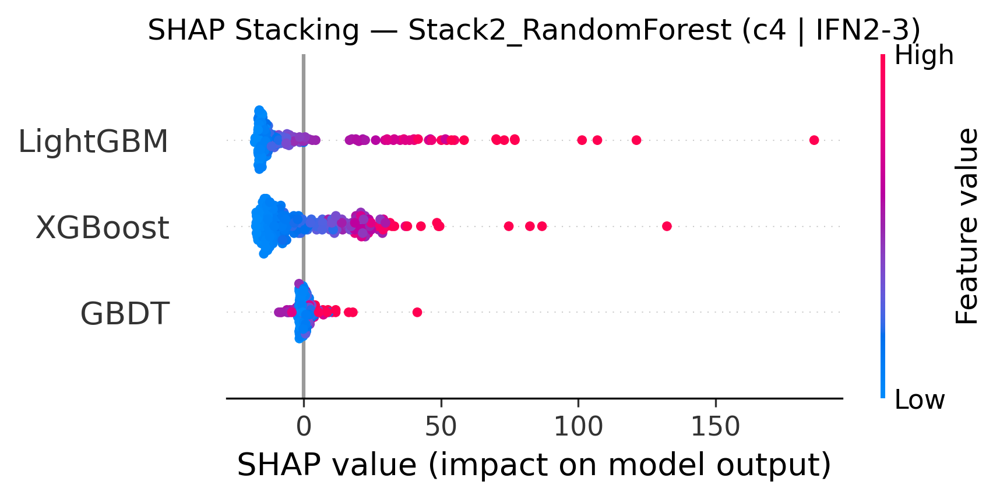

  [OK] Stack2_Ridge


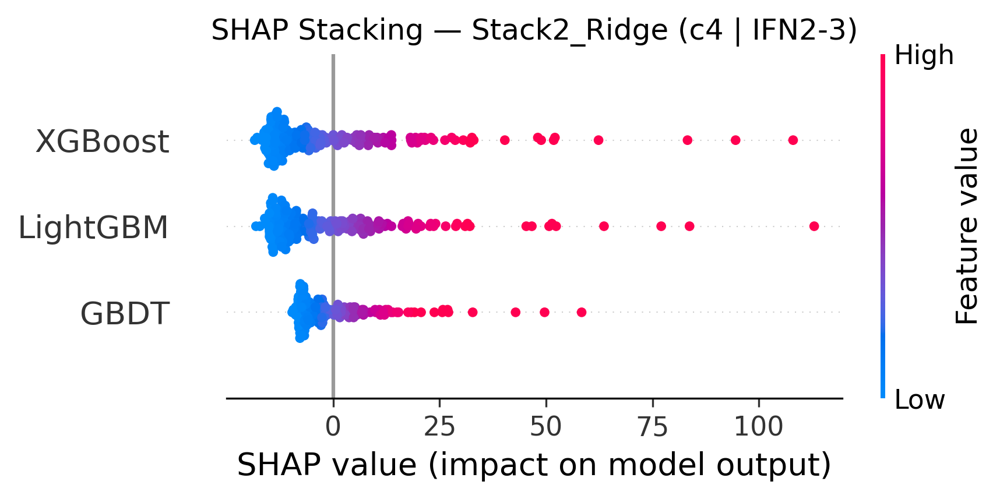

  [OK] Stack2_SVR


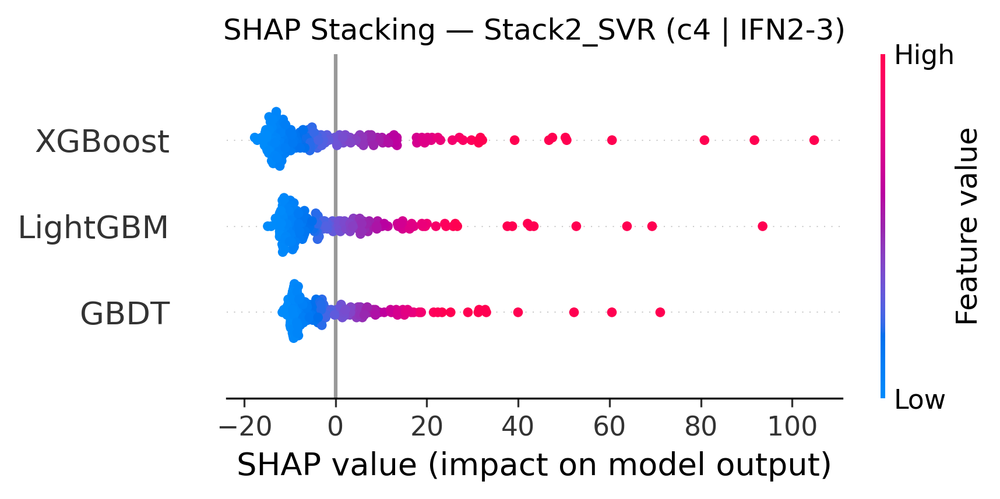


Stack3 (c4) — bases: ['CatBoost', 'Random_Forest', 'GBDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack3_GradientBoosting


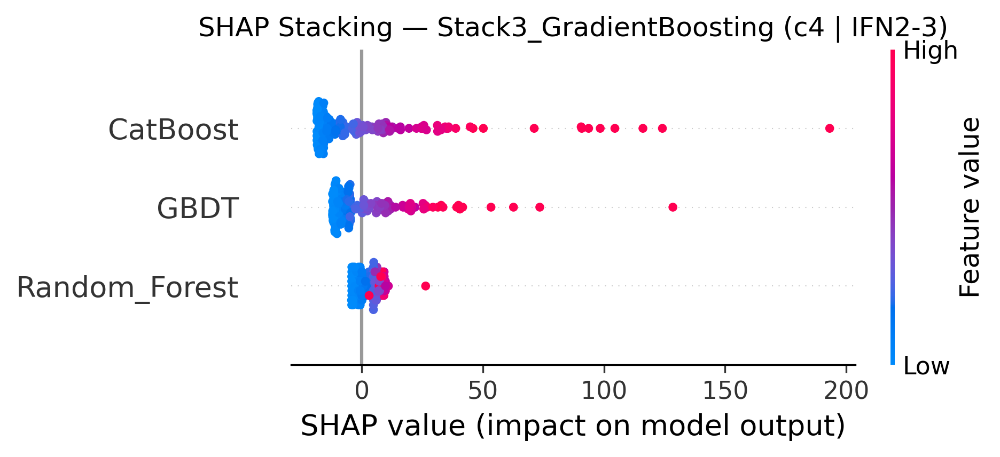

  [OK] Stack3_LinearRegression


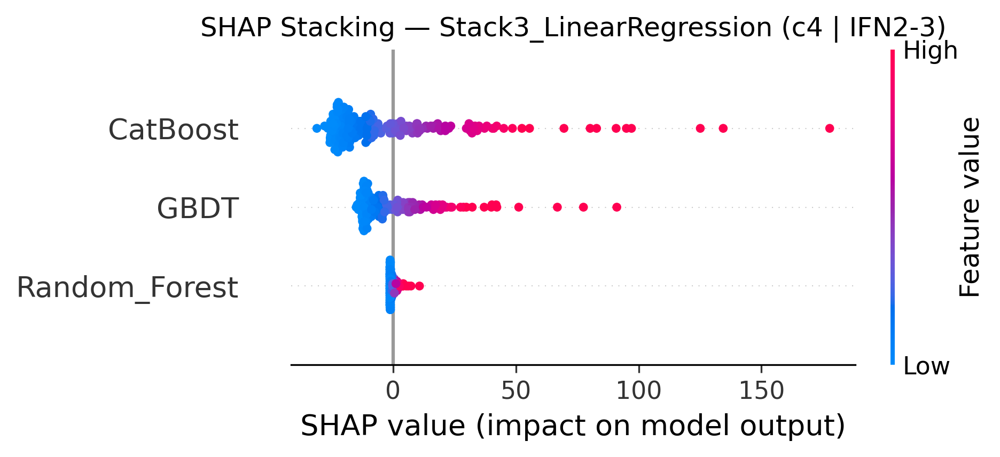

  [OK] Stack3_MLP


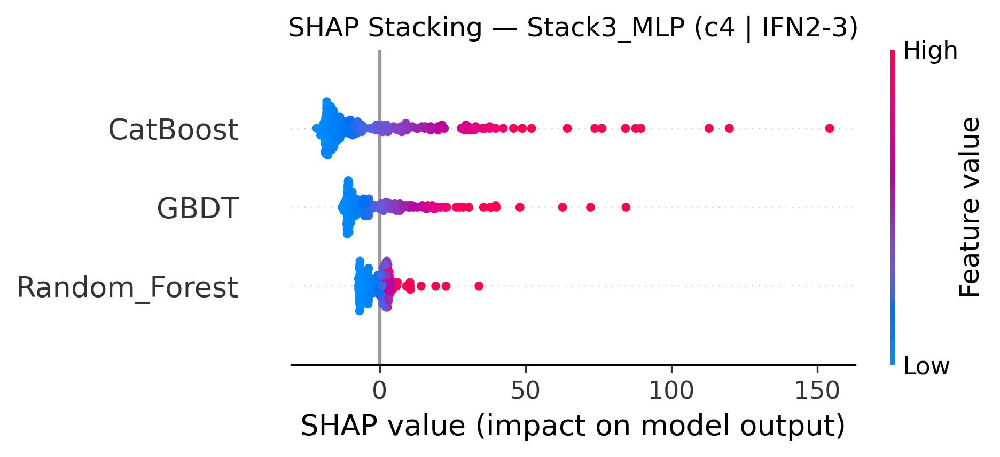

  [OK] Stack3_RandomForest


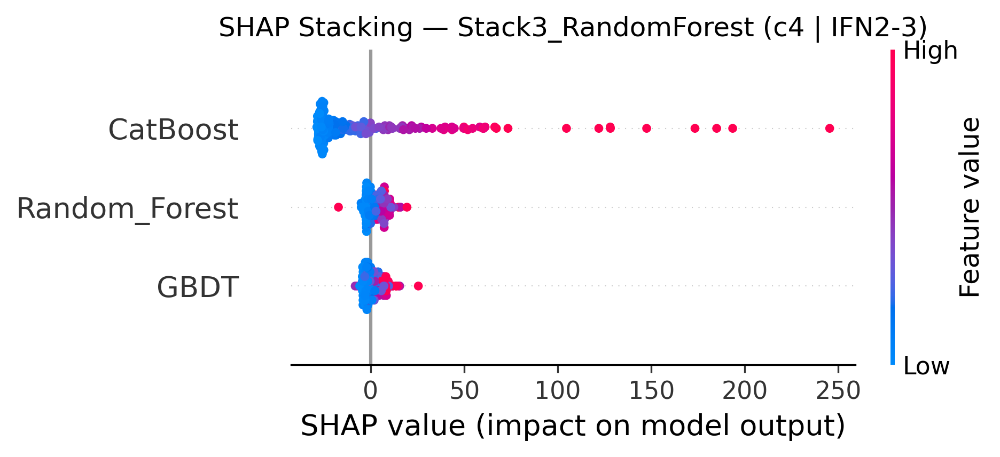

  [OK] Stack3_Ridge


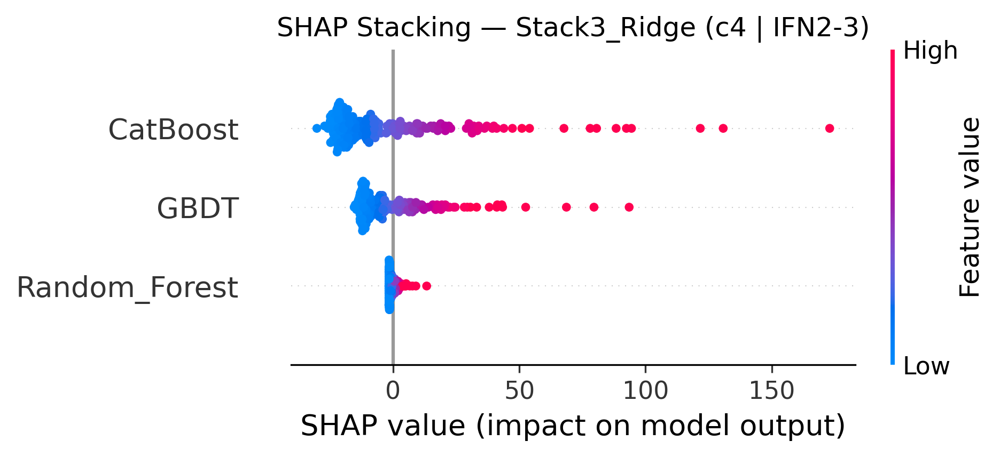

  [OK] Stack3_SVR


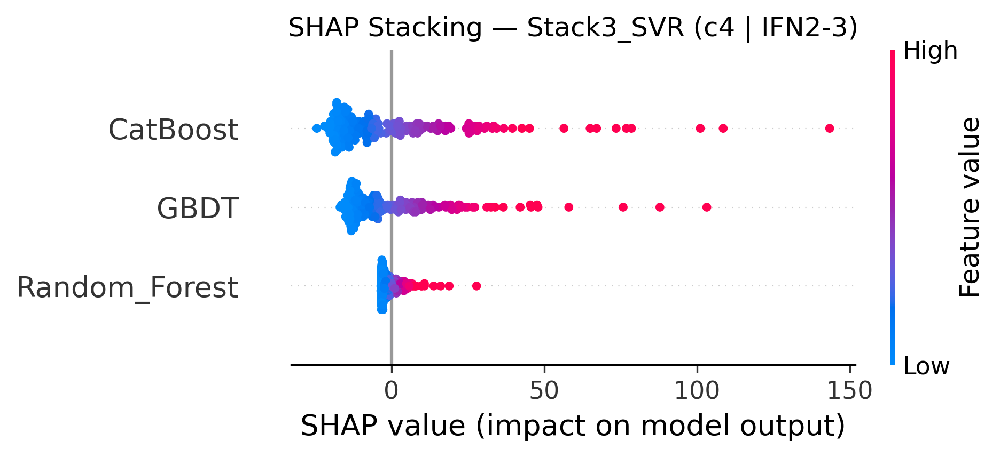


Stack4 (c4) — bases: ['CatBoost', 'LightGBM', 'Random_Forest', 'GBDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack4_GradientBoosting


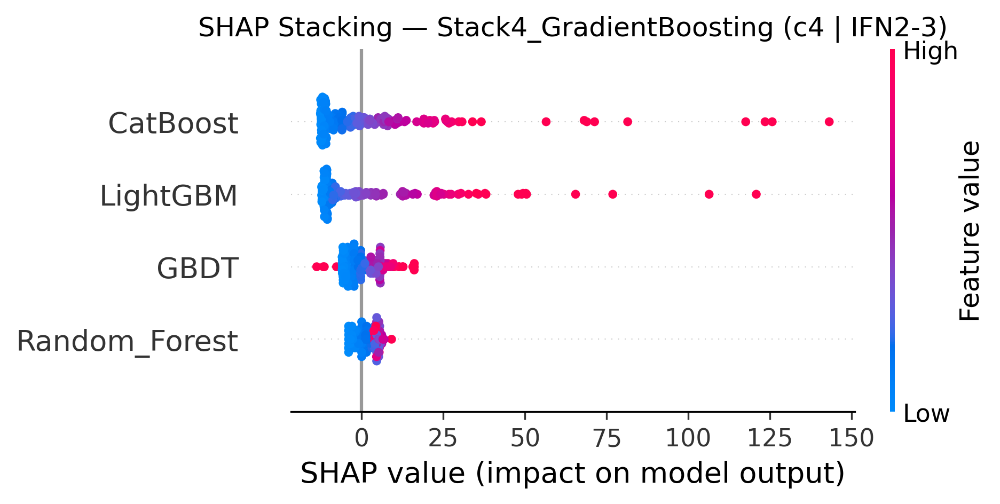

  [OK] Stack4_LinearRegression


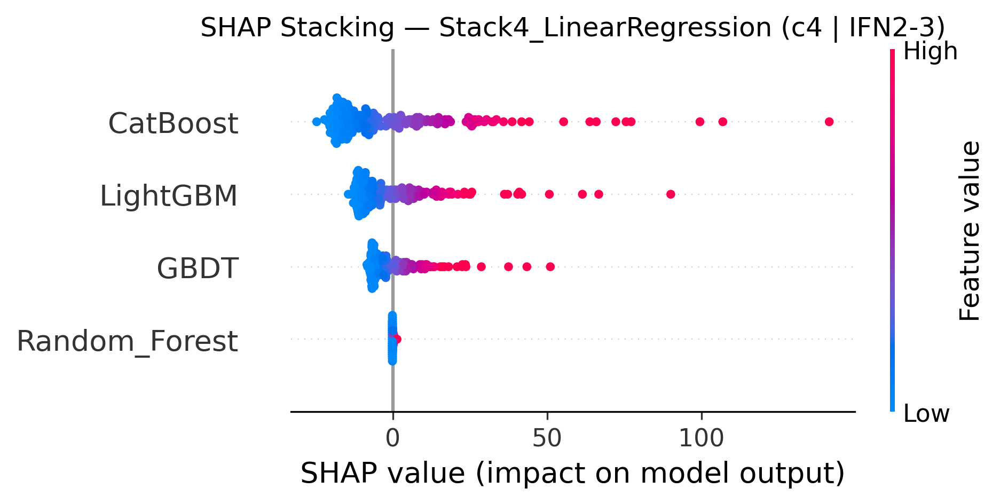

  [OK] Stack4_MLP


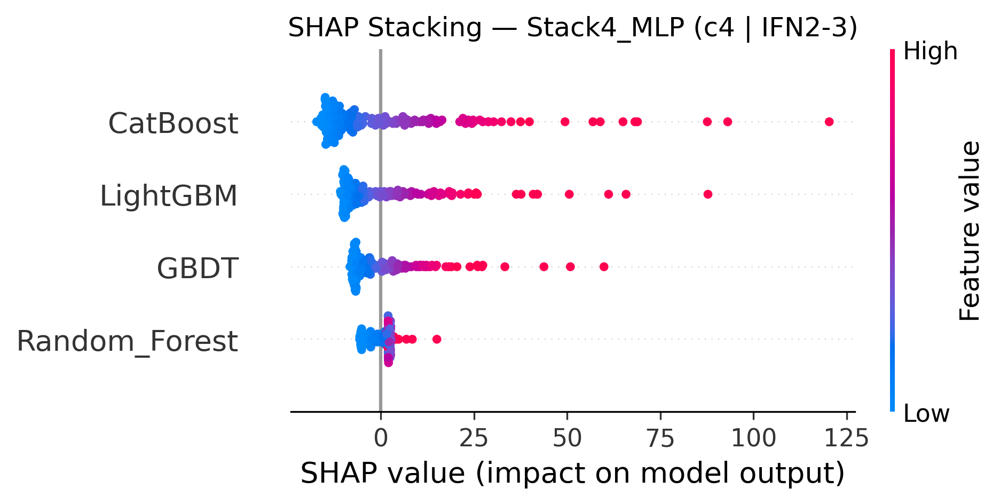

  [OK] Stack4_RandomForest


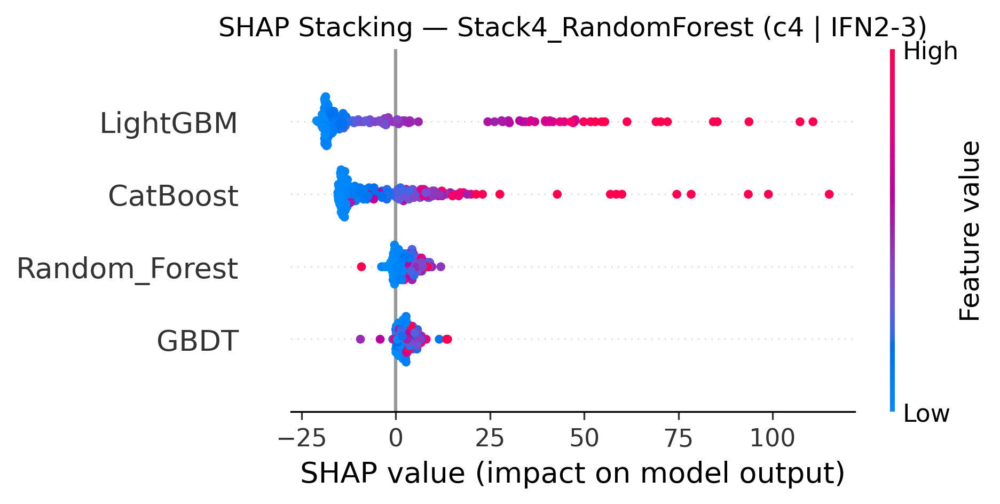

  [OK] Stack4_Ridge


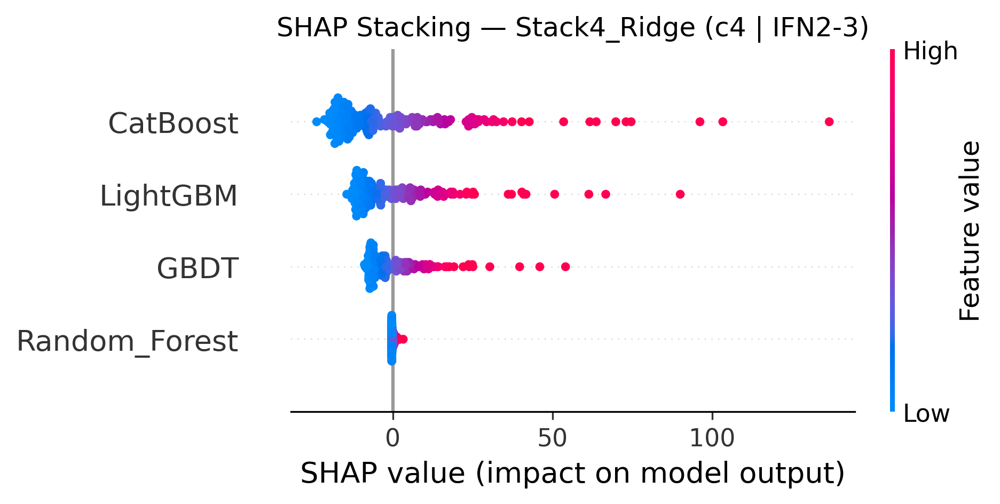

  [OK] Stack4_SVR


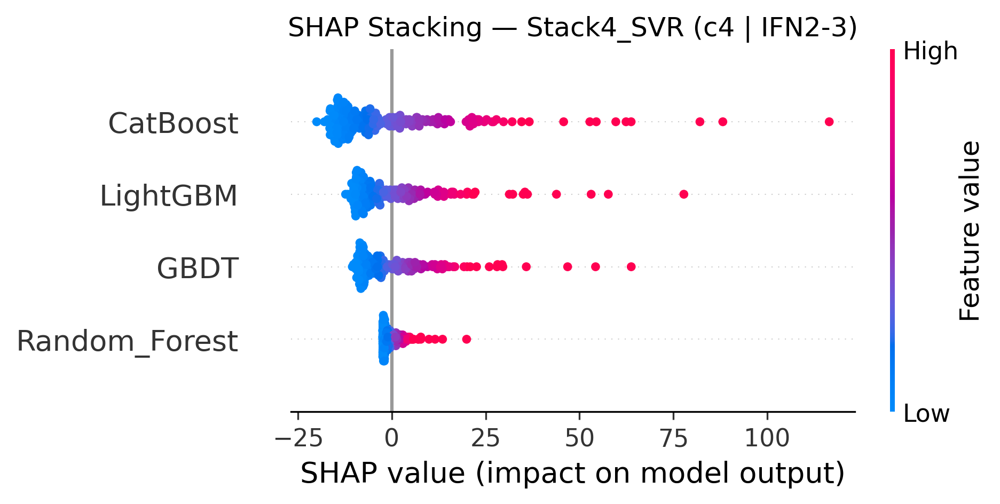


Stack5 (c4) — bases: ['CatBoost', 'LightGBM', 'XGBoost', 'Random_Forest', 'GBDT', 'BaggedDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack5_GradientBoosting


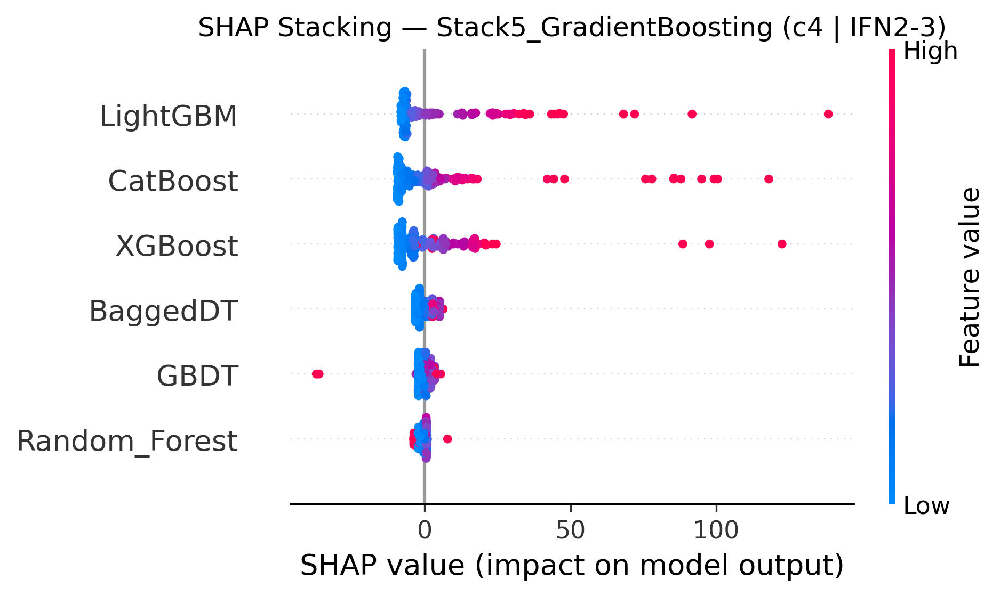

  [OK] Stack5_LinearRegression


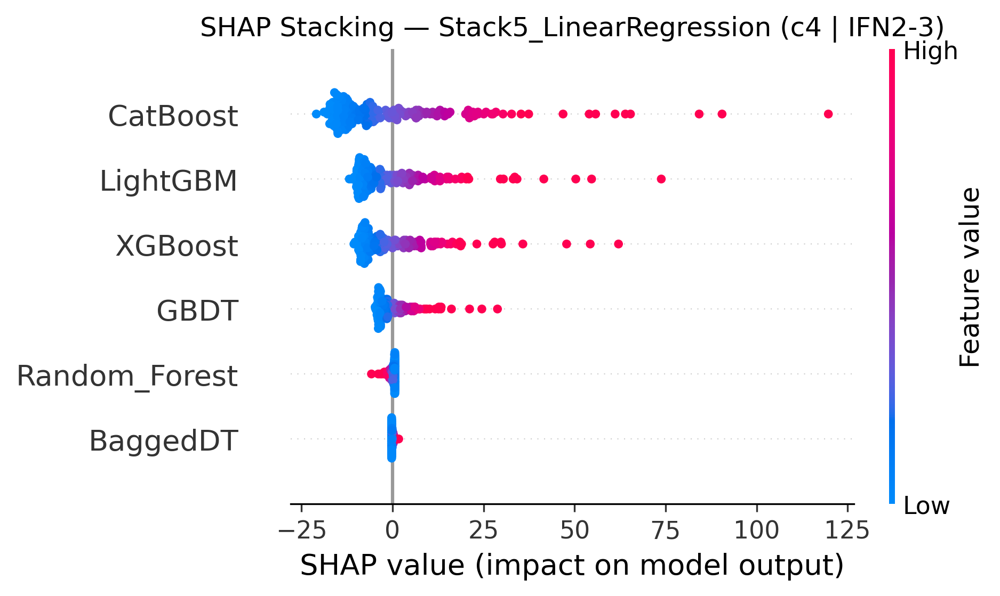

  [OK] Stack5_MLP


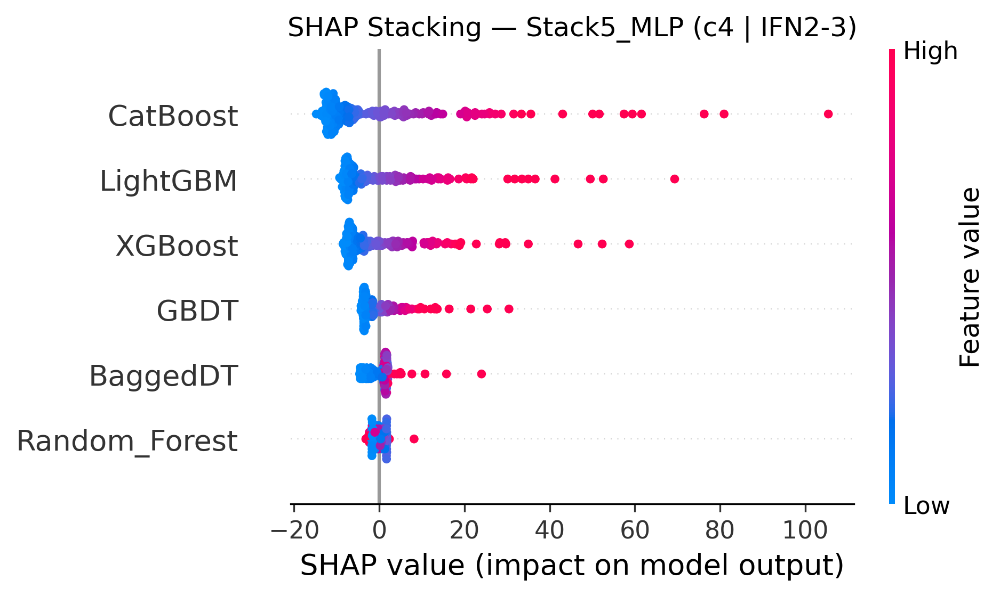

  [OK] Stack5_RandomForest


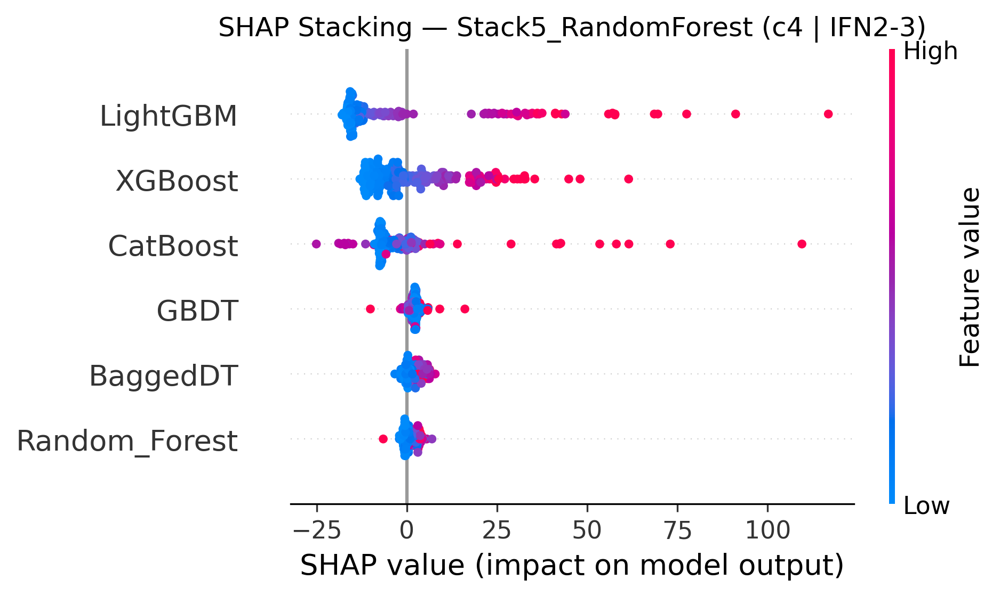

  [OK] Stack5_Ridge


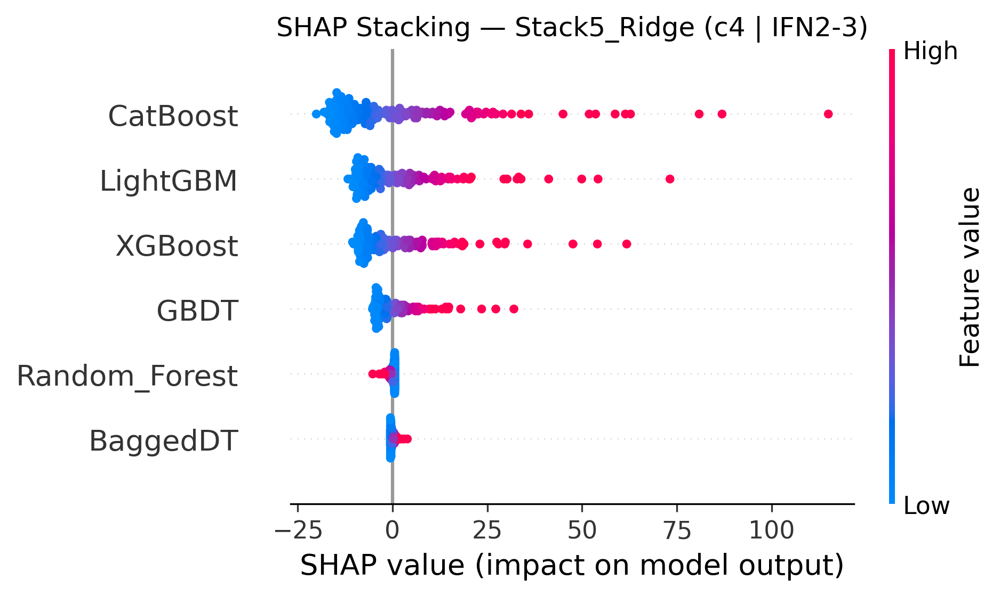

  [OK] Stack5_SVR


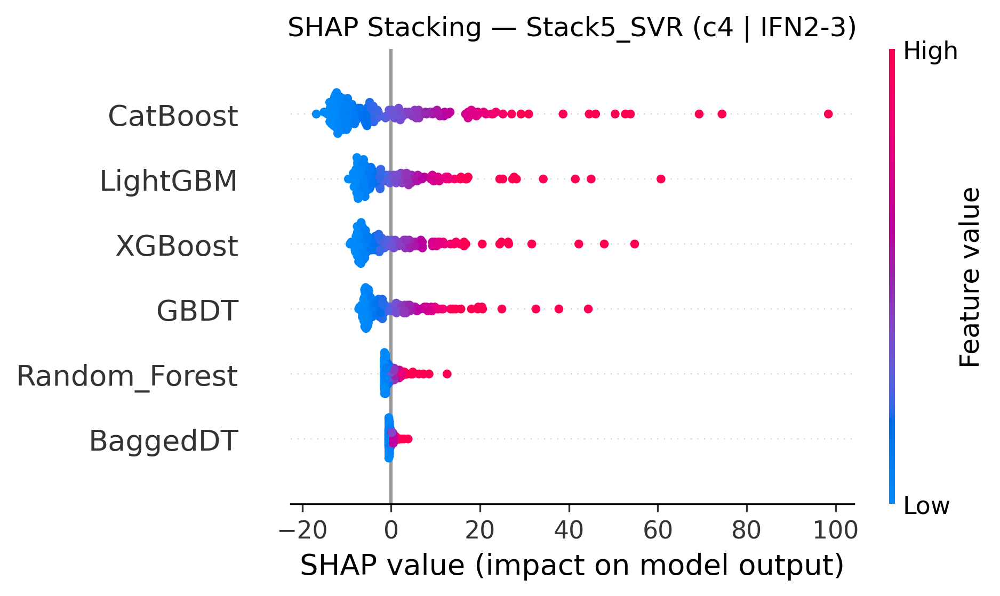


Sección 6 completada.


In [17]:
out_dir_stack_c4 = OUTPUT_SHAP / 'c4' / 'stacking_beeswarm'
out_dir_stack_c4.mkdir(parents=True, exist_ok=True)

for stack_name, base_names in STACK_CONFIGS.items():
    print(f'\n{"="*60}')
    print(f'{stack_name} (c4) — bases: {base_names}')
    print(f'{"="*60}')

    meta_files = sorted(MODELS_IFN23_C4_STACK.glob(f'{stack_name}_*.joblib'))
    if not meta_files:
        print(f'  Sin archivos para {stack_name}, omitiendo')
        continue

    save_paths = {mp.stem: out_dir_stack_c4 / f'beeswarm_{mp.stem}.png' for mp in meta_files}
    all_exist  = all(p.exists() and p.with_suffix('.pdf').exists() for p in save_paths.values())

    if all_exist:
        print(f'  Todos los plots existen — mostrando desde disco')
        for meta_name, save_path in save_paths.items():
            print(f'  [OK] {meta_name}')
            ipy_display(IPImage(str(save_path)))
        continue

    X_meta = make_meta_features(base_names, MODELS_IFN23_C4, X_sample_c4, FEATURES_C4)
    print(f'  Meta-features: {X_meta.shape}')

    for meta_path in meta_files:
        meta_name = meta_path.stem
        save_path = save_paths[meta_name]

        if save_path.exists() and save_path.with_suffix('.pdf').exists():
            print(f'  [OK] {meta_name}')
            ipy_display(IPImage(str(save_path)))
            continue

        print(f'  {meta_name}...', end=' ')
        meta_pipe = None
        try:
            meta_pipe = joblib.load(meta_path)
            shap_vals, X_scaled, base_val = compute_meta_shap(meta_pipe, X_meta)
            del meta_pipe; meta_pipe = None
            gc.collect()

            explanation = shap.Explanation(
                values=shap_vals, base_values=base_val,
                data=X_scaled.values, feature_names=list(X_meta.columns)
            )
            n_feats = len(base_names)
            fig, ax = plt.subplots(figsize=(9, max(4, n_feats + 2)))
            shap.plots.beeswarm(explanation, max_display=n_feats, show=False)
            plt.title(f'SHAP Stacking — {meta_name} (c4 | IFN2-3)', fontsize=12)
            plt.subplots_adjust(left=0.35, bottom=0.15)
            print(f'  -> {save_path}')
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
            plt.show()
            plt.close()
            print('OK')
        except Exception as e:
            print(f'ERROR: {e}')
        finally:
            if meta_pipe is not None:
                del meta_pipe
            gc.collect()

    del X_meta
    gc.collect()

print('\nSección 6 completada.')

---
## 7. SHAP Beeswarm — Modelos Stacking (carbono\_bruto4, IFN2-3)


Stack1 (carbono_bruto4) — bases: ['LightGBM', 'Random_Forest']
  Todos los plots existen — mostrando desde disco
  [OK] Stack1_GradientBoosting


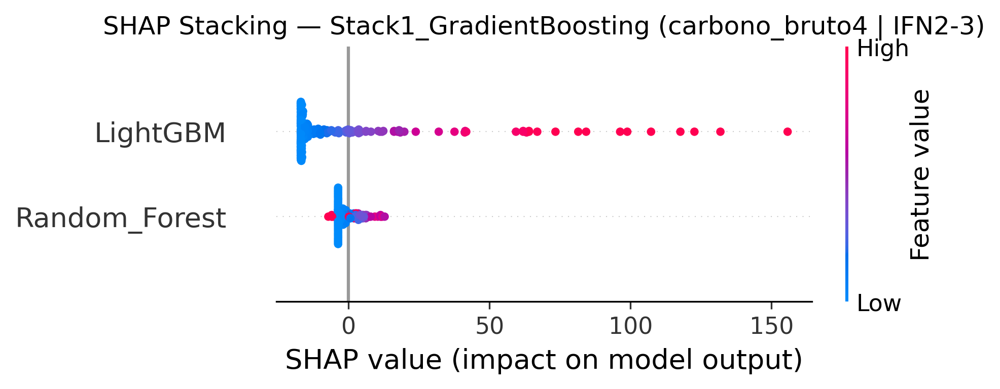

  [OK] Stack1_LinearRegression


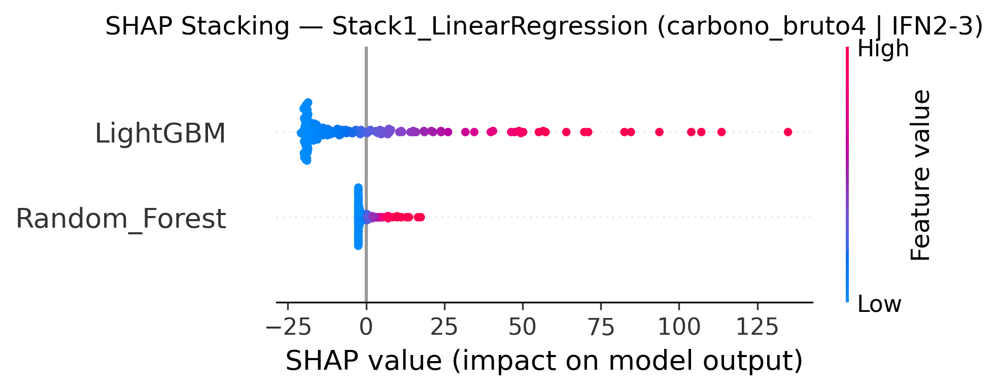

  [OK] Stack1_MLP


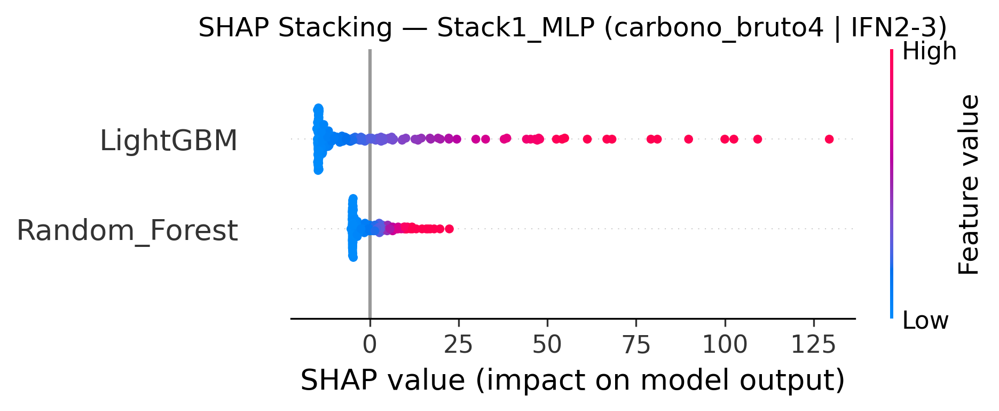

  [OK] Stack1_RandomForest


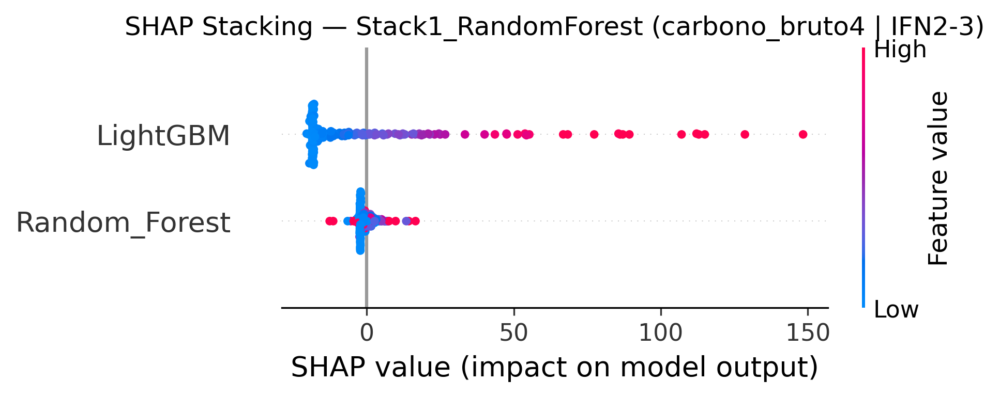

  [OK] Stack1_Ridge


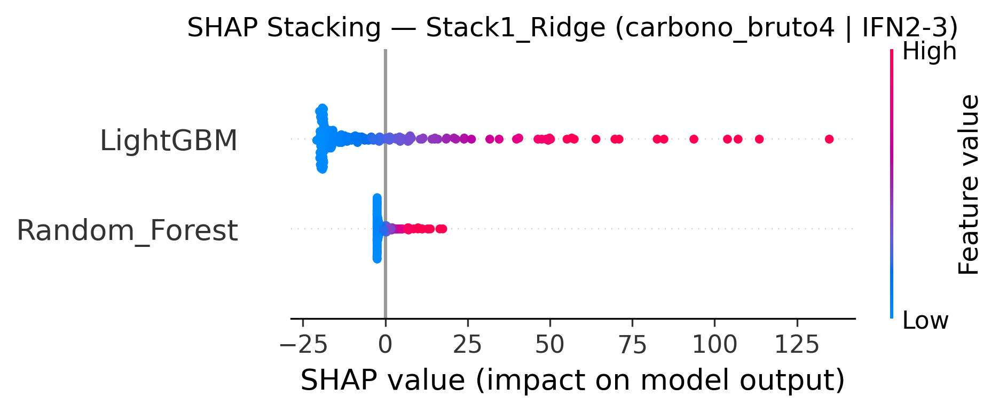

  [OK] Stack1_SVR


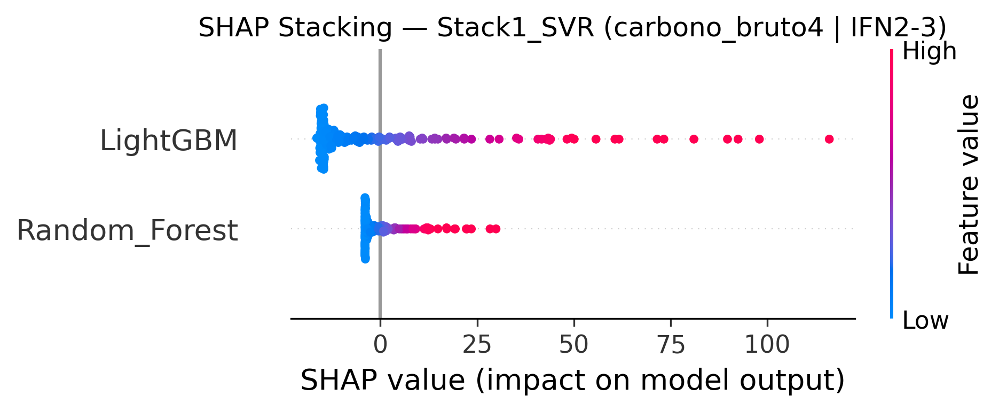


Stack2 (carbono_bruto4) — bases: ['LightGBM', 'XGBoost', 'GBDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack2_GradientBoosting


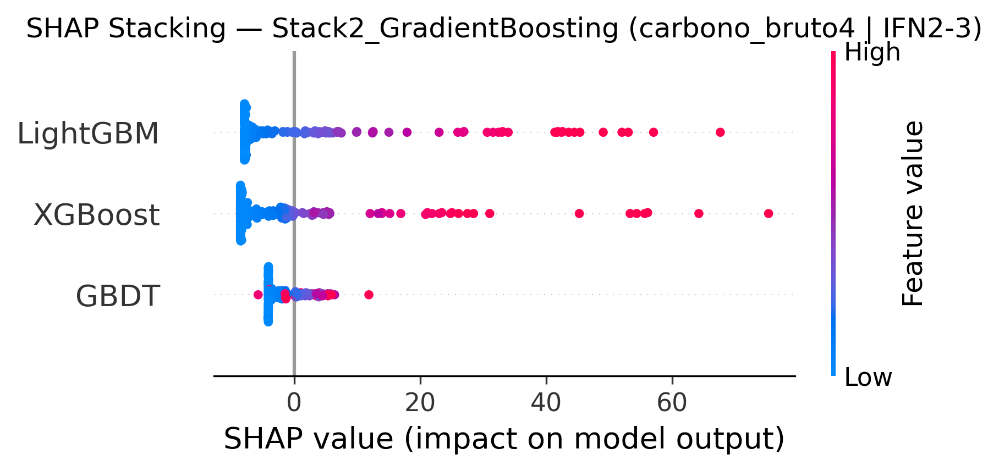

  [OK] Stack2_LinearRegression


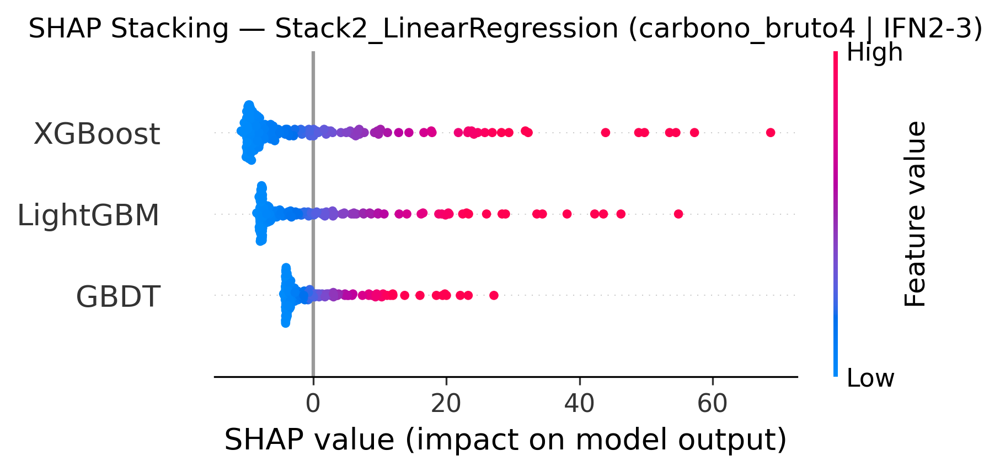

  [OK] Stack2_MLP


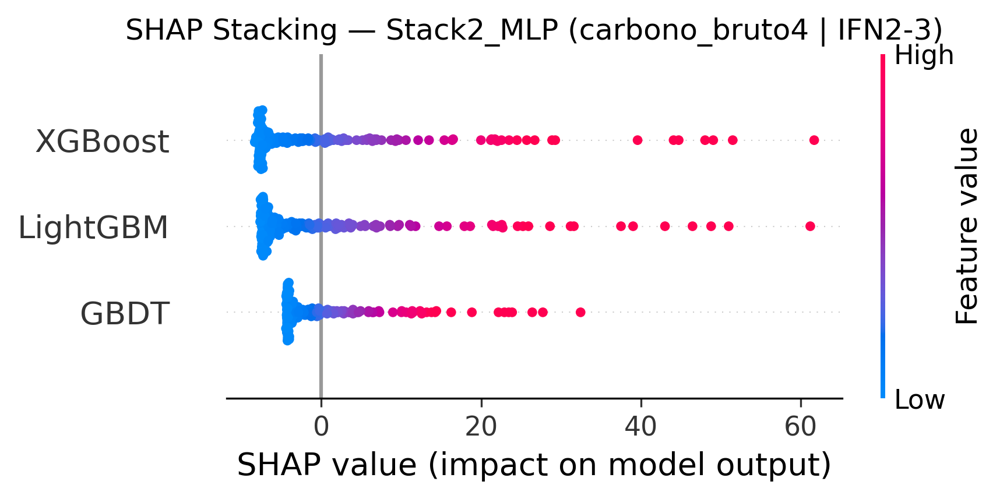

  [OK] Stack2_RandomForest


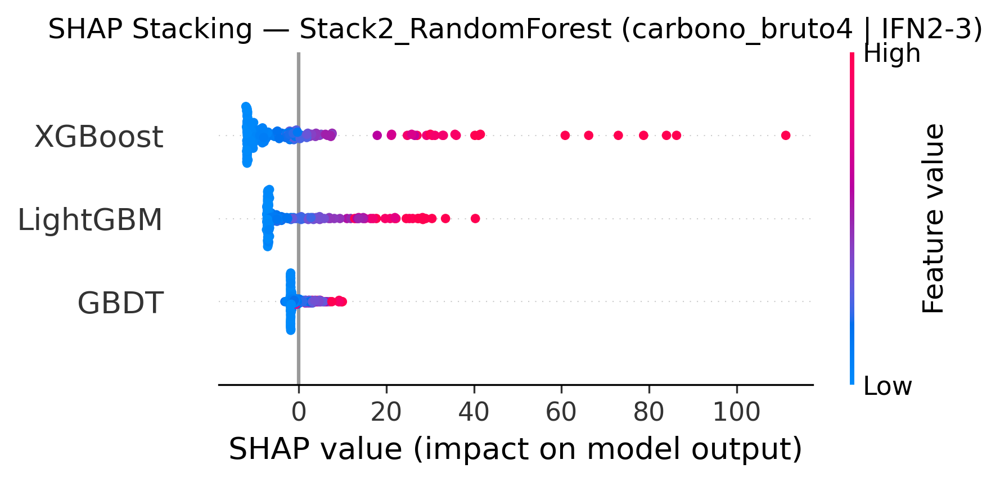

  [OK] Stack2_Ridge


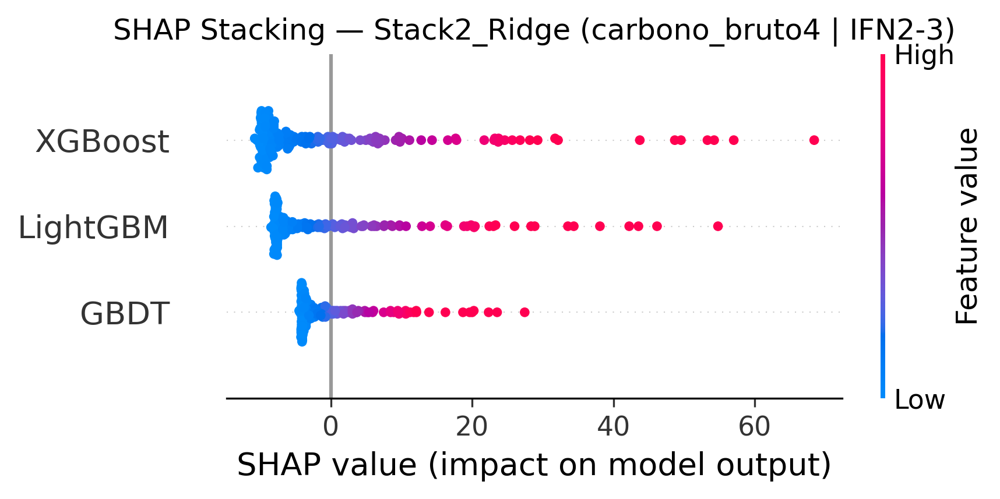

  [OK] Stack2_SVR


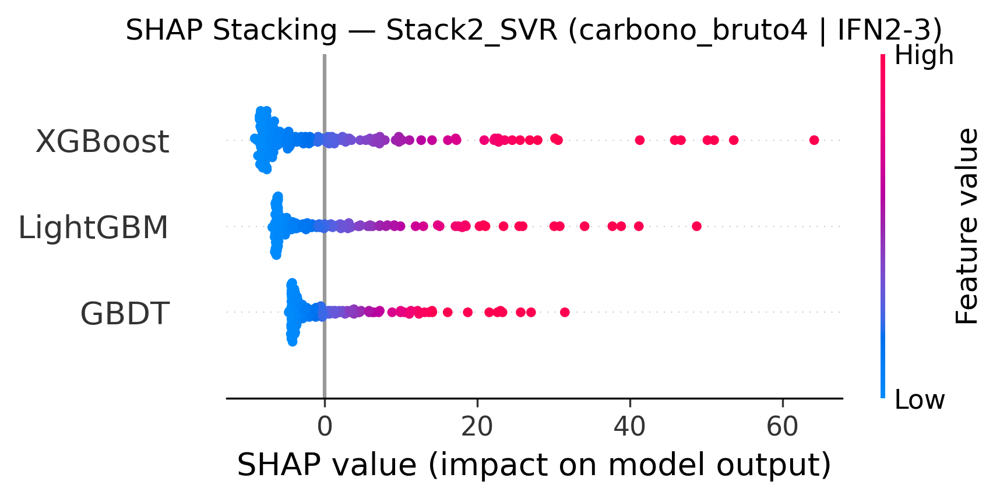


Stack3 (carbono_bruto4) — bases: ['CatBoost', 'Random_Forest', 'GBDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack3_GradientBoosting


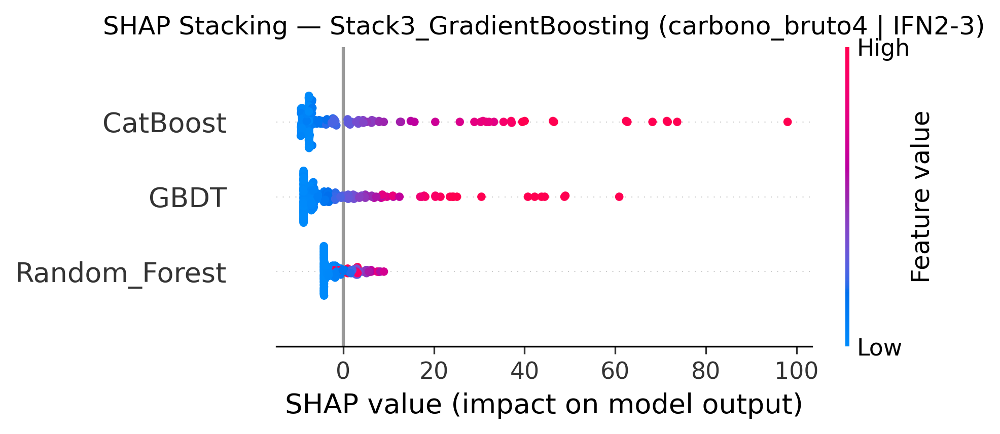

  [OK] Stack3_LinearRegression


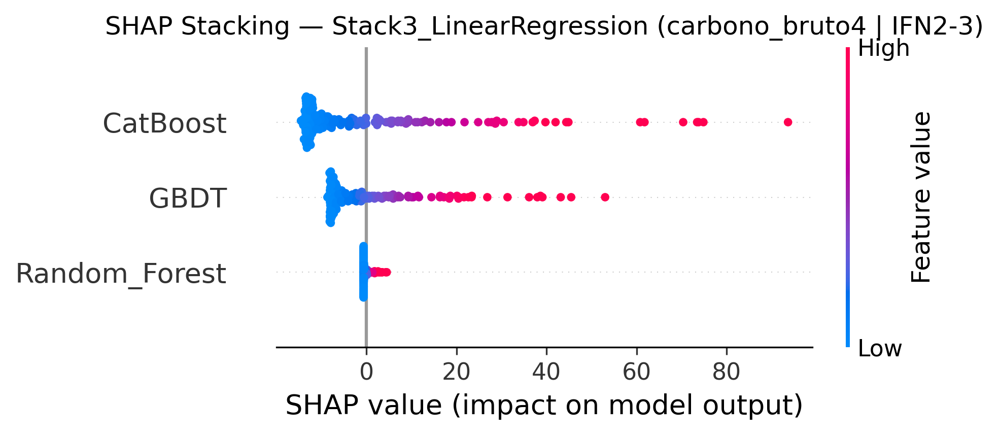

  [OK] Stack3_MLP


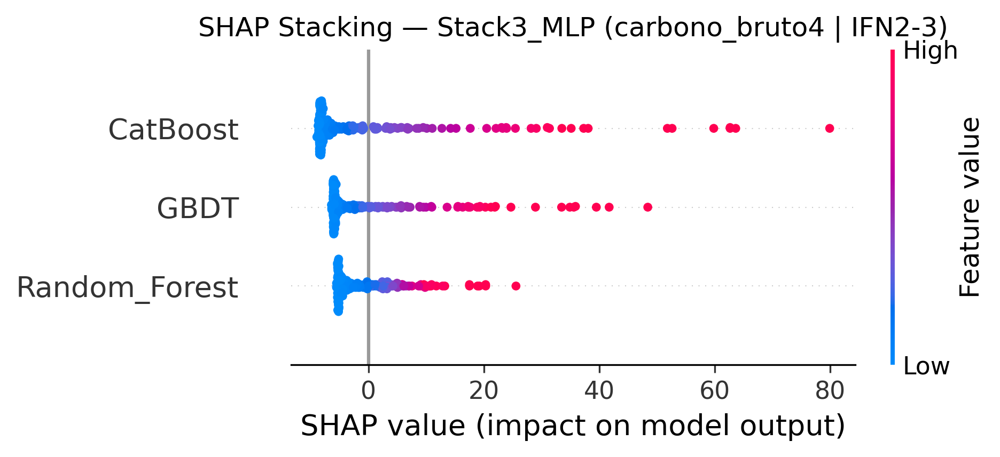

  [OK] Stack3_RandomForest


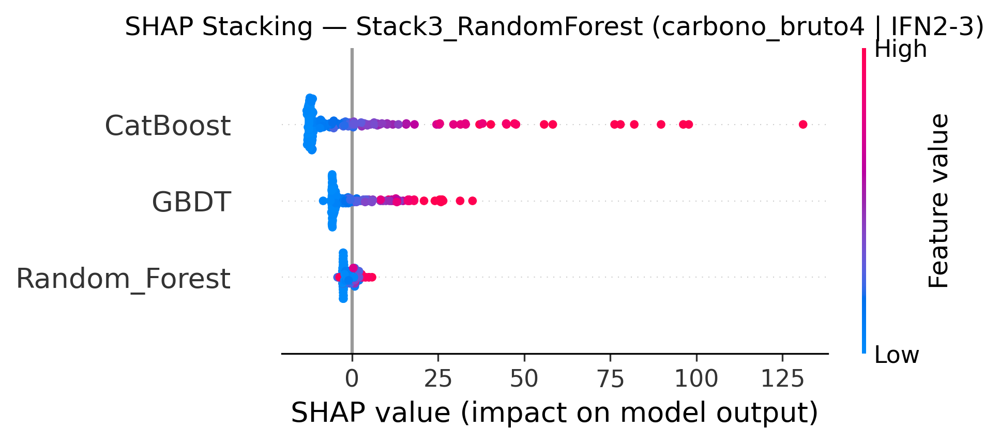

  [OK] Stack3_Ridge


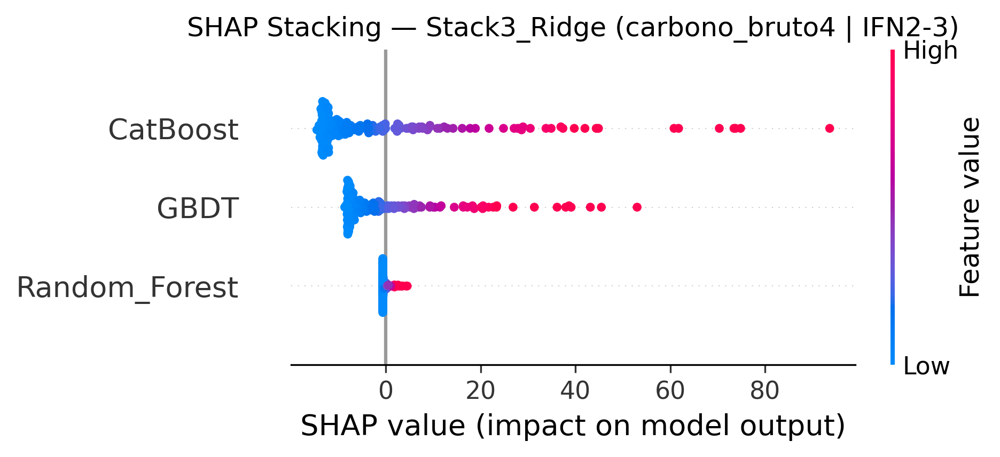

  [OK] Stack3_SVR


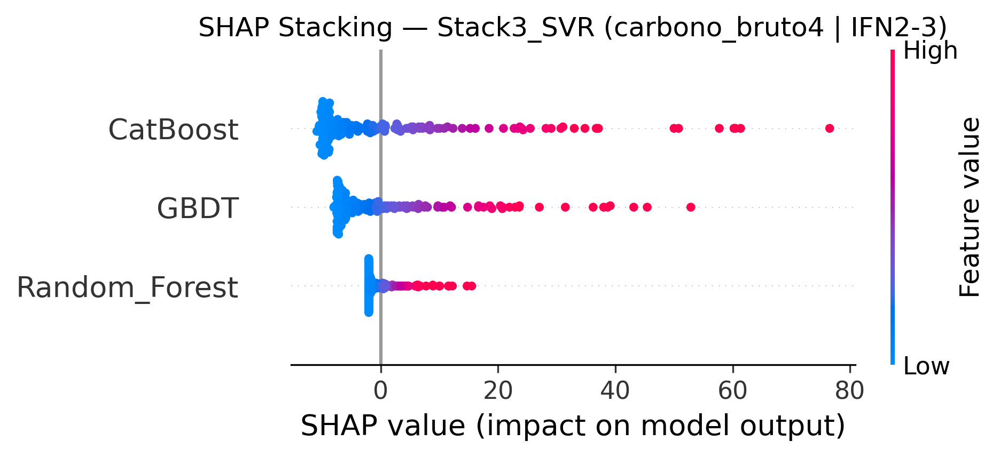


Stack4 (carbono_bruto4) — bases: ['CatBoost', 'LightGBM', 'Random_Forest', 'GBDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack4_GradientBoosting


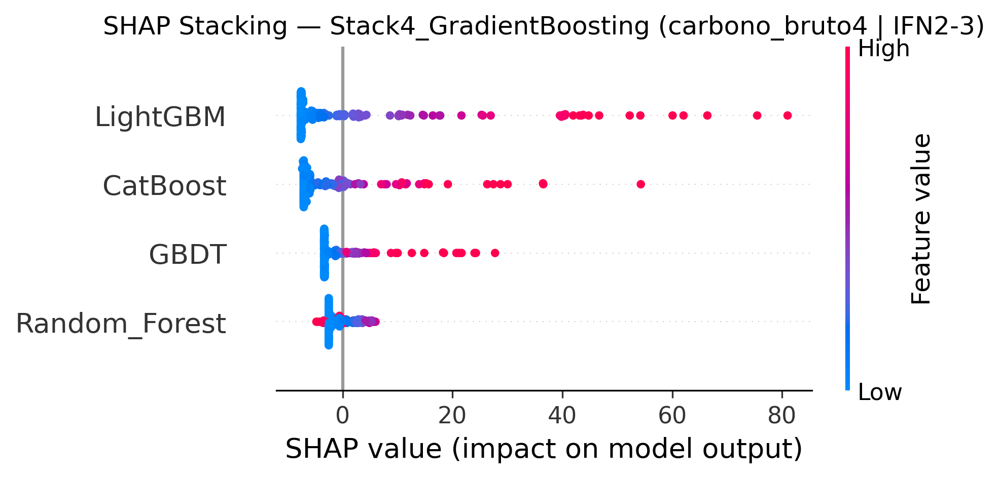

  [OK] Stack4_LinearRegression


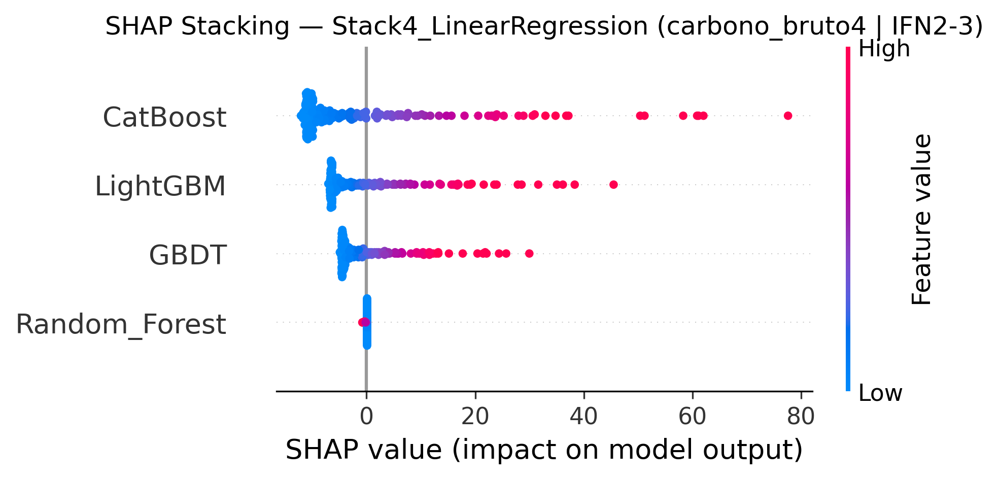

  [OK] Stack4_MLP


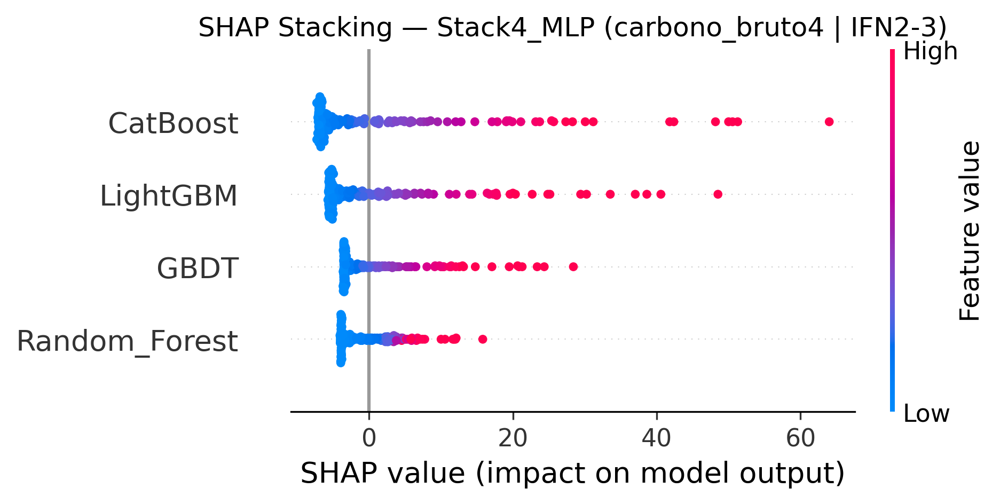

  [OK] Stack4_RandomForest


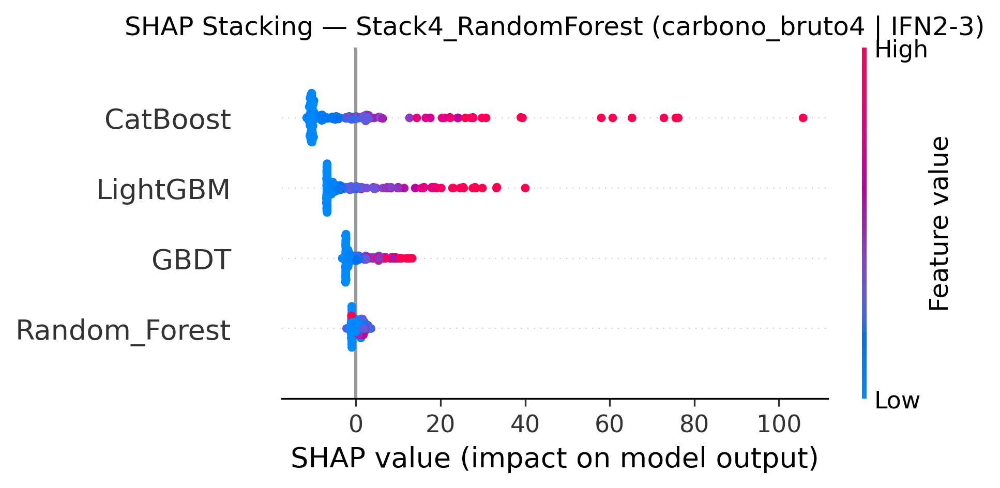

  [OK] Stack4_Ridge


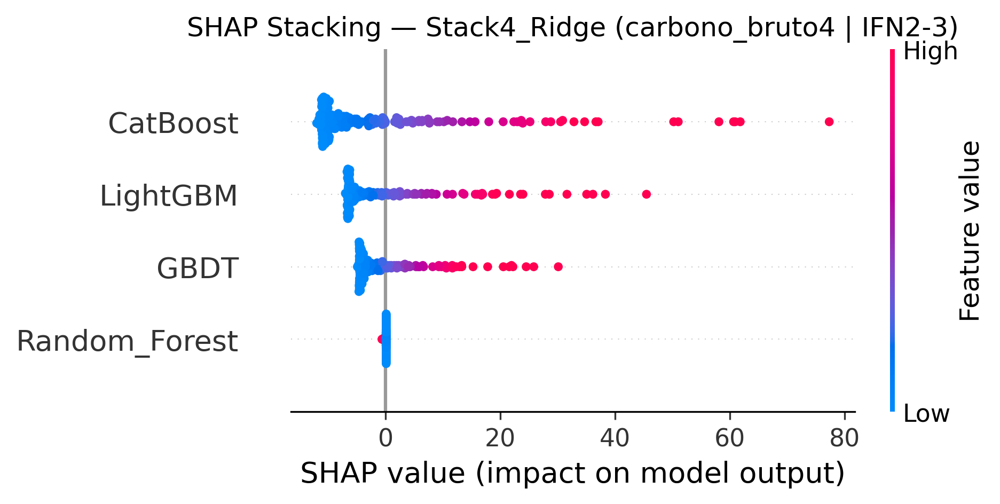

  [OK] Stack4_SVR


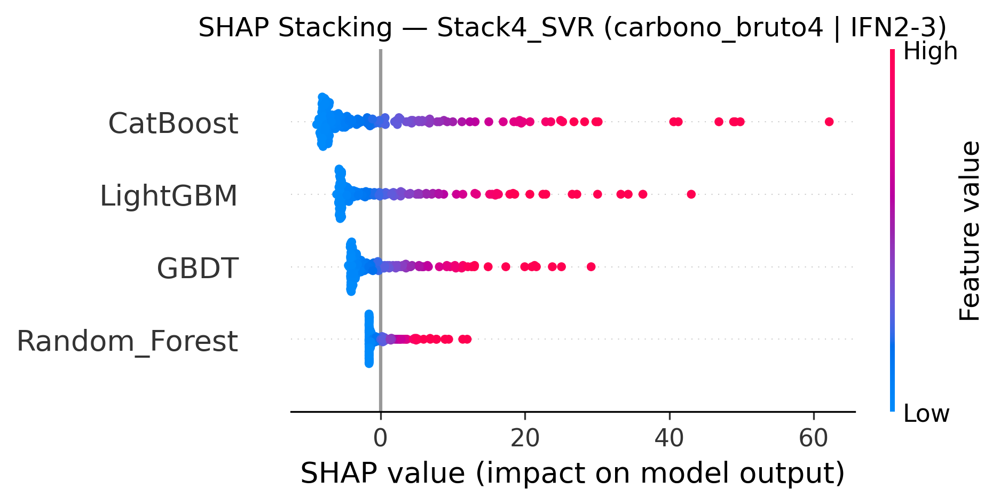


Stack5 (carbono_bruto4) — bases: ['CatBoost', 'LightGBM', 'XGBoost', 'Random_Forest', 'GBDT', 'BaggedDT']
  Todos los plots existen — mostrando desde disco
  [OK] Stack5_GradientBoosting


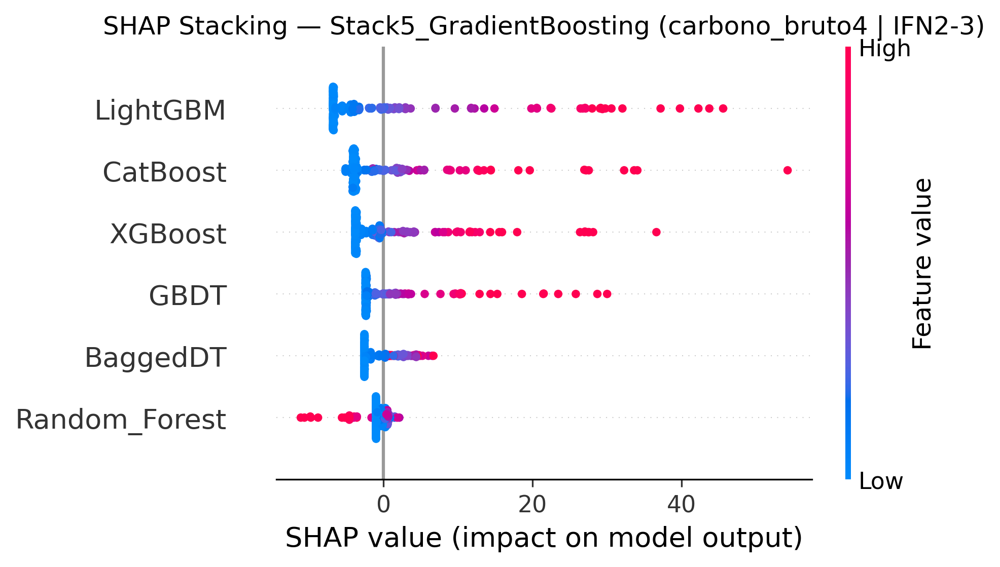

  [OK] Stack5_LinearRegression


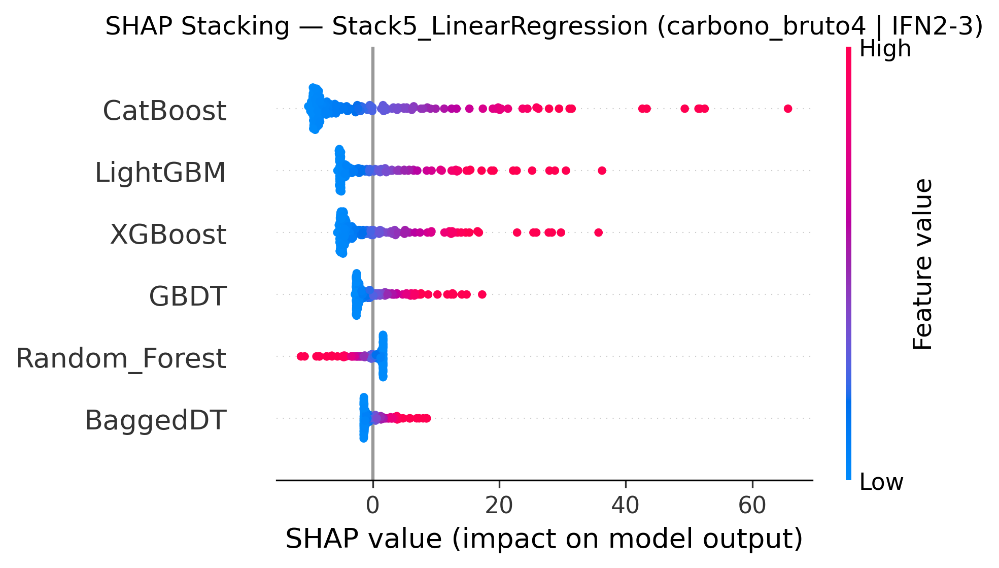

  [OK] Stack5_MLP


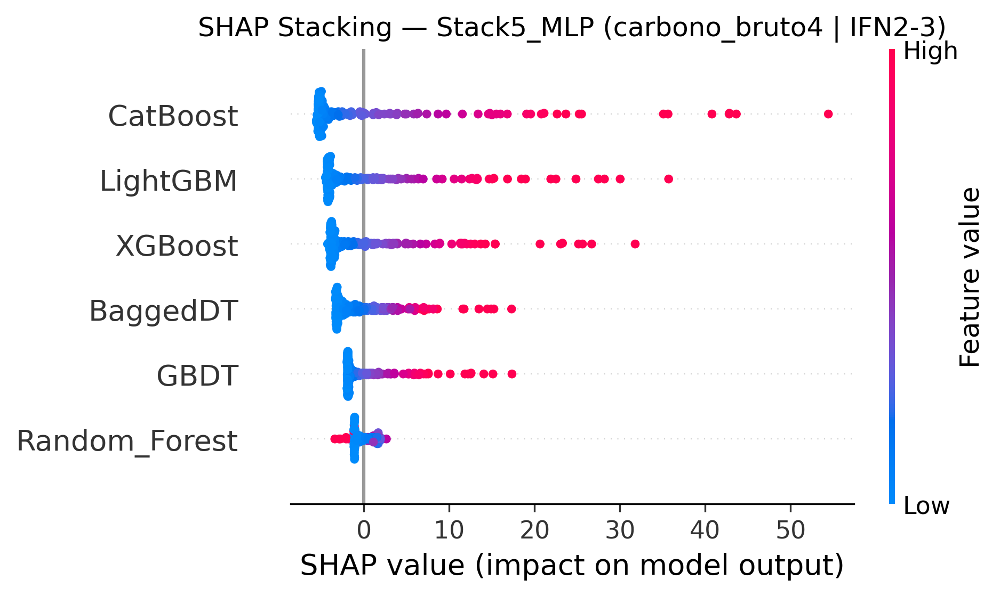

  [OK] Stack5_RandomForest


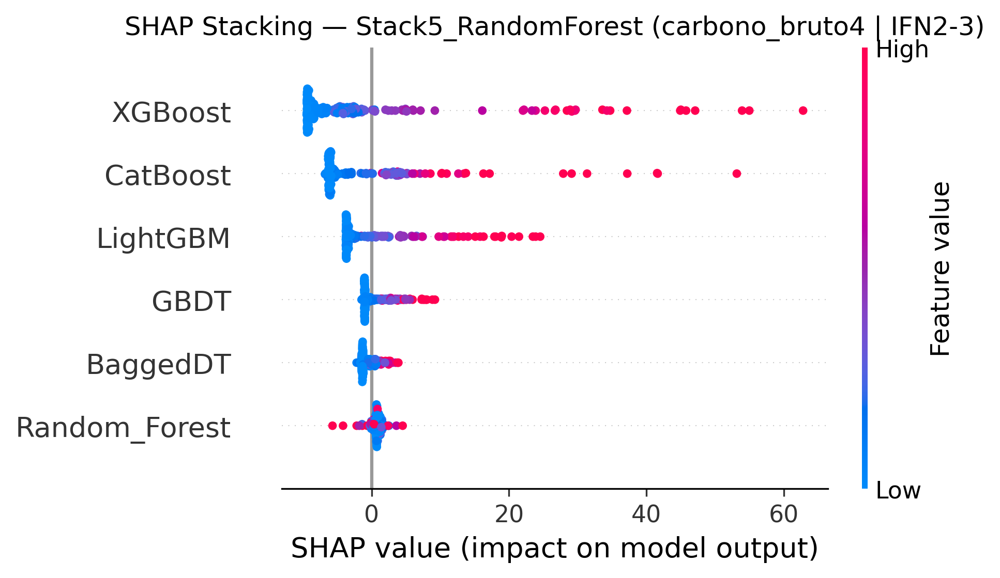

  [OK] Stack5_Ridge


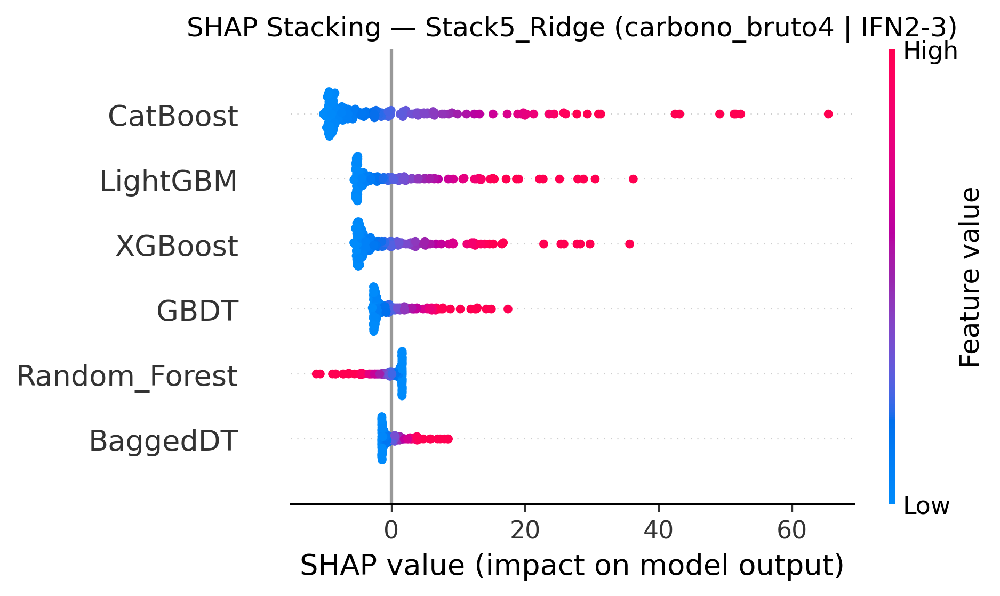

  [OK] Stack5_SVR


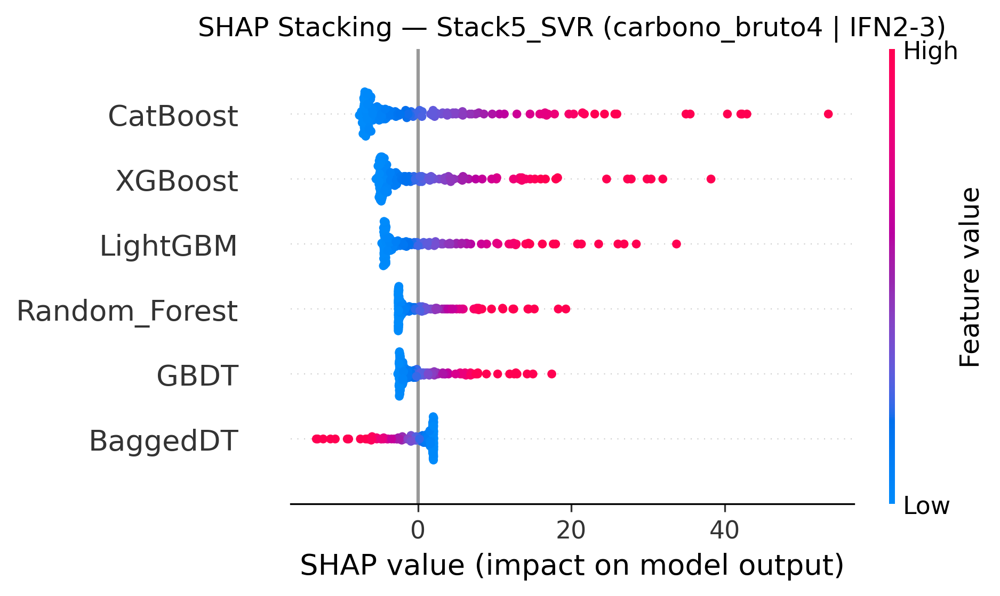


Sección 7 completada.


In [18]:
out_dir_stack_cb4 = OUTPUT_SHAP / 'carbono_bruto4' / 'stacking_beeswarm'
out_dir_stack_cb4.mkdir(parents=True, exist_ok=True)

for stack_name, base_names in STACK_CONFIGS.items():
    print(f'\n{"="*60}')
    print(f'{stack_name} (carbono_bruto4) — bases: {base_names}')
    print(f'{"="*60}')

    meta_files = sorted(MODELS_IFN23_CB4_STACK.glob(f'{stack_name}_*.joblib'))
    if not meta_files:
        print(f'  Sin archivos para {stack_name}, omitiendo')
        continue

    save_paths = {mp.stem: out_dir_stack_cb4 / f'beeswarm_{mp.stem}.png' for mp in meta_files}
    all_exist  = all(p.exists() and p.with_suffix('.pdf').exists() for p in save_paths.values())

    if all_exist:
        print(f'  Todos los plots existen — mostrando desde disco')
        for meta_name, save_path in save_paths.items():
            print(f'  [OK] {meta_name}')
            ipy_display(IPImage(str(save_path)))
        continue

    X_meta = make_meta_features(base_names, MODELS_IFN23_CB4, X_sample_cb4, FEATURES_CB4)
    print(f'  Meta-features: {X_meta.shape}')

    for meta_path in meta_files:
        meta_name = meta_path.stem
        save_path = save_paths[meta_name]

        if save_path.exists() and save_path.with_suffix('.pdf').exists():
            print(f'  [OK] {meta_name}')
            ipy_display(IPImage(str(save_path)))
            continue

        print(f'  {meta_name}...', end=' ')
        meta_pipe = None
        try:
            meta_pipe = joblib.load(meta_path)
            shap_vals, X_scaled, base_val = compute_meta_shap(meta_pipe, X_meta)
            del meta_pipe; meta_pipe = None
            gc.collect()

            explanation = shap.Explanation(
                values=shap_vals, base_values=base_val,
                data=X_scaled.values, feature_names=list(X_meta.columns)
            )
            n_feats = len(base_names)
            fig, ax = plt.subplots(figsize=(9, max(4, n_feats + 2)))
            shap.plots.beeswarm(explanation, max_display=n_feats, show=False)
            plt.title(f'SHAP Stacking — {meta_name} (carbono_bruto4 | IFN2-3)', fontsize=12)
            plt.subplots_adjust(left=0.35, bottom=0.15)
            print(f'  -> {save_path}')
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
            plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
            plt.show()
            plt.close()
            print('OK')
        except Exception as e:
            print(f'ERROR: {e}')
        finally:
            if meta_pipe is not None:
                del meta_pipe
            gc.collect()

    del X_meta
    gc.collect()

print('\nSección 7 completada.')

---
## 8. Summary Plots (3 paneles)

Para cada modelo base IFN2-3 (× 2 targets):
- **Summary plot 3 paneles**: bar de importancia + violin con gradiente + beeswarm


In [19]:
# Colormap SHAP por defecto (azul=Low, rojo=High)
try:
    import shap as _shap_mod
    CMAP_FEAT = _shap_mod.plots.colors.red_blue
except Exception:
    CMAP_FEAT = mpl.colors.LinearSegmentedColormap.from_list(
        'shap_feat', ['#3288bd', '#ffffbf', '#d53e4f'], N=256
    )

COLOR_BAR    = '#1a7e5c'
COLOR_VIOLIN = '#2fa56a'


def _draw_violin_gradient(ax, x_r, d_n, y_center, cmap, grad=None):
    """Fills a violin shape with a horizontal colormap gradient via imshow + clip."""
    from matplotlib.patches import PathPatch
    from matplotlib.path import Path as MplPath

    top   = np.column_stack([x_r,        y_center + d_n])
    bot   = np.column_stack([x_r[::-1],  y_center - d_n[::-1]])
    verts = np.vstack([top, bot, top[:1]])
    codes = ([MplPath.MOVETO]
             + [MplPath.LINETO] * (len(verts) - 2)
             + [MplPath.CLOSEPOLY])
    path  = MplPath(verts, codes)
    patch = PathPatch(path, transform=ax.transData, facecolor='none', edgecolor='none')
    ax.add_patch(patch)

    if grad is None:
        grad = np.linspace(0, 1, len(x_r)).reshape(1, -1)
    lo, hi = x_r[0], x_r[-1]
    im = ax.imshow(
        grad, aspect='auto', cmap=cmap,
        extent=[lo, hi, y_center - 0.43, y_center + 0.43],
        origin='lower', zorder=2, alpha=0.85
    )
    im.set_clip_path(patch)


def _compute_gradient(shap_vals, feat_vals, x_r):
    """Color del violín en cada posición X = promedio normalizado del valor de
    feature de las muestras que caen en ese bin SHAP. Igual que la librería SHAP."""
    f_min, f_max = feat_vals.min(), feat_vals.max()
    if f_max - f_min < 1e-10:
        return np.full((1, len(x_r)), 0.5)
    feat_norm = (feat_vals - f_min) / (f_max - f_min)
    n = len(x_r)
    lo, hi = x_r[0], x_r[-1]
    span = hi - lo + 1e-12
    # Asignar cada muestra al bin más cercano del eje x_r
    idx = np.clip(np.round((shap_vals - lo) / span * (n - 1)).astype(int), 0, n - 1)
    bin_colors  = np.zeros(n)
    bin_weights = np.zeros(n)
    np.add.at(bin_colors,  idx, feat_norm)
    np.add.at(bin_weights, idx, 1.0)
    valid = bin_weights > 0
    if valid.sum() == 0:
        return np.linspace(0, 1, n).reshape(1, -1)
    bin_colors[valid] /= bin_weights[valid]
    # Interpolar bins vacíos con vecino más cercano
    if valid.sum() < n:
        xp = np.where(valid)[0].astype(float)
        fp = bin_colors[valid]
        for j in np.where(~valid)[0]:
            nearest = xp[np.argmin(np.abs(xp - j))]
            bin_colors[j] = fp[int(np.where(xp == nearest)[0][0])]
    return bin_colors.reshape(1, -1)


def _draw_section(fig, gs_row, names_s, sv_s, dv_s, imp_s, rng, show_xlabel, unit='', var_colors=None):
    """Draw one section (bar + violin + beeswarm) into a GridSpec row."""
    n_s = len(names_s)
    y_s = np.arange(n_s)

    ax1 = fig.add_subplot(gs_row[0])
    ax2 = fig.add_subplot(gs_row[1])
    ax3 = fig.add_subplot(gs_row[2])

    # Bar
    ax1.barh(y_s, imp_s, color=COLOR_BAR, height=0.55, zorder=2)
    ax1.set_yticks(y_s)
    ax1.set_yticklabels(names_s, fontsize=8.5, fontweight='bold')
    if var_colors is not None:
        for tick, col in zip(ax1.get_yticklabels(), var_colors):
            tick.set_color(col)
    ax1.tick_params(axis='x', labelsize=7.5)
    ax1.spines[['top', 'right']].set_visible(False)
    ax1.axvline(0, color='black', linewidth=0.6)
    ax1.grid(axis='x', alpha=0.25, zorder=0)
    ax1.set_ylim(-0.5, n_s - 0.5)
    if show_xlabel:
        ax1.set_xlabel(
            f'mean(|SHAP value|) ({unit})\n(average impact on\nmagnitude of model output)',
            fontsize=8
        )

    # Violin con gradiente de colormap
    for i in range(n_s):
        vals = sv_s[:, i]
        if np.std(vals) < 1e-8:
            ax2.scatter([vals[0]], [y_s[i]], color=COLOR_VIOLIN, s=12, zorder=3)
            continue
        try:
            kde = gaussian_kde(vals, bw_method=0.4)
            lo  = vals.min() - 0.01 * abs(vals.max() - vals.min())
            hi  = vals.max() + 0.01 * abs(vals.max() - vals.min())
            x_r = np.linspace(lo, hi, 200)
            den = kde(x_r)
            d_n = den / den.max() * 0.42
            feat_vals_i = dv_s[:, i]
            grad_i = _compute_gradient(vals, feat_vals_i, x_r)
            _draw_violin_gradient(ax2, x_r, d_n, y_s[i], CMAP_FEAT, grad=grad_i)
            ax2.plot(x_r, y_s[i] - d_n, color='white', linewidth=0.3, alpha=0.4)
            ax2.plot(x_r, y_s[i] + d_n, color='white', linewidth=0.3, alpha=0.4)
        except Exception:
            pass
    ax2.axvline(0, color='black', linewidth=0.7, zorder=4)
    ax2.set_yticks(y_s)
    ax2.set_yticklabels([])
    ax2.tick_params(axis='x', labelsize=7)
    ax2.spines[['top', 'right']].set_visible(False)
    ax2.grid(axis='x', alpha=0.2, zorder=0)
    ax2.set_ylim(-0.5, n_s - 0.5)
    if show_xlabel:
        ax2.set_xlabel(f'SHAP value ({unit})\n(impact on model output)', fontsize=8)

    # Beeswarm
    for i in range(n_s):
        vals      = sv_s[:, i]
        feat_vals = dv_s[:, i]
        f_min, f_max = feat_vals.min(), feat_vals.max()
        feat_norm = (feat_vals - f_min) / (f_max - f_min + 1e-12)
        jitter_y  = np.clip(rng.standard_normal(len(vals)) * 0.17, -0.38, 0.38)
        ax3.scatter(vals, y_s[i] + jitter_y, c=feat_norm, cmap=CMAP_FEAT,
                    s=6, alpha=0.65, linewidths=0, zorder=3)
    ax3.axvline(0, color='black', linewidth=0.7, zorder=2)
    ax3.set_yticks(y_s)
    ax3.set_yticklabels([])
    ax3.tick_params(axis='x', labelsize=7)
    ax3.spines[['top', 'right']].set_visible(False)
    ax3.grid(axis='x', alpha=0.2, zorder=0)
    ax3.set_ylim(-0.5, n_s - 0.5)
    if show_xlabel:
        ax3.set_xlabel(f'SHAP value ({unit})\n(impact on model output)', fontsize=8)

    return ax1, ax2, ax3


def plot_3panel_summary(shap_g, data_g, names_g, title, save_path, top_n=12, n_top_split=2, unit='', var_colors=None):
    """
    3-panel SHAP summary con dos secciones:
      - Superior: top n_top_split caracteristicas (escala X propia)
      - Inferior: caracteristicas restantes (escala X propia)
    Violin coloreado con gradiente. Colorbar incrustada en beeswarm inferior.
    """
    from matplotlib.gridspec import GridSpec, GridSpecFromSubplotSpec

    shap_clean = np.nan_to_num(shap_g, nan=0.0, posinf=0.0, neginf=0.0)
    data_clean = np.nan_to_num(data_g, nan=0.0, posinf=0.0, neginf=0.0)

    importances = np.mean(np.abs(shap_clean), axis=0)
    n_avail    = len(importances)
    actual_top = min(top_n, n_avail)
    top_idx    = np.argsort(importances)[::-1][:actual_top][::-1]
    names  = [names_g[i] for i in top_idx]
    sv     = shap_clean[:, top_idx]
    dv     = data_clean[:, top_idx]
    imp    = importances[top_idx]
    colors = [var_colors[i] for i in top_idx] if var_colors is not None else None
    n_feat = actual_top

    n_top  = min(n_top_split, n_feat)
    n_rest = n_feat - n_top

    # Seccion superior: los n_top mas importantes (indices finales)
    names_top  = names[n_rest:]
    sv_top     = sv[:, n_rest:]
    dv_top     = dv[:, n_rest:]
    imp_top    = imp[n_rest:]
    colors_top = colors[n_rest:] if colors is not None else None

    # Seccion inferior: los n_rest restantes
    names_rest  = names[:n_rest]
    sv_rest     = sv[:, :n_rest]
    dv_rest     = dv[:, :n_rest]
    imp_rest    = imp[:n_rest]
    colors_rest = colors[:n_rest] if colors is not None else None

    h_top  = max(0.9, n_top  * 0.40 + 0.25)
    h_rest = max(2.2, n_rest * 0.29 + 0.35)

    fig = plt.figure(figsize=(5.5, h_top + h_rest + 0.3))

    gs = GridSpec(2, 1, figure=fig,
                  height_ratios=[h_top, h_rest],
                  hspace=0.35)

    col_ratios = [1, 1.4, 1.4]
    gs_top = GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[0],
                                     width_ratios=col_ratios, wspace=0.08)
    gs_bot = GridSpecFromSubplotSpec(1, 3, subplot_spec=gs[1],
                                     width_ratios=col_ratios, wspace=0.08)

    rng = np.random.default_rng(42)

    _draw_section(fig, gs_top, names_top, sv_top, dv_top, imp_top, rng, show_xlabel=False, unit=unit, var_colors=colors_top)
    _, _, ax3_bot = _draw_section(fig, gs_bot, names_rest, sv_rest, dv_rest, imp_rest, rng,
                                   show_xlabel=True, unit=unit, var_colors=colors_rest)

    # Colorbar incrustada en beeswarm inferior, abajo a la derecha
    # Usamos ax.inset_axes (coordenadas en axes-space) en lugar de
    # mpl_toolkits inset_axes para evitar desplazamiento en PDF.
    sm = mpl.cm.ScalarMappable(cmap=CMAP_FEAT, norm=Normalize(0, 1))
    sm.set_array([])
    axins = ax3_bot.inset_axes([0.93, 0.03, 0.04, 0.33])
    cbar = fig.colorbar(sm, cax=axins)
    cbar.set_ticks([0.02, 0.98])
    cbar.set_ticklabels(['Low', 'High'], fontsize=7.5)
    cbar.outline.set_visible(False)
    axins.yaxis.set_ticks_position('left')
    axins.yaxis.set_label_position('left')

    # Leyenda de tipos de variables
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor=COLOR_VAR_NPIES,   label='npies*: normalized sum by diameter class'),
        Patch(facecolor=COLOR_VAR_ORDINAL, label='Ordinal cat.*: color = real variable value'),
        Patch(facecolor=COLOR_VAR_NOMINAL, label='Nominal cat.*: color = dataset mean carbon'),
        Patch(facecolor=COLOR_VAR_CONT,    label='Continuous: color = normalized real value'),
    ]
    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.subplots_adjust(bottom=0.24)
    fig.legend(handles=legend_elements, loc='lower center',
               prop={'size': 6.5, 'weight': 'bold'},
               ncol=2, framealpha=0.95, edgecolor='#aaaaaa',
               bbox_to_anchor=(0.5, 0.04), borderpad=0.8)
    save_path = Path(save_path)
    save_path.parent.mkdir(parents=True, exist_ok=True)
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.savefig(save_path.with_suffix('.pdf'), bbox_inches='tight')
    plt.show()
    plt.close()
    print(f'  -> {save_path}')



print('Funciones de plot OK')


SyntaxError: expected 'except' or 'finally' block (4043523663.py, line 108)

In [ ]:
# Carga de datos IFN2-3 para summary plots
df_raw = pd.read_csv(DATA_PATH)
df_raw['pendiente_cat']   = df_raw['pendiente_cat'].map(MAPA_PENDIENTE)
df_raw['orientacion_cat'] = df_raw['orientacion_cat'].map(MAPA_ORIENTACION)
print(f'Registros IFN2+3: {len(df_raw)}')

def get_ifn2_3_sample(target, features, n_sample=200, n_bg=50):
    df = df_raw[(df_raw[target].notna()) & (df_raw[target] != 0)].copy()
    if 'c' in df.columns:
        df = df[(df['c'].isna()) | (df['c'] < df[target])].copy()
    df = df[~(df['fccarb'].notna() & (df['fccarb'] < 20))].copy()
    tm = {col: df.groupby(col)[target].mean().to_dict()
          for col in VARS_CATEGORICAS if col in df.columns}
    present = [c for c in features if c in df.columns]
    X = df[present].copy().astype('float32')
    y = df[target].copy().astype('float32')
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    _, te_idx = next(gss.split(X, y, groups=df['parcela_id']))
    X_test   = X.iloc[te_idx].copy()
    X_sample = X_test.sample(min(n_sample, len(X_test)), random_state=42)
    X_bg     = X_test.sample(min(n_bg, len(X_test)), random_state=42)
    print(f'  {target}: {len(X_sample)} muestras SHAP  |  bg={len(X_bg)}')
    return X_sample, X_bg, tm

samples = {}
for tgt, cfg_s in CONFIGS_SF.items():
    X_s, X_bg, tm = get_ifn2_3_sample(tgt, cfg_s['features'])
    samples[tgt] = {'X_sample': X_s, 'X_bg': X_bg, 'tm': tm}

print('Datos listos.')


Registros IFN2+3: 259853
  c4: 200 muestras SHAP  |  bg=50
  carbono_bruto4: 200 muestras SHAP  |  bg=50
Datos listos.



SUMMARY PLOTS — IFN2-3 / c4  (9 modelos)
  BaggedDT... [caché] 

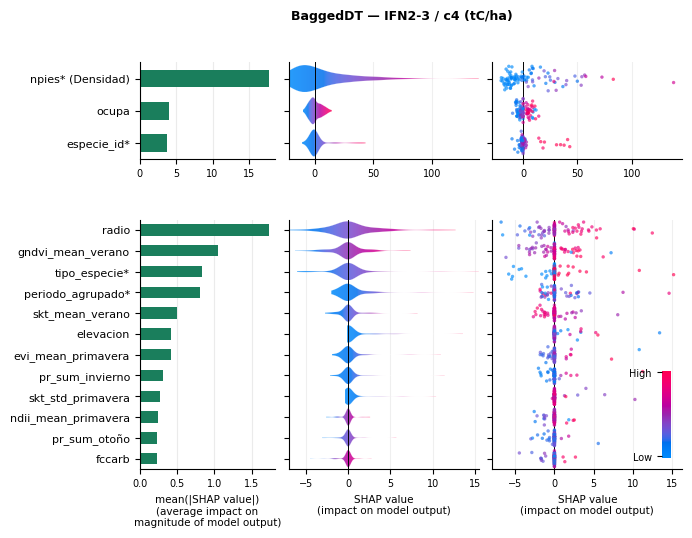

  -> ../../figures/shap_summary_ifn2_3/IFN3/c4/summary_BaggedDT.png
  BayesianNN... [caché] 

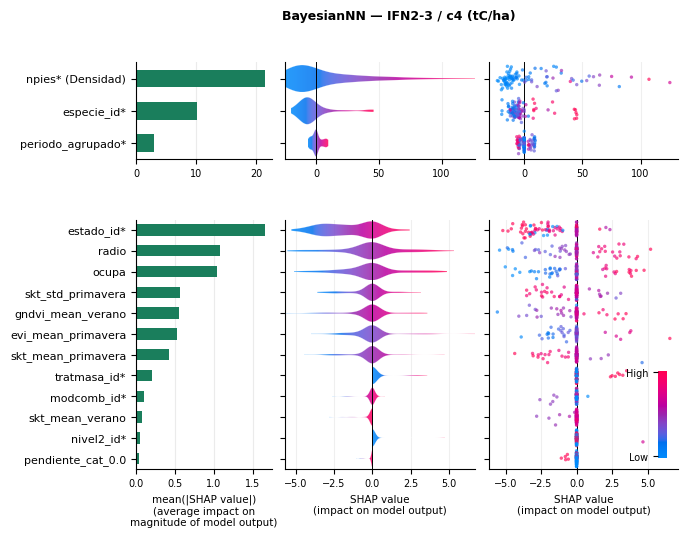

  -> ../../figures/shap_summary_ifn2_3/IFN3/c4/summary_BayesianNN.png
  CatBoost... [caché] 

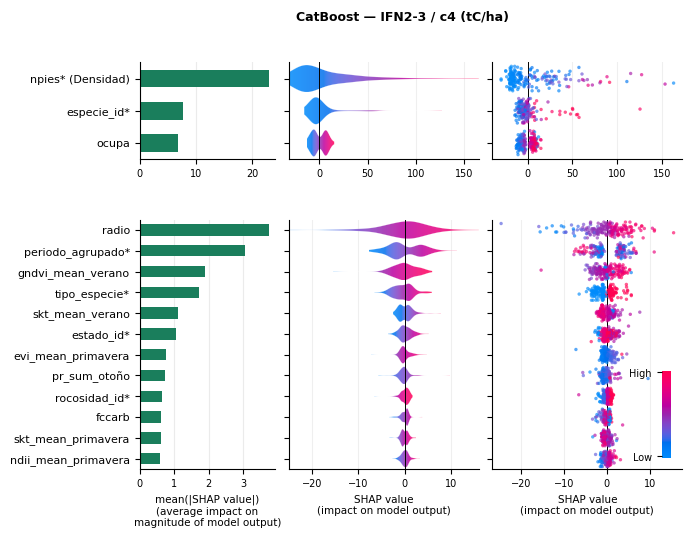

  -> ../../figures/shap_summary_ifn2_3/IFN3/c4/summary_CatBoost.png
  GBDT... [caché] 

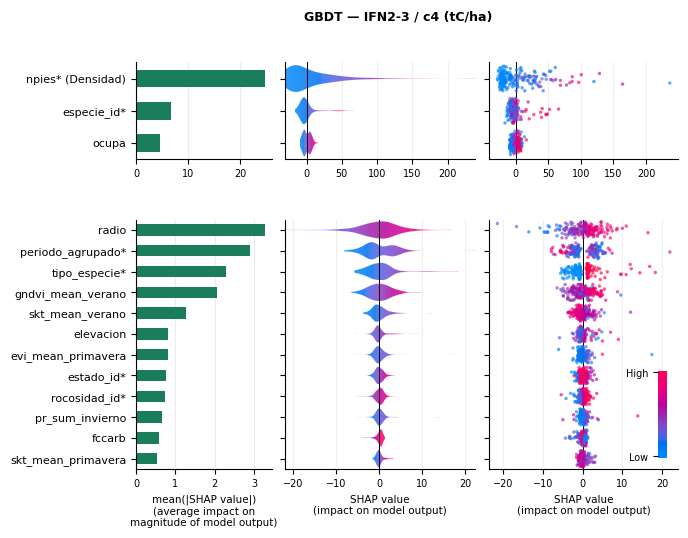

  -> ../../figures/shap_summary_ifn2_3/IFN3/c4/summary_GBDT.png
  LightGBM... [caché] 

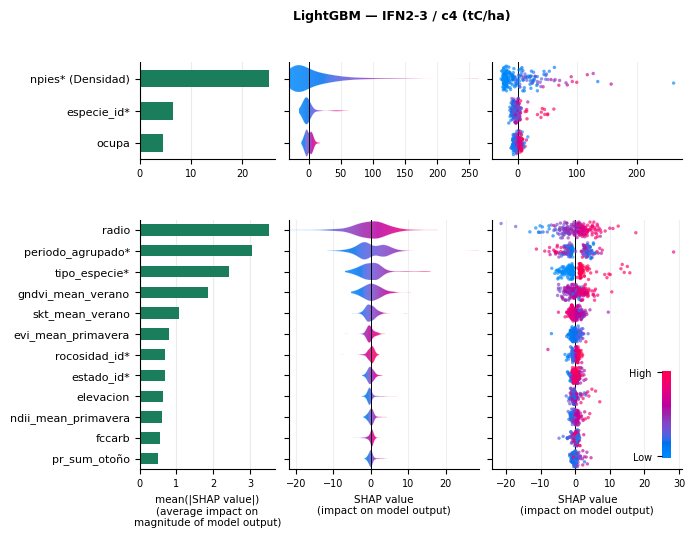

  -> ../../figures/shap_summary_ifn2_3/IFN3/c4/summary_LightGBM.png
  MLP_PyTorch... [caché] 

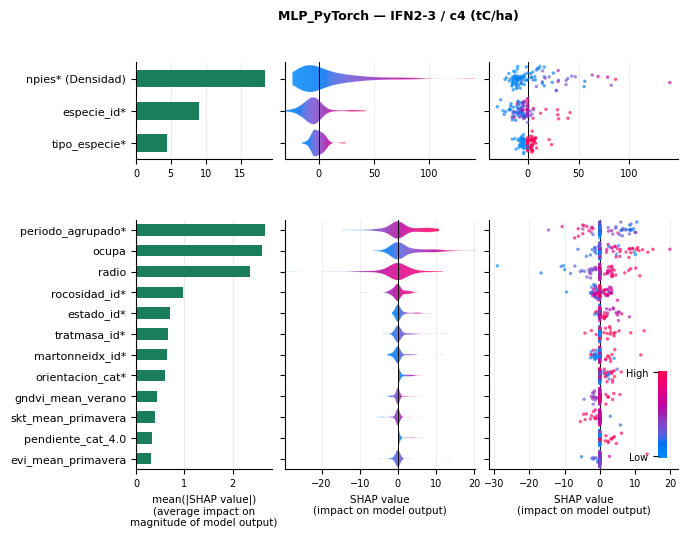

  -> ../../figures/shap_summary_ifn2_3/IFN3/c4/summary_MLP_PyTorch.png
  Random_Forest... [caché] 

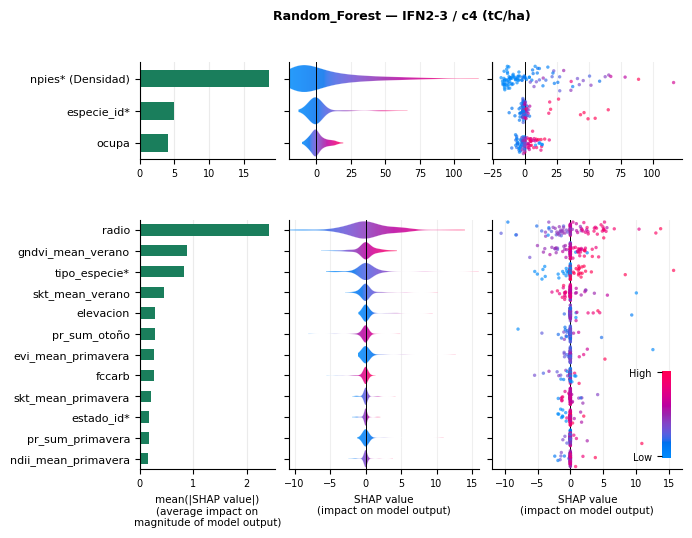

  -> ../../figures/shap_summary_ifn2_3/IFN3/c4/summary_Random_Forest.png
  SVR... [caché] 

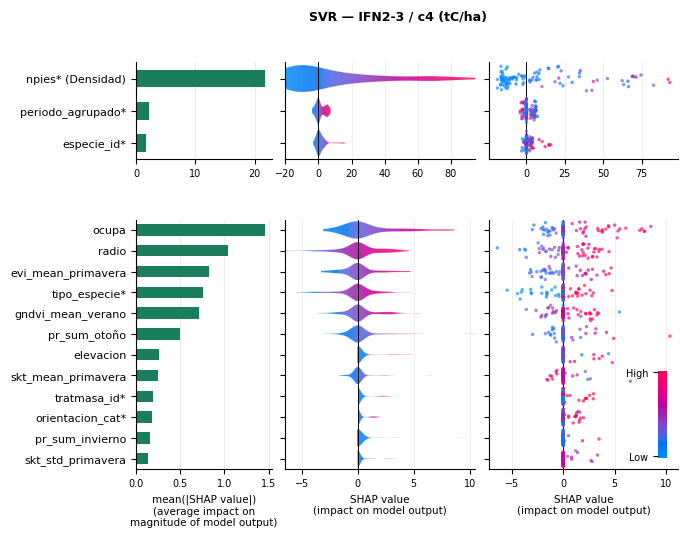

  -> ../../figures/shap_summary_ifn2_3/IFN3/c4/summary_SVR.png
  XGBoost... [caché] 

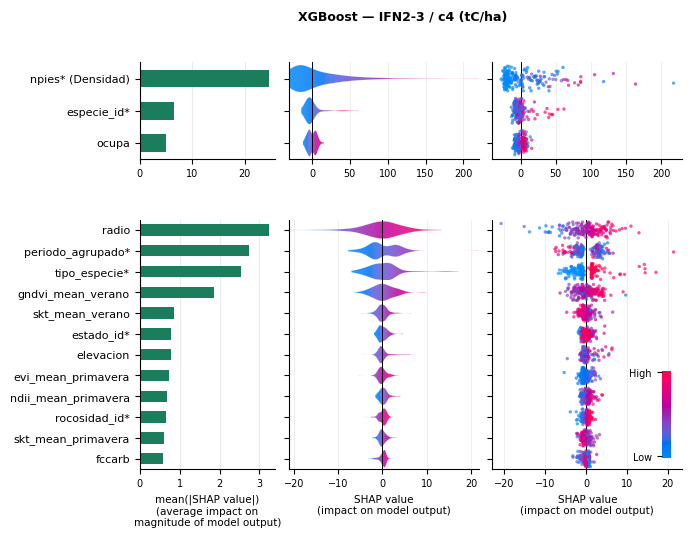

  -> ../../figures/shap_summary_ifn2_3/IFN3/c4/summary_XGBoost.png

SUMMARY PLOTS — IFN2-3 / carbono_bruto4  (9 modelos)
  BaggedDT... [caché] 

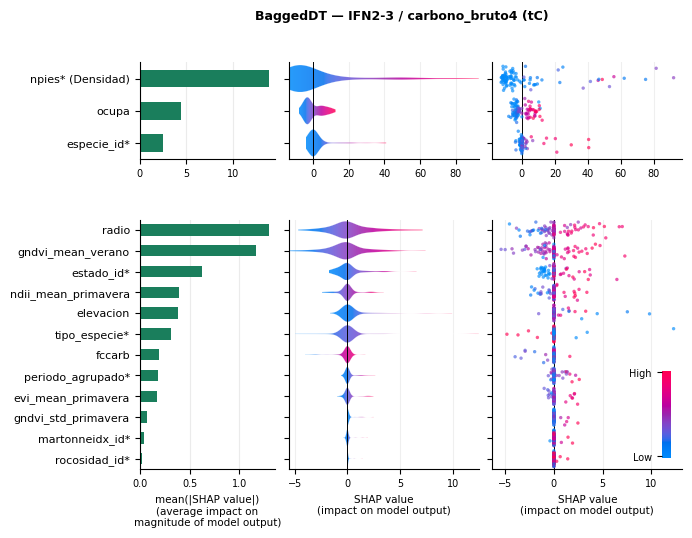

  -> ../../figures/shap_summary_ifn2_3/IFN3/carbono_bruto4/summary_BaggedDT.png
  BayesianNN... [caché] 

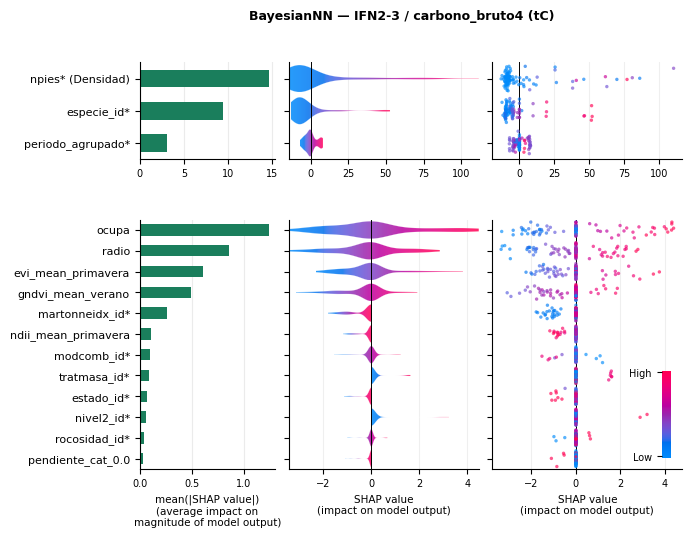

  -> ../../figures/shap_summary_ifn2_3/IFN3/carbono_bruto4/summary_BayesianNN.png
  CatBoost... [caché] 

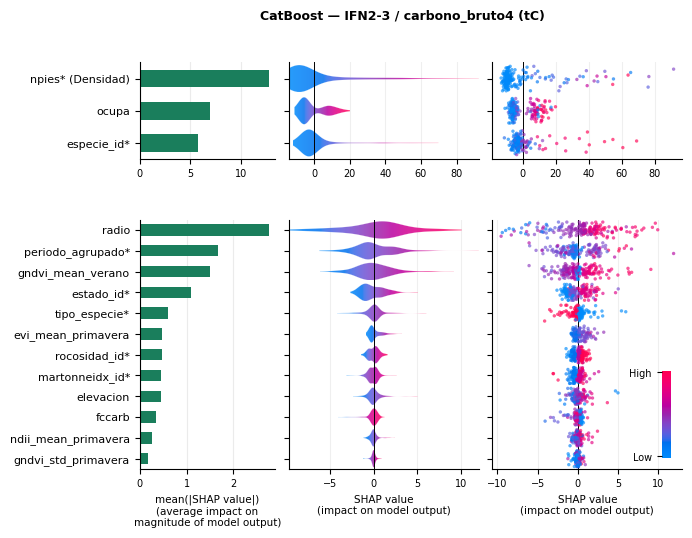

  -> ../../figures/shap_summary_ifn2_3/IFN3/carbono_bruto4/summary_CatBoost.png
  GBDT... [caché] 

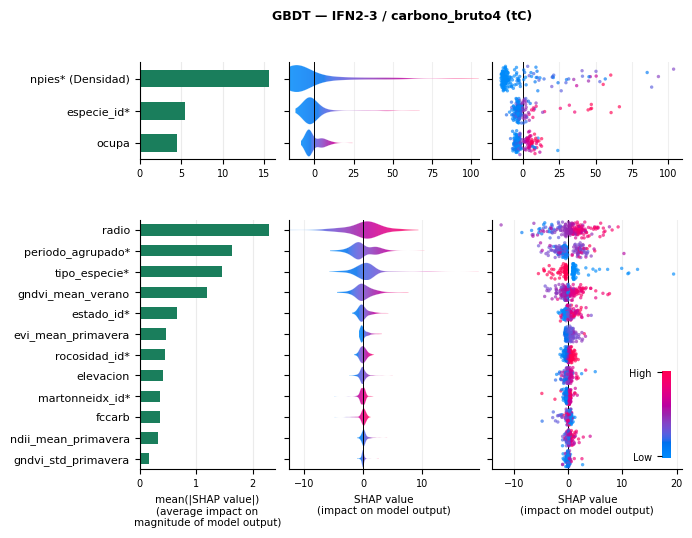

  -> ../../figures/shap_summary_ifn2_3/IFN3/carbono_bruto4/summary_GBDT.png
  LightGBM... [caché] 

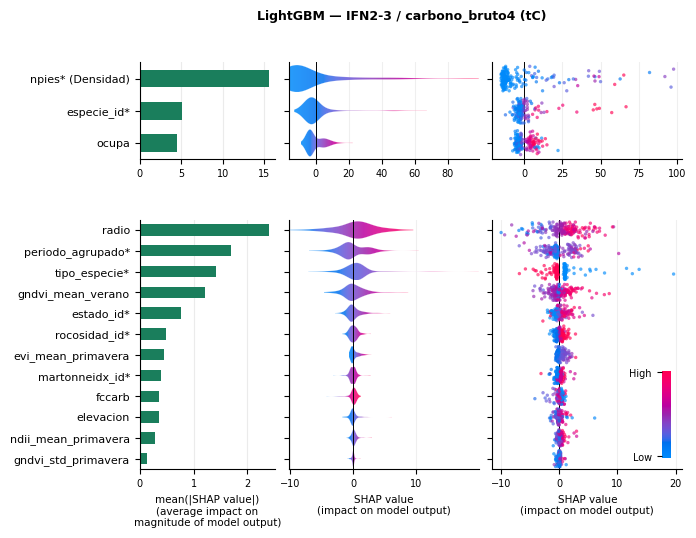

  -> ../../figures/shap_summary_ifn2_3/IFN3/carbono_bruto4/summary_LightGBM.png
  MLP_PyTorch... [caché] 

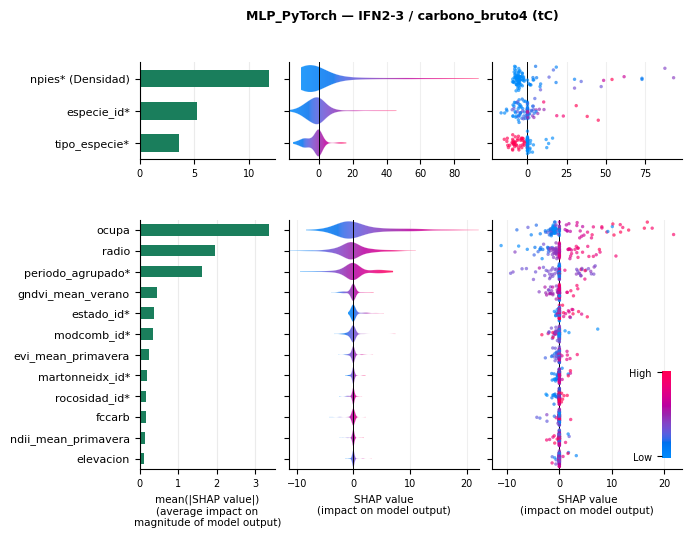

  -> ../../figures/shap_summary_ifn2_3/IFN3/carbono_bruto4/summary_MLP_PyTorch.png
  Random_Forest... [caché] 

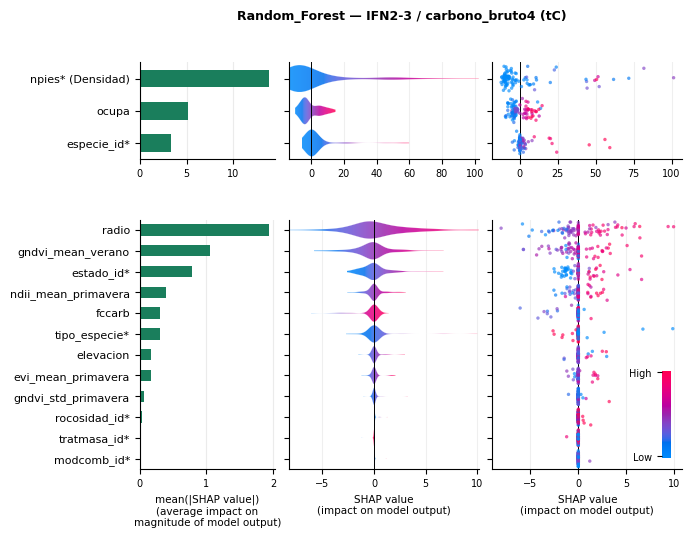

  -> ../../figures/shap_summary_ifn2_3/IFN3/carbono_bruto4/summary_Random_Forest.png
  SVR... [caché] 

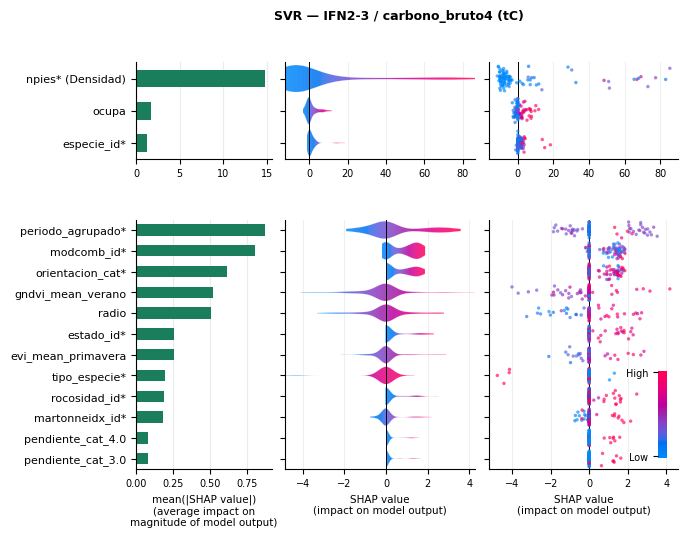

  -> ../../figures/shap_summary_ifn2_3/IFN3/carbono_bruto4/summary_SVR.png
  XGBoost... [caché] 

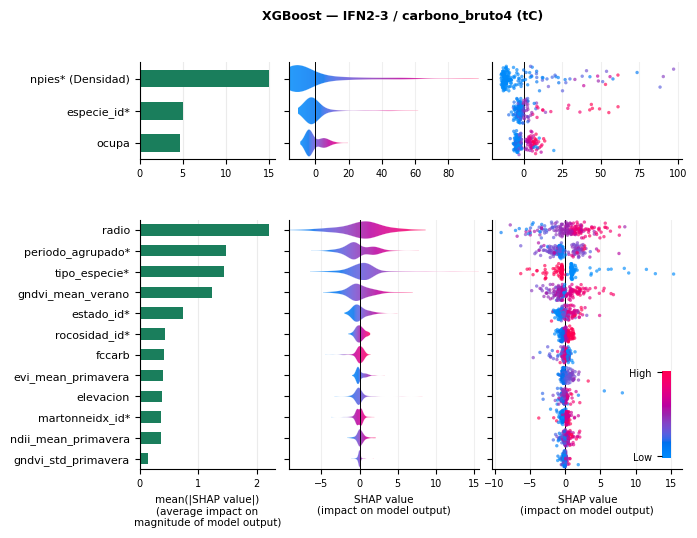

  -> ../../figures/shap_summary_ifn2_3/IFN3/carbono_bruto4/summary_XGBoost.png

Summary plots completados.


In [ ]:
FORCE_REGEN = True   # True → regenera aunque el PNG ya exista

for target_name, cfg in CONFIGS_SF.items():
    X_sample = samples[target_name]['X_sample']
    X_bg     = samples[target_name]['X_bg']
    tm       = samples[target_name]['tm']
    models_dir = cfg['models']
    unit       = cfg['unit']

    model_files = sorted(
        f for f in models_dir.iterdir()
        if f.suffix == '.joblib' and 'training_context' not in f.name
        and 'test_indices' not in f.name
    )

    print(f'\n{"="*65}')
    print(f'SUMMARY PLOTS — IFN2-3 / {target_name}  ({len(model_files)} modelos)')
    print(f'={"="*64}')

    for model_path in model_files:
        model_name = model_path.stem
        save_path  = OUT_SUMMARY / f'IFN2_3/{target_name}/summary_{model_name}.png'
        cache_path = CACHE_SHAP / 'IFN2_3' / 'base' / target_name / f'{model_name}.joblib'

        if save_path.exists() and not FORCE_REGEN:
            print(f'  [OK] {model_name}')
            ipy_display(IPImage(str(save_path)))
            continue

        print(f'  {model_name}...', end=' ')
        try:
            sv, fn, Xt, Xr, bv = load_or_compute_shap(
                model_path, X_sample, X_bg, model_name, cache_path=cache_path
            )
            shap_g, data_g, names_g, colors_g = group_shap(sv, fn, Xr, Xt, tm)
            plot_3panel_summary(
                shap_g, data_g, names_g,
                title     = f'{model_name} — IFN2-3 / {target_name} ({unit})',
                save_path = save_path,
                top_n     = 15,
                unit      = unit,
                var_colors= colors_g,
            )
        except Exception as e:
            print(f'ERROR: {e}')
        finally:
            gc.collect()

print('\nSummary plots completados.')